# JSE Top 40: three-cross-section study

Clusters the FTSE/JSE Top 40 on financial characteristics at **30 June 2025, 31 December 2025 and 30 June 2026**, and asks whether the peer groups, and the changes in them, are real enough to interpret.

There are 41 instruments per date (40 company groups; Investec has two lines), 123 rows and 43 distinct tickers. Each date is clustered independently. The cross-sections overlap heavily, so they are not independent samples, and nothing here predicts returns.

**To run:** select the project `.venv` kernel, then **Run All** (about two minutes). Every run writes a new folder under `experiments/runs/`; nothing is overwritten. All logic lives in the `top40` package, so this notebook and `python -m top40` produce the same results.
Saved figures and tables are retained in [the executed review](../reports/three_cross_section_review.ipynb).


## 1. Choose the feature set and load the data

`FEATURE_SET` is the one switch that matters:

| Name | Status | What it is |
| --- | --- | --- |
| `original10` | archived reference | The ten inputs behind every earlier result. Includes raw share count and EPS, which change mechanically in a share subdivision. |
| `logsize10` | diagnostic | The same ten with log size variables. |
| `invariant8` | candidate | Nothing changes under a subdivision: return, beta, volatility, dividend yield, earnings yield, log market cap, log revenue/cap, log turnover. |
| `market5` | diagnostic | The five scale-free measures only. |

Everything except `original10` was defined after the earlier results had been seen. Treat those sets as pilot-informed, not pre-registered.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd() if (Path.cwd() / "top40").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from IPython.display import display
from top40.study import StudySession

FEATURE_SET = "invariant8"   # or "original10", "logsize10", "market5"
SEED = 42
STABILITY_RUNS = 5

study = StudySession(feature_set=FEATURE_SET, seed=SEED, stability_runs=STABILITY_RUNS)
data = study.load_data()
DATES = study.config["dates"]
display(data[["decision_date", "ticker", "company", "sector_label", *study.feature_set.columns]].head())

Run 20261114T135303-1af915a99076 -> C:\Users\HP\Documents\GitHub\JSE-Top-40-Clustering\experiments\runs\20261114T135303-1af915a99076
Feature set: invariant8 (pilot-informed candidate)


1. Validate and load the model inputs

,decision_date,ticker,company,sector_label,return_1y,beta_1y,annualised_volatility_1y,dividend_yield,earnings_yield_model_clipped,log_market_cap,log_sales_to_cap,log_turnover
0,2025-06-30,ABG,ABSA GROUP LTD,Financials,0.110760,1.181322,0.259287,0.082955,0.146367,11.164307,-0.123116,-2.462765
1,2025-06-30,AGL,ANGLO AMERICAN PLC,Basic Materials,-0.072371,1.481310,0.357798,0.025374,-0.085589,11.749543,-0.063546,-2.558565
2,2025-06-30,ANG,ANGLOGOLD ASHANTI PLC,Basic Materials,0.741958,1.074586,0.455218,0.021488,0.051733,11.605601,-0.592705,-2.484841
3,2025-06-30,ANH,ANHEUSER-BUSCH INBEV SA/N,Consumer Goods,0.146204,0.160389,0.218000,0.015313,0.041734,12.381527,-0.355065,-3.623073
4,2025-06-30,APN,ASPEN PHARMACARE HLD,Health Care,-0.487849,1.190377,0.446735,0.030044,0.082969,10.724943,-0.074577,-2.478563


## 2. Exploratory data analysis

Look at the population, the imputed cases and the feature distributions **before** fitting anything. Scaling is fitted on June 2025 only, so the shaded band in the distribution plot is the June 2025 range; points outside it at later dates stretch the geometry.

,decision_date,instruments,fundamental_imputations,volume_imputations,mixed_basis_volume,economic_groups
0,2025-06-30,41,1,1,0,40
1,2025-12-31,41,1,1,0,40
2,2026-06-30,41,1,0,0,40


,decision_date,feature,raw_missing
4,2025-06-30,earnings_yield_model_clipped,1
6,2025-06-30,log_sales_to_cap,1
7,2025-06-30,log_turnover,1
12,2025-12-31,earnings_yield_model_clipped,1
14,2025-12-31,log_sales_to_cap,1
15,2025-12-31,log_turnover,1
20,2026-06-30,earnings_yield_model_clipped,1
22,2026-06-30,log_sales_to_cap,1


,decision_date,feature,min,50%,max,skew
0,2025-06-30,return_1y,-0.488,0.111,0.751,-0.001
1,2025-06-30,beta_1y,-0.126,1.056,2.387,0.726
2,2025-06-30,annualised_volatility_1y,0.161,0.261,0.610,1.253
3,2025-06-30,dividend_yield,0.000,0.026,0.091,0.531
4,2025-06-30,earnings_yield_model_clipped,-0.589,0.051,0.146,-4.093
5,2025-06-30,log_market_cap,10.532,11.156,12.382,0.884
6,2025-06-30,log_sales_to_cap,-1.314,-0.290,0.740,-0.094
7,2025-06-30,log_turnover,-3.860,-2.559,-2.191,-1.778
8,2025-12-31,return_1y,-0.407,0.195,3.039,1.884
9,2025-12-31,beta_1y,-0.134,0.880,2.349,0.983


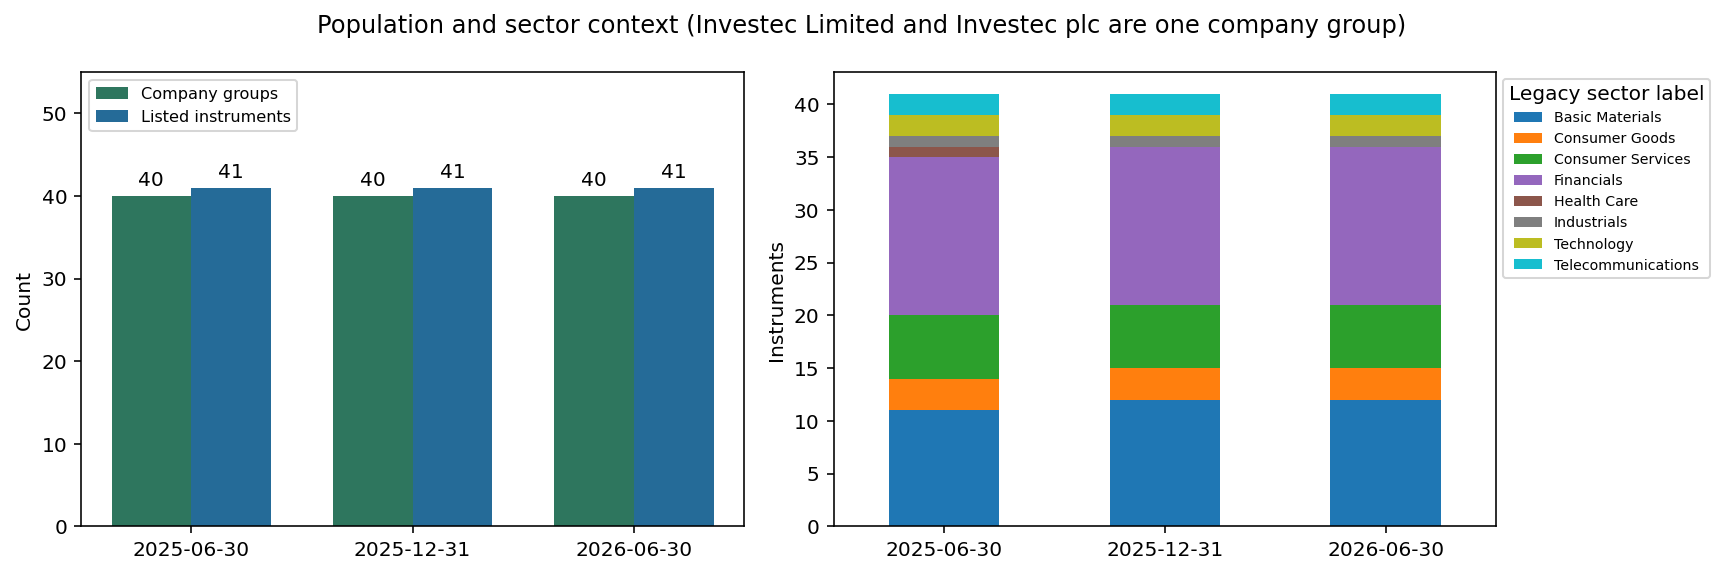

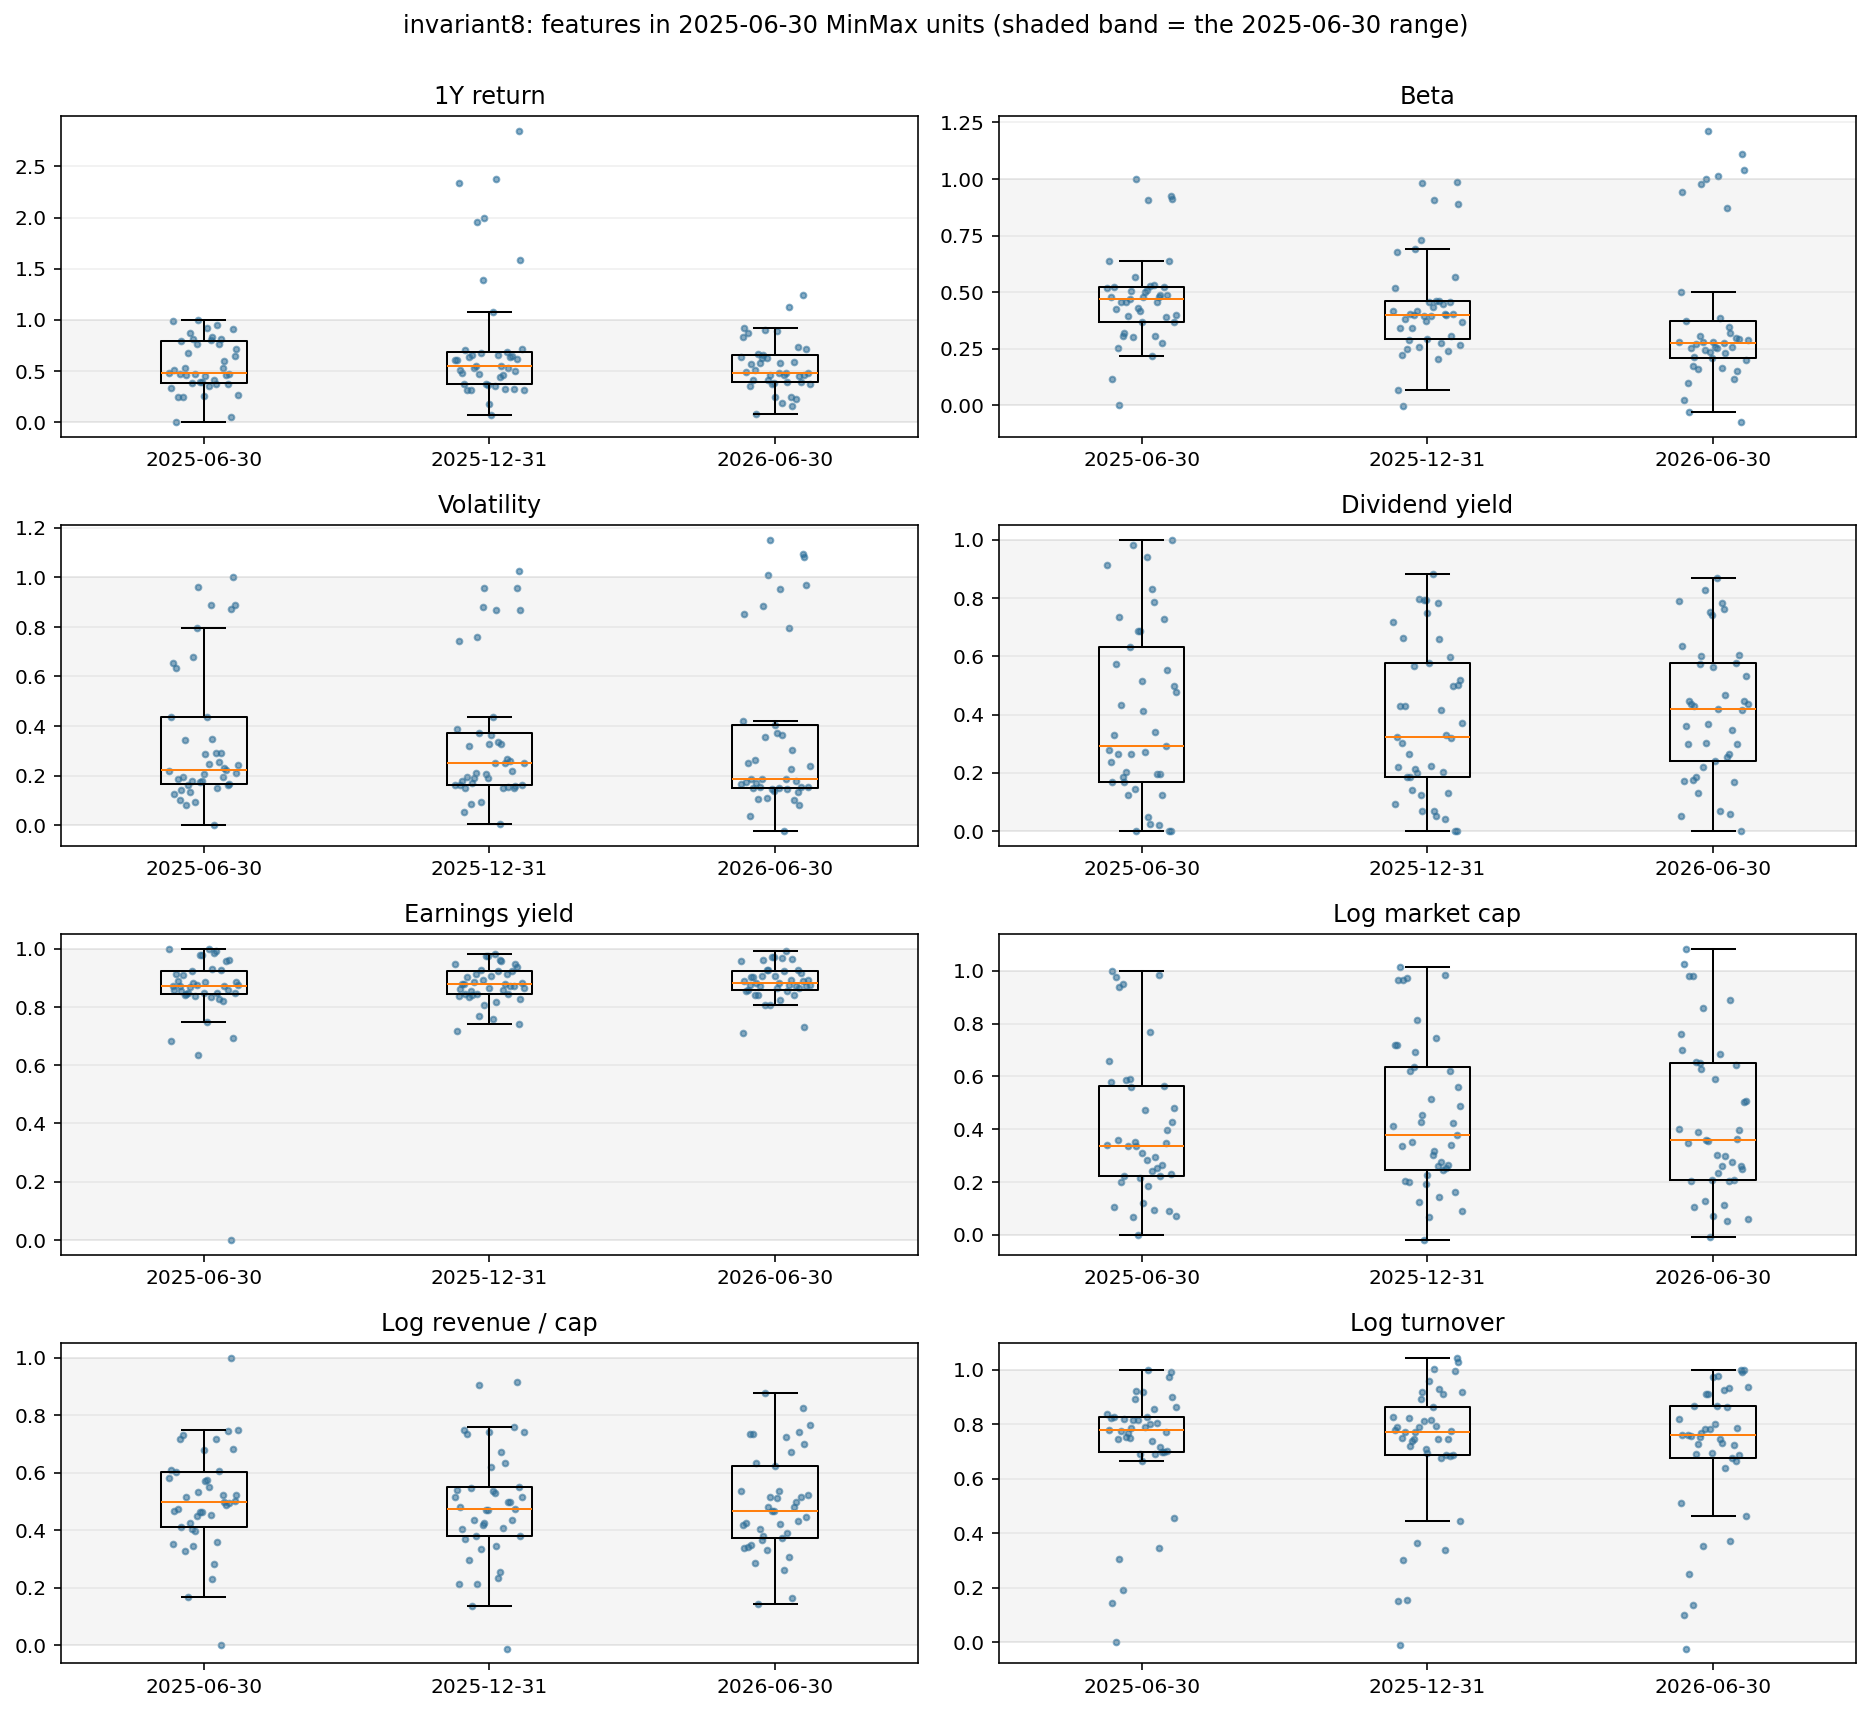

In [2]:
eda = study.explore()
display(eda["population"])
display(eda["missingness"].query("raw_missing > 0"))
display(eda["descriptions"][["decision_date", "feature", "min", "50%", "max", "skew"]].round(3))
study.show("eda/population_and_sectors.png")
study.show("eda/feature_distributions.png")

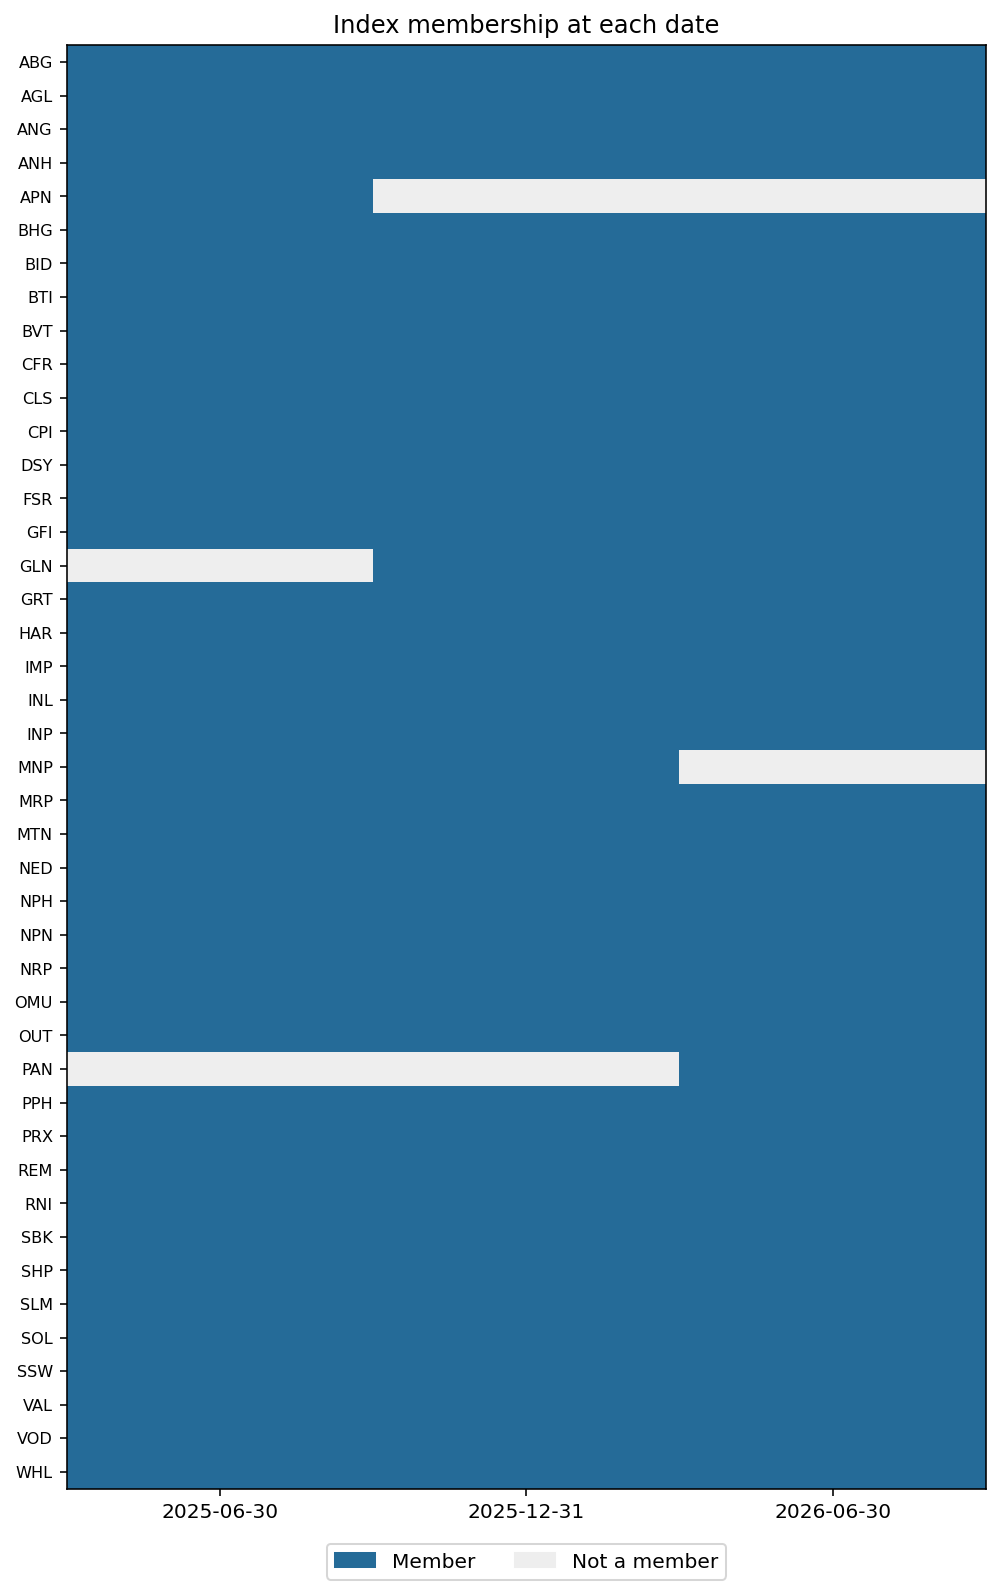

,decision_date,feature_a,feature_b,spearman
0,2025-06-30,beta_1y,annualised_volatility_1y,0.810627


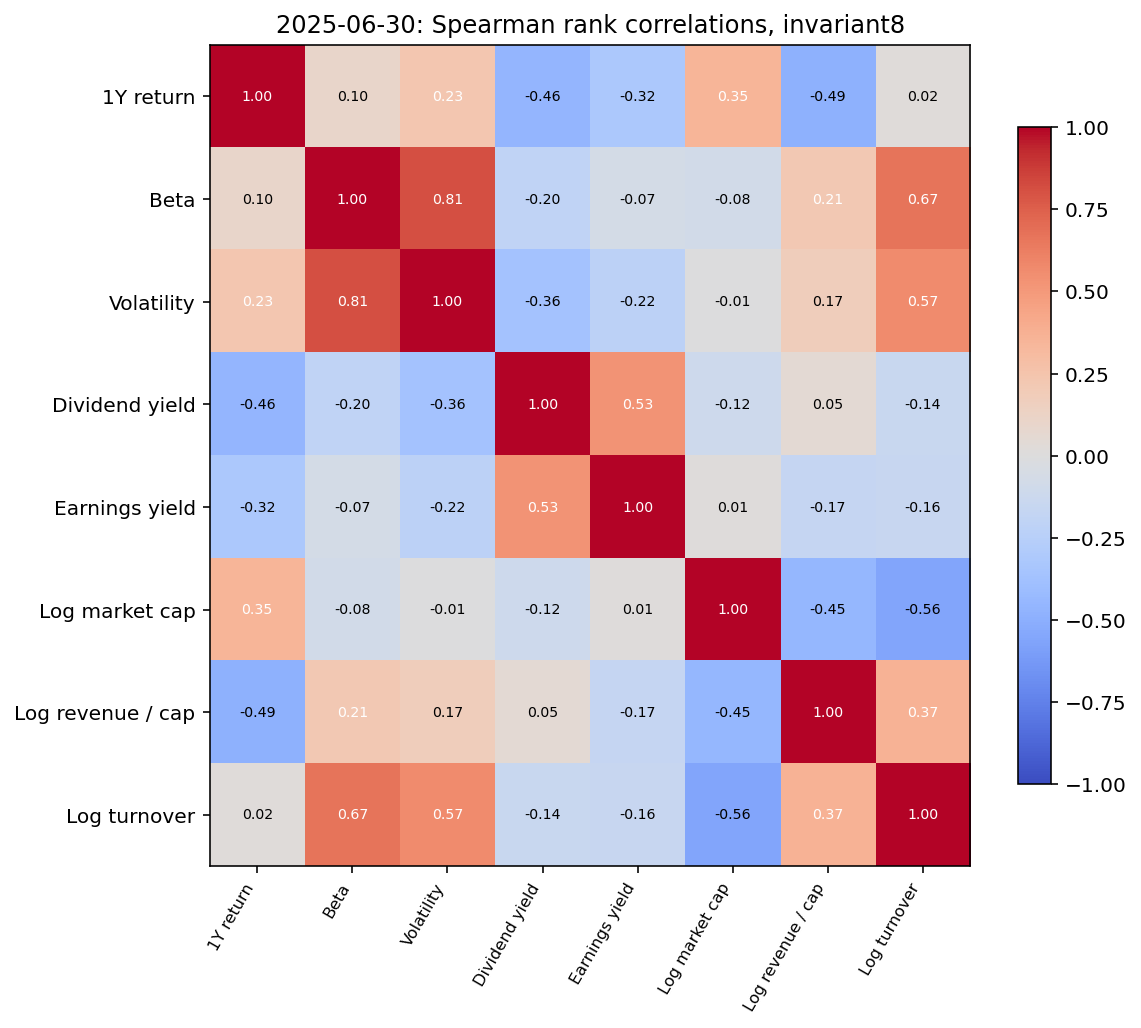

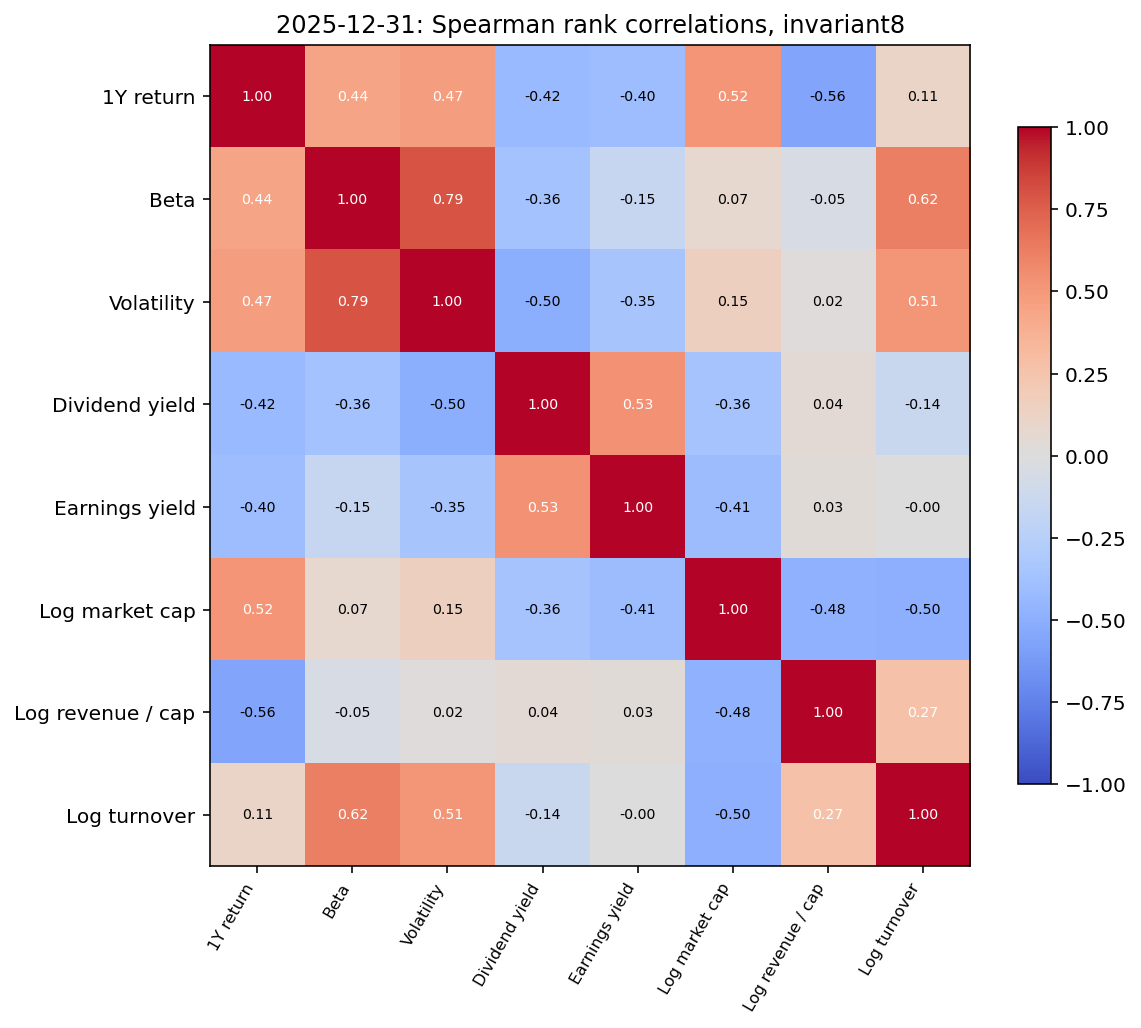

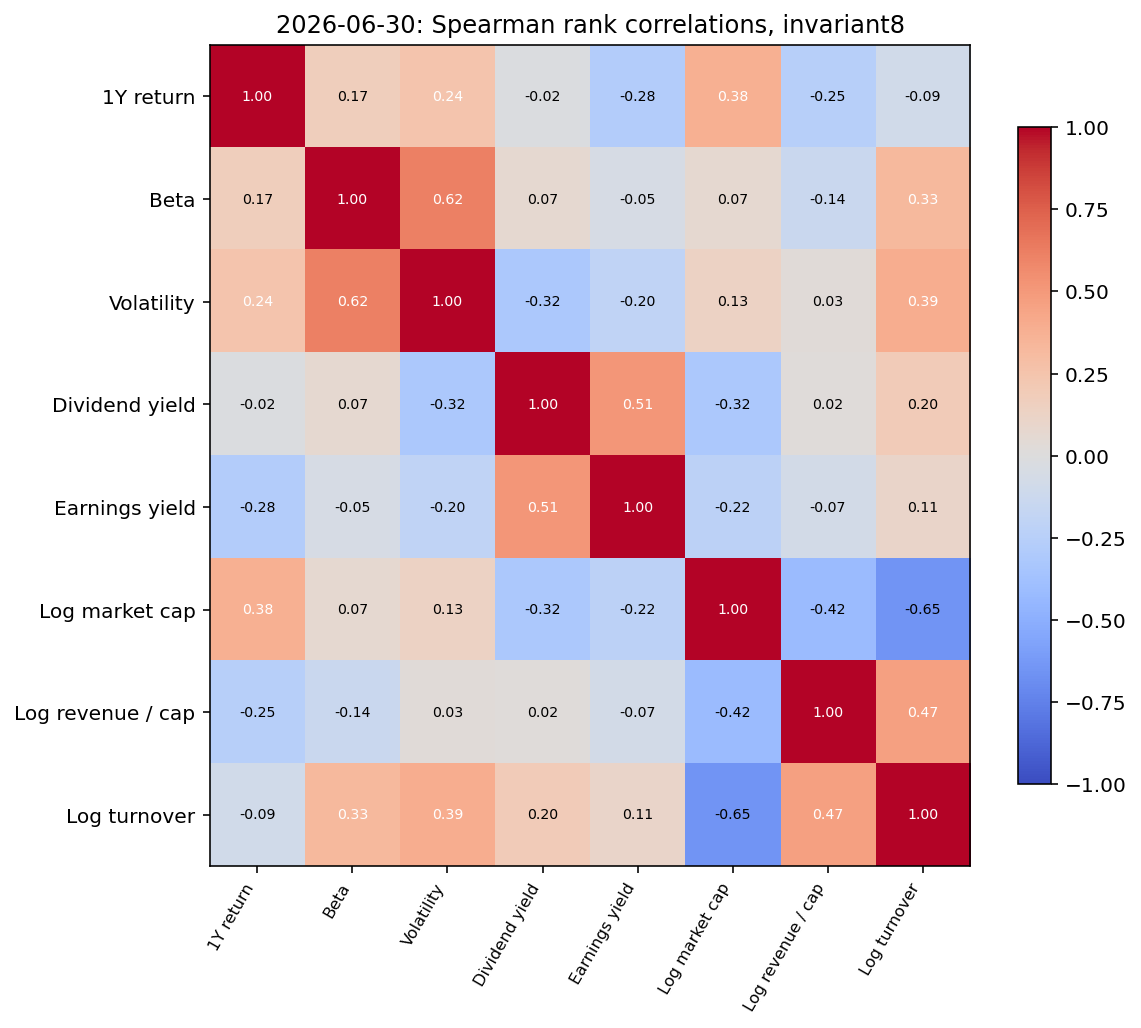

In [3]:
study.show("eda/membership_presence.png")
display(eda["correlated_pairs"])
for date in DATES:
    study.show(f"eda/correlation_{date}.png")

## 3. Feature validity

Three checks on whether the feature definitions are creating structure.

**Share basis.** Any share count that moves more than 5% between dates, raw and after restating to a common basis using `data/reference/corporate_actions.csv`. Naspers subdivided five-for-one on 6 October 2025: its raw count rises 4.57x while the common-basis count falls to 0.91x.

**Dominance.** The largest share of total scaled variance carried by one feature. Far above the even share means one feature is driving the distances at that date.

**Ablation.** The same recipe on every feature set: the t-SNE baseline, and Ward clustering directly on the scaled features (deterministic, no embedding). Compare cluster sizes, seed agreement, agreement between feature sets, and how many instruments shift. Silhouette and Davies-Bouldin are computed in each set's own space, so do not compare them across feature sets.

,ticker,before,after,shares_ratio_raw,shares_ratio_common_basis,eps_ratio_raw,eps_ratio_common_basis,market_cap_ratio,recorded_subdivision
0,NPN,2025-06-30,2025-12-31,4.565,0.913,0.186,0.931,0.914,True


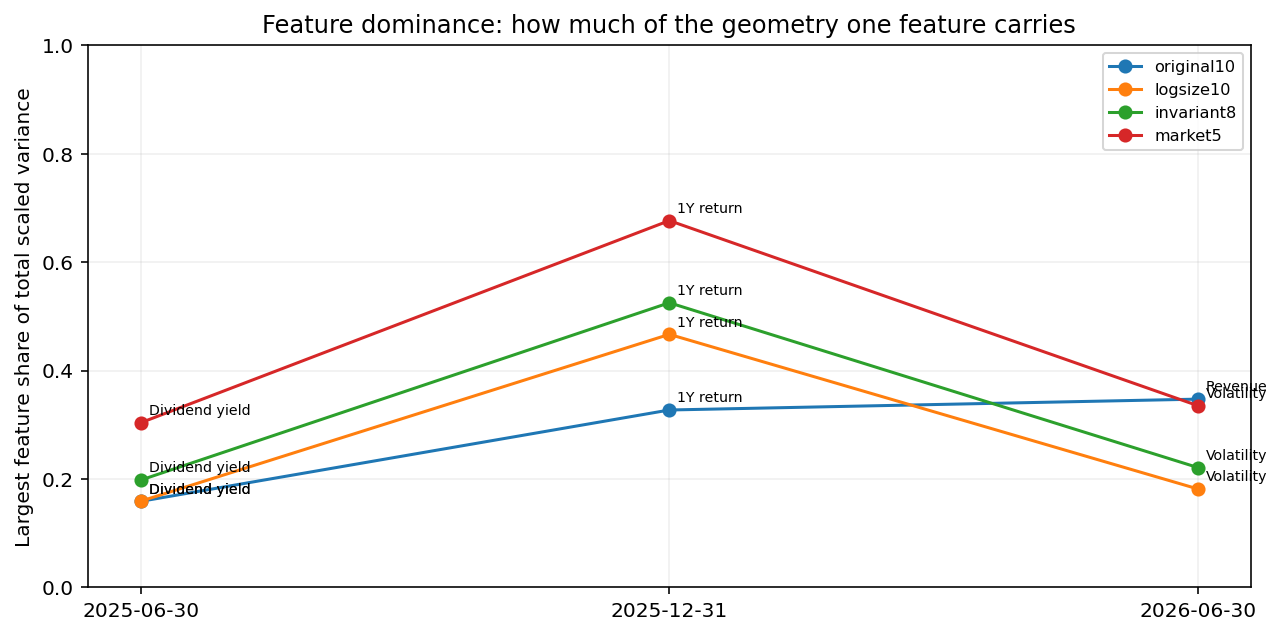

,feature_set,decision_date,top_feature,top_feature_label,top_variance_share,even_share,max_scaled_value,min_scaled_value,widest_feature
0,original10,2025-06-30,dividend_yield,Dividend yield,0.159,0.100,1.000,0.000,annualised_volatility_1y
1,original10,2025-12-31,return_1y,1Y return,0.327,0.100,3.631,-0.003,revenue_zar_model
2,original10,2026-06-30,revenue_zar_model,Revenue,0.347,0.100,3.852,-0.075,revenue_zar_model
3,logsize10,2025-06-30,dividend_yield,Dividend yield,0.159,0.100,1.000,0.000,annualised_volatility_1y
4,logsize10,2025-12-31,return_1y,1Y return,0.467,0.100,2.847,-0.029,return_1y
5,logsize10,2026-06-30,annualised_volatility_1y,Volatility,0.182,0.100,1.311,-0.113,log_revenue
6,invariant8,2025-06-30,dividend_yield,Dividend yield,0.198,0.125,1.000,0.000,annualised_volatility_1y
7,invariant8,2025-12-31,return_1y,1Y return,0.525,0.125,2.847,-0.019,return_1y
8,invariant8,2026-06-30,annualised_volatility_1y,Volatility,0.221,0.125,1.244,-0.075,return_1y
9,market5,2025-06-30,dividend_yield,Dividend yield,0.304,0.200,1.000,0.000,annualised_volatility_1y


In [4]:
audit = study.audit_features()
display(audit["share_basis"].round(3))
study.show("feature_audit/feature_dominance.png")
display(audit["dominance"].round(3))

In [5]:
quality_columns = ["feature_set", "recipe", "decision_date", "smallest_cluster", "largest_cluster",
                   "singleton_clusters", "silhouette_features", "mean_seed_ari"]
display(audit["quality"][quality_columns].round(3))
display(audit["cross_set_agreement"].pivot_table(index=["recipe", "feature_set_a", "feature_set_b"],
                                                  columns="decision_date", values="ari").round(3))
display(audit["shift_counts"])
# Which instruments are called stable or shifted depends on the feature set:
status = audit["instrument_status"].set_index("ticker")
display(status[status.nunique(axis=1) > 1])

,feature_set,recipe,decision_date,smallest_cluster,largest_cluster,singleton_clusters,silhouette_features,mean_seed_ari
0,original10,tsne_hierarchical,2025-06-30,2,8,0,0.182,0.727
1,original10,tsne_hierarchical,2025-12-31,1,7,1,0.177,0.920
2,original10,tsne_hierarchical,2026-06-30,2,9,0,0.223,0.934
3,original10,ward_features,2025-06-30,1,12,1,0.242,NaN
4,original10,ward_features,2025-12-31,1,12,2,0.285,NaN
5,original10,ward_features,2026-06-30,1,14,3,0.253,NaN
6,logsize10,tsne_hierarchical,2025-06-30,1,8,1,0.164,0.732
7,logsize10,tsne_hierarchical,2025-12-31,1,8,1,0.256,0.986
8,logsize10,tsne_hierarchical,2026-06-30,2,9,0,0.211,0.770
9,logsize10,ward_features,2025-06-30,1,10,2,0.188,NaN


decision_date                                  2025-06-30  2025-12-31  \
recipe            feature_set_a feature_set_b                           
tsne_hierarchical invariant8    market5             0.504       0.444   
                  logsize10     invariant8          0.548       0.532   
                                market5             0.307       0.402   
                  original10    invariant8          0.560       0.587   
                                logsize10           0.560       0.644   
                                market5             0.461       0.408   
ward_features     invariant8    market5             0.377       0.431   
                  logsize10     invariant8          0.316       0.396   
                                market5             0.231       0.388   
                  original10    invariant8          0.324       0.391   
                                logsize10           0.550       0.586   
                                market5             0.290       0.294   

decision_date                                  2026-06-30  
recipe            feature_set_a feature_set_b              
tsne_hierarchical invariant8    market5             0.649  
                  logsize10     invariant8          0.516  
                                market5             0.456  
                  original10    invariant8          0.622  
                                logsize10           0.727  
                                market5             0.507  
ward_features     invariant8    market5             0.414  
                  logsize10     invariant8          0.538  
                                market5             0.371  
                  original10    invariant8          0.361  
                                logsize10           0.426  
                                market5             0.265

,feature_set,recipe,stable,shifted,membership gap
0,original10,tsne_hierarchical,21,18,4
1,original10,ward_features,26,13,4
2,logsize10,tsne_hierarchical,20,19,4
3,logsize10,ward_features,23,16,4
4,invariant8,tsne_hierarchical,22,17,4
5,invariant8,ward_features,20,19,4
6,market5,tsne_hierarchical,17,22,4
7,market5,ward_features,6,33,4


,original10|tsne_hierarchical,original10|ward_features,logsize10|tsne_hierarchical,logsize10|ward_features,invariant8|tsne_hierarchical,invariant8|ward_features,market5|tsne_hierarchical,market5|ward_features
ticker,,,,,,,,
ABG,shifted,stable,shifted,shifted,shifted,shifted,shifted,shifted
AGL,shifted,shifted,shifted,shifted,shifted,shifted,stable,shifted
ANG,stable,stable,stable,stable,stable,shifted,stable,stable
ANH,stable,stable,stable,stable,stable,stable,shifted,shifted
BHG,stable,stable,stable,shifted,stable,stable,shifted,shifted
BID,shifted,stable,shifted,stable,stable,stable,stable,shifted
BTI,stable,stable,stable,stable,stable,stable,shifted,shifted
BVT,stable,stable,shifted,stable,shifted,shifted,stable,shifted
CFR,stable,shifted,stable,stable,stable,stable,shifted,shifted


## 4. Models

The comparison table covers PCA, t-SNE and UMAP with hierarchical, K-Means and DBSCAN clustering at the representative seed. Two **primary models** get full outputs over every seed:

- `baseline`: t-SNE (perplexity 5) then average-linkage Manhattan hierarchy, k=8. This is the recovered recipe of the original paper and is the `tsne_hierarchical` row.
- `umap_sensitivity`: UMAP (3 neighbours, min_dist 0.01) with the same hierarchy. A fixed sensitivity, not a promoted model.

Read silhouette (higher is better) and Davies-Bouldin (lower is better) together, and read the feature-space scores before the embedding scores: t-SNE and UMAP pull points into tight groups, so embedding scores look good even without structure.

,decision_date,model,n_clusters,coverage,smallest_cluster,largest_cluster,silhouette_features,davies_bouldin_features,silhouette_embedding,davies_bouldin_embedding
0,2025-06-30,pca_dbscan,2,0.756,3,28,0.458,0.586,0.593,0.402
1,2025-06-30,pca_hierarchical,8,1.000,1,14,0.206,1.051,0.375,0.541
2,2025-06-30,pca_kmeans,8,1.000,2,7,0.135,1.422,0.369,0.748
3,2025-06-30,tsne_dbscan,5,1.000,3,15,0.243,1.154,0.469,0.561
4,2025-06-30,tsne_hierarchical,8,1.000,3,8,0.195,1.307,0.532,0.561
5,2025-06-30,tsne_kmeans,8,1.000,4,8,0.201,1.300,0.522,0.590
6,2025-06-30,umap_dbscan,3,1.000,3,30,-0.048,1.484,0.278,0.684
7,2025-06-30,umap_hierarchical,8,1.000,3,8,0.142,1.151,0.467,0.601
8,2025-06-30,umap_kmeans,8,1.000,3,8,0.152,1.260,0.441,0.658
9,2025-06-30,umap_sensitivity,8,1.000,2,9,0.151,1.153,0.685,0.385


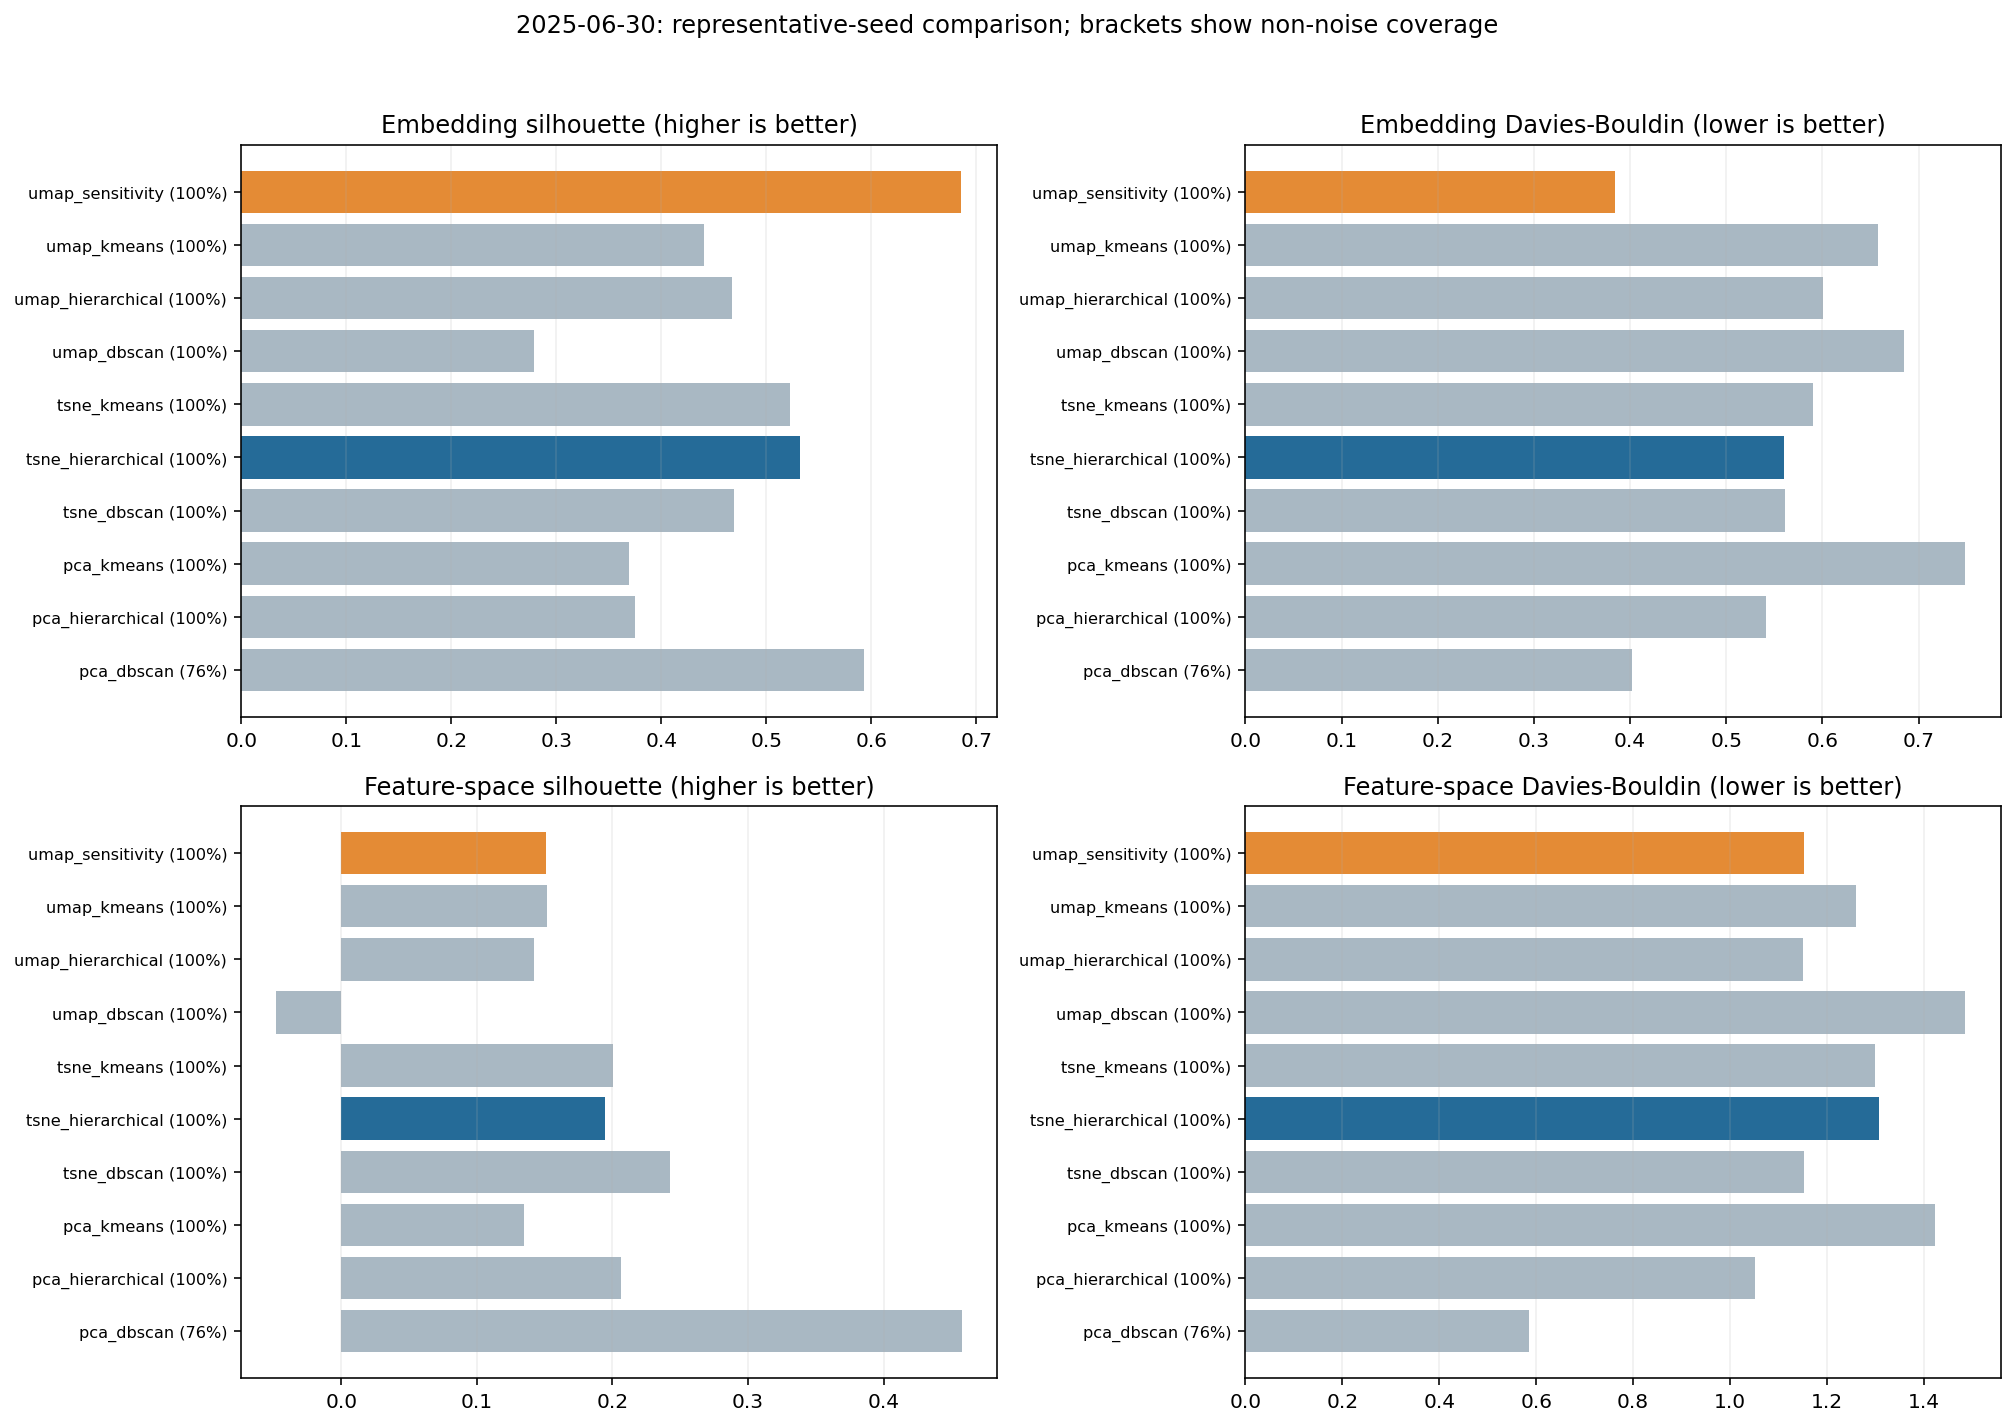

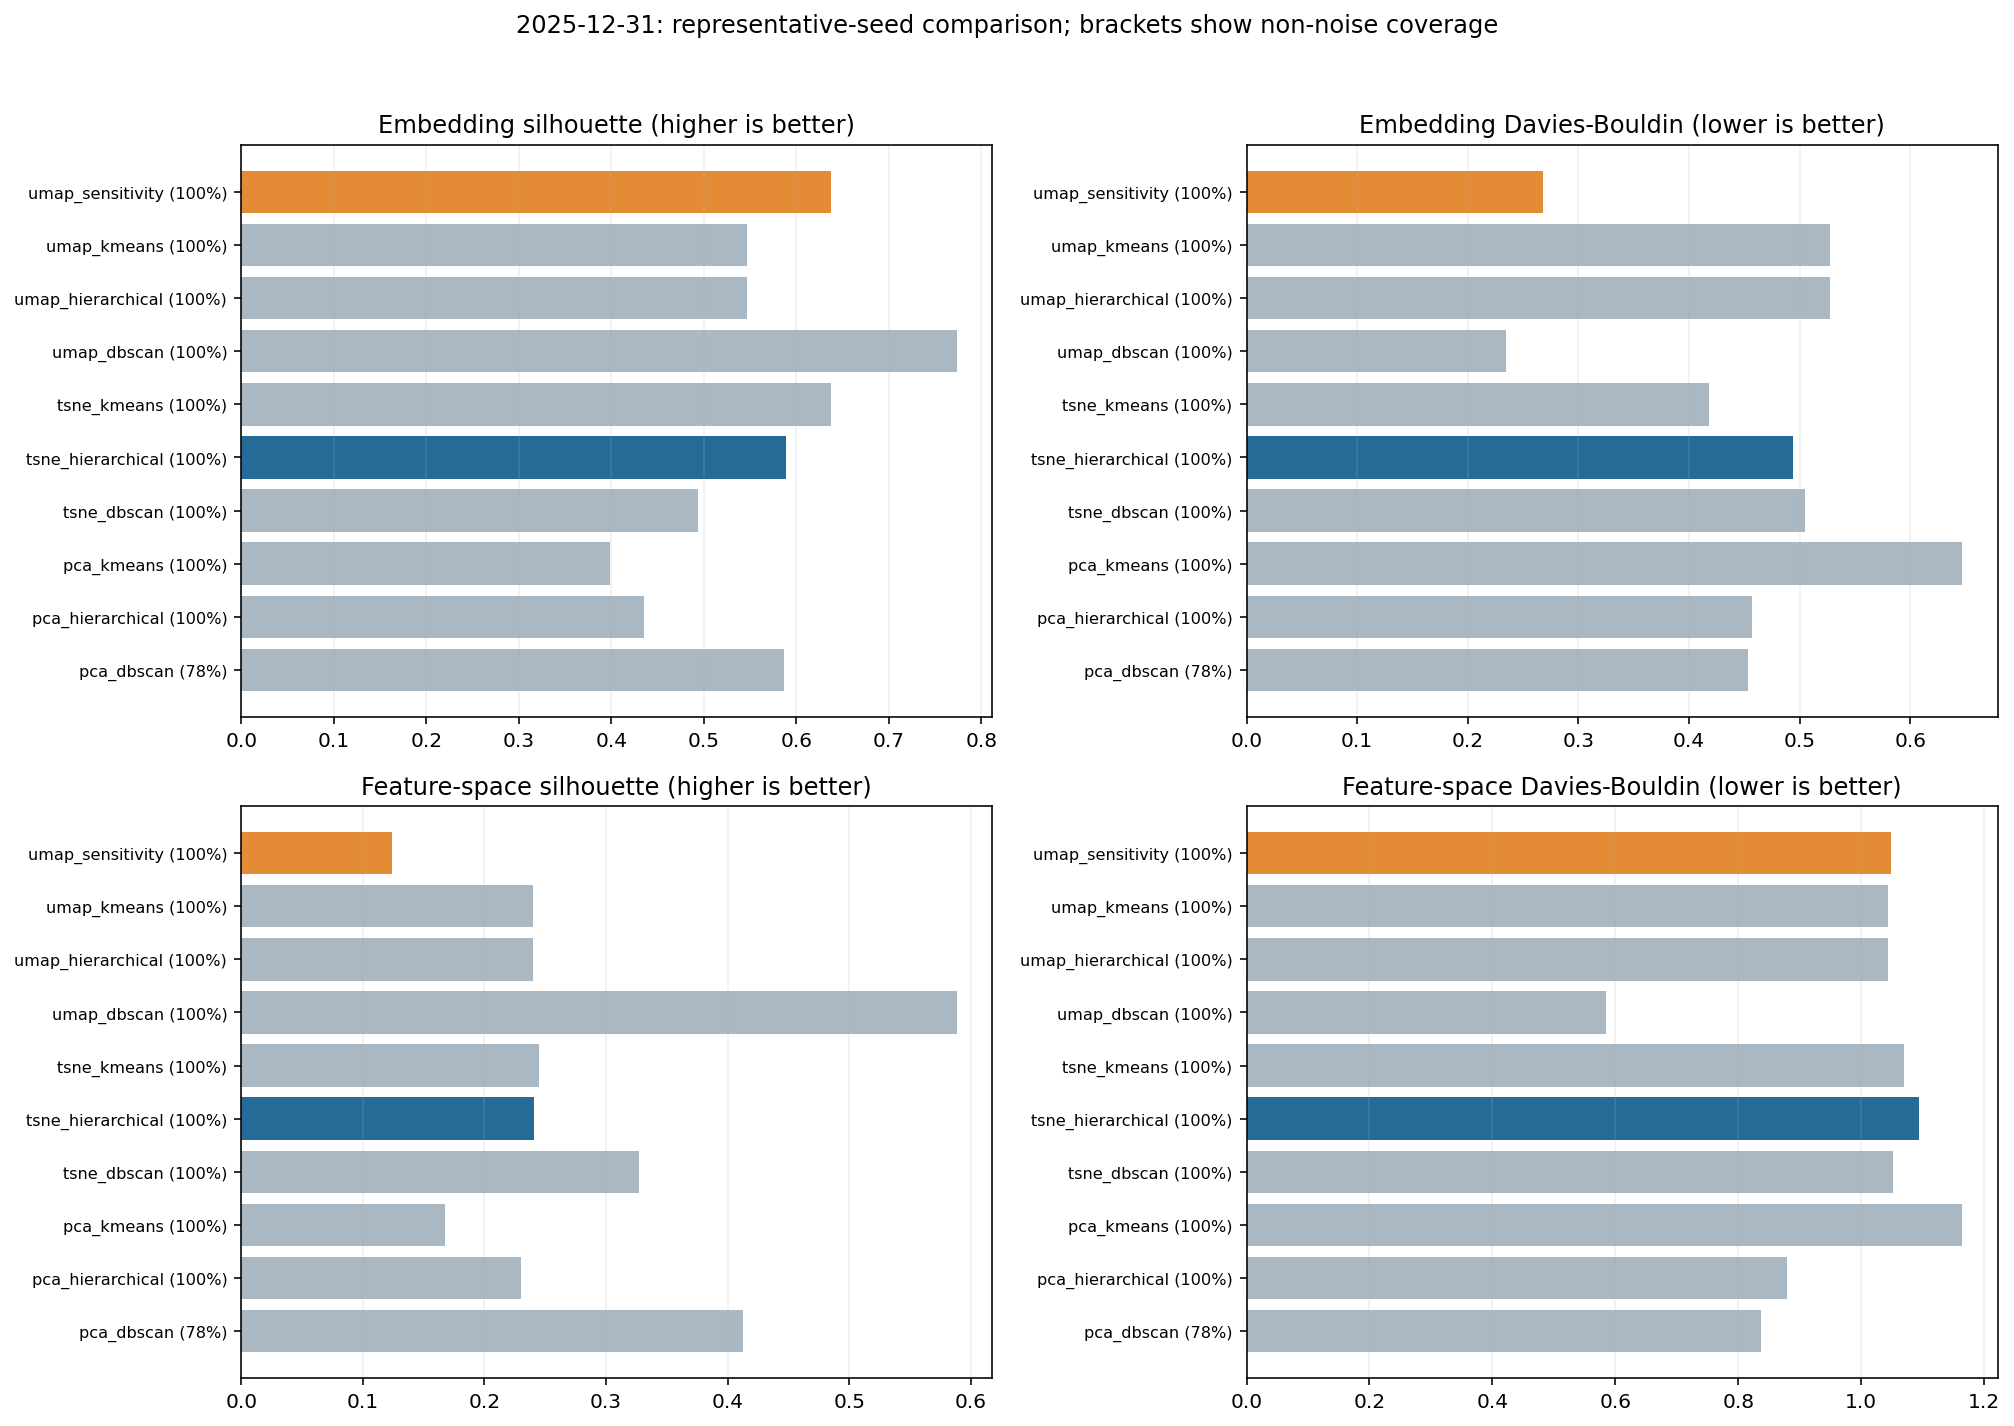

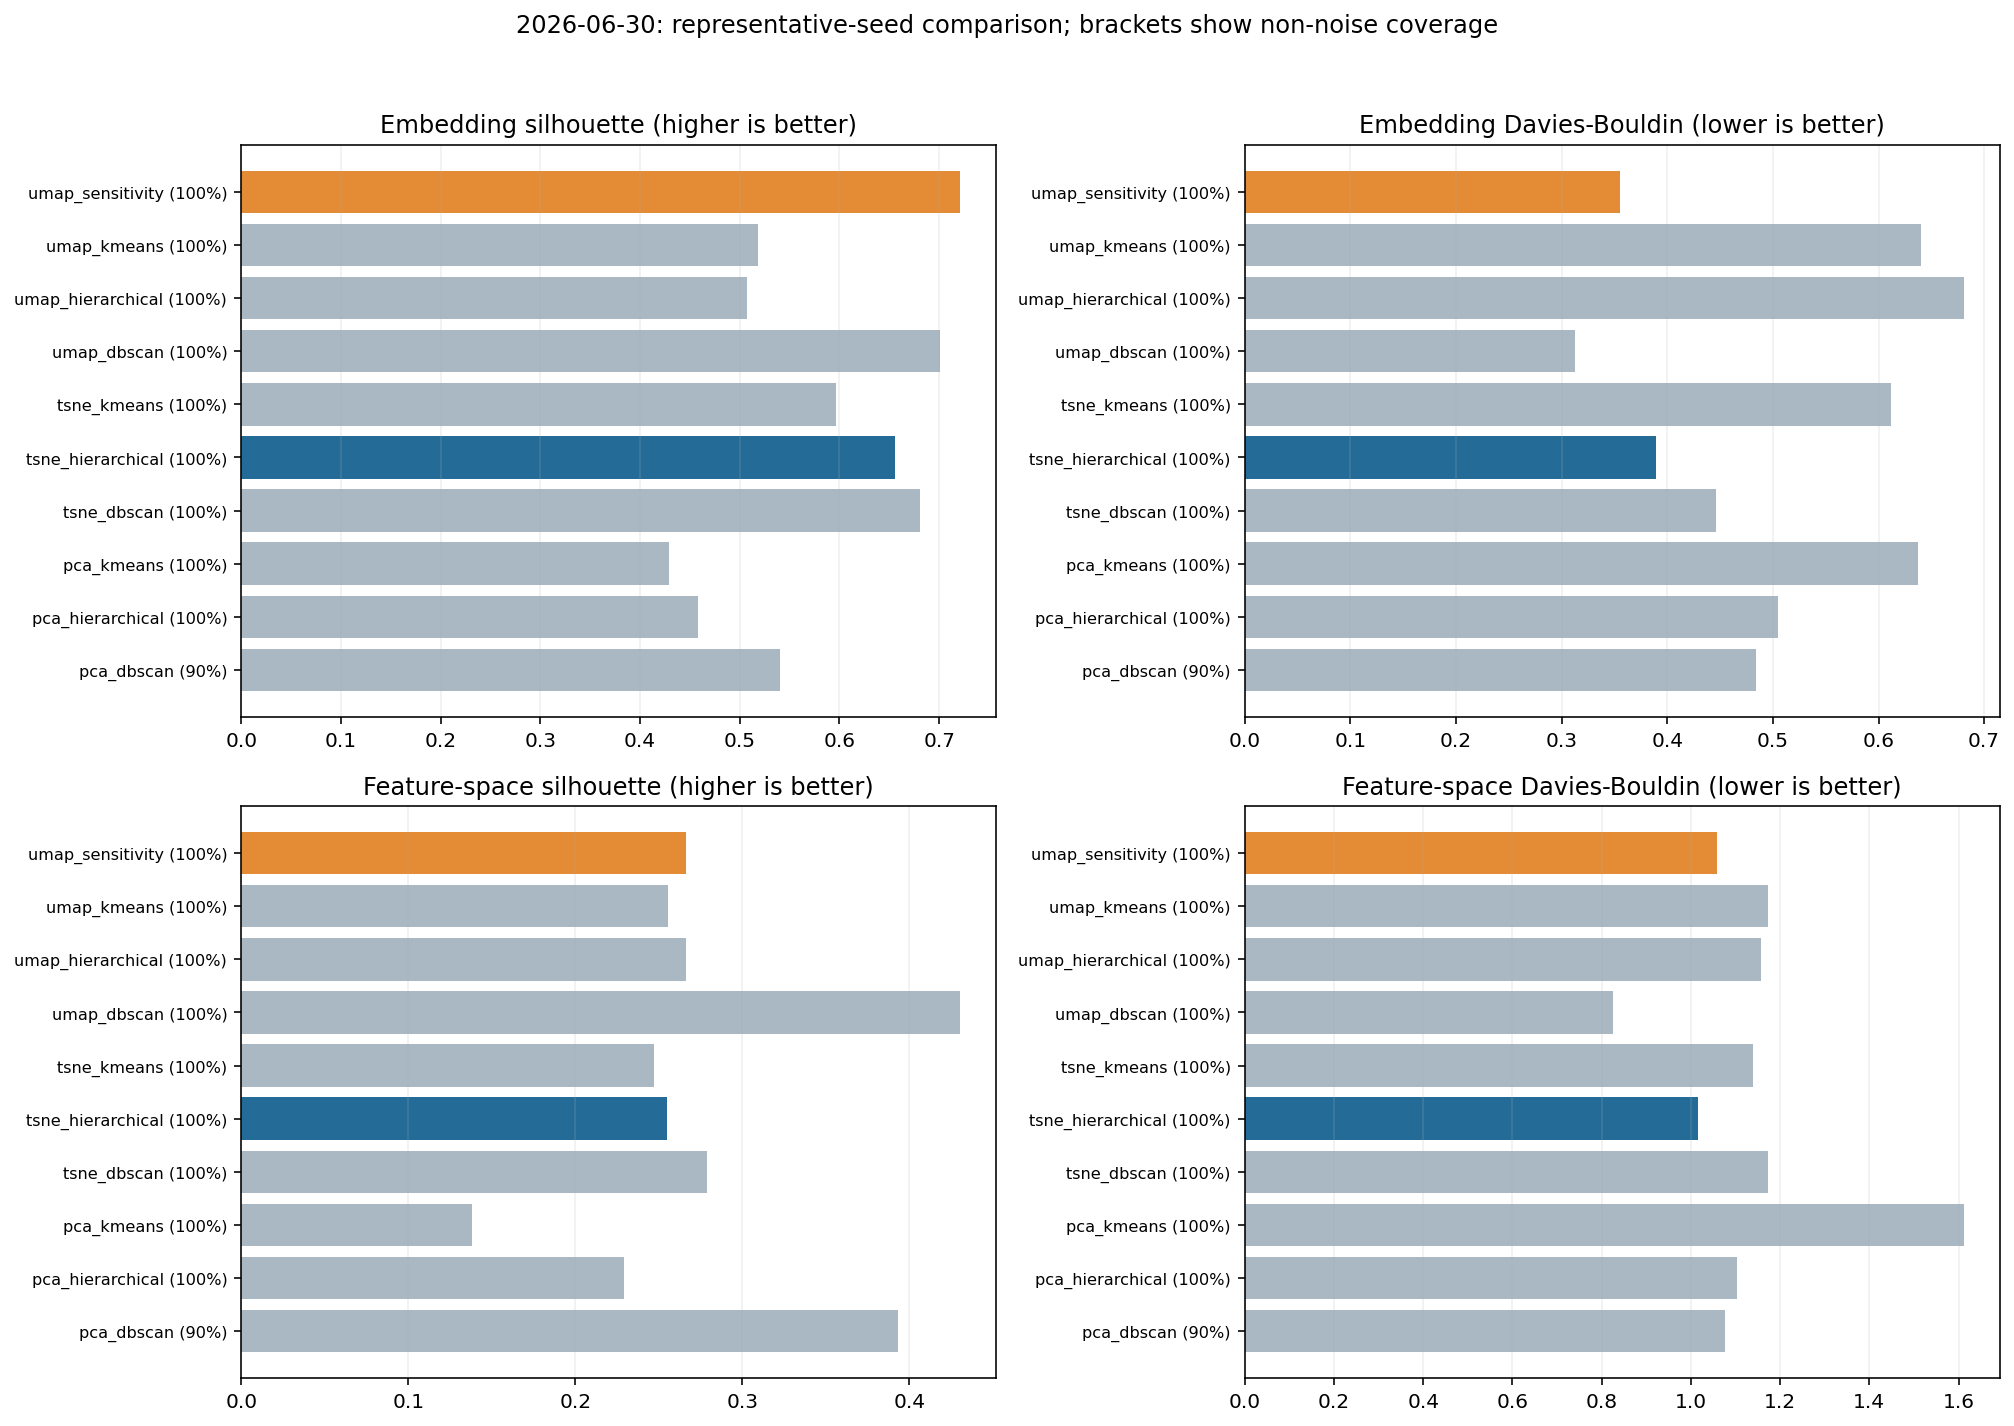

In [6]:
comparison = study.fit_models()
display(comparison[["decision_date", "model", "n_clusters", "coverage", "smallest_cluster", "largest_cluster",
                    "silhouette_features", "davies_bouldin_features",
                    "silhouette_embedding", "davies_bouldin_embedding"]].round(3))
for date in DATES:
    study.show(f"model_quality_{date}.png")

### Maps, profiles and dendrograms

Change `VIEW_DATE` to look at another date. Each map is an independent fit: axes and cluster numbers do not carry over between dates. The profile heatmap (cluster median minus same-date median) is the most direct description of what a cluster is.

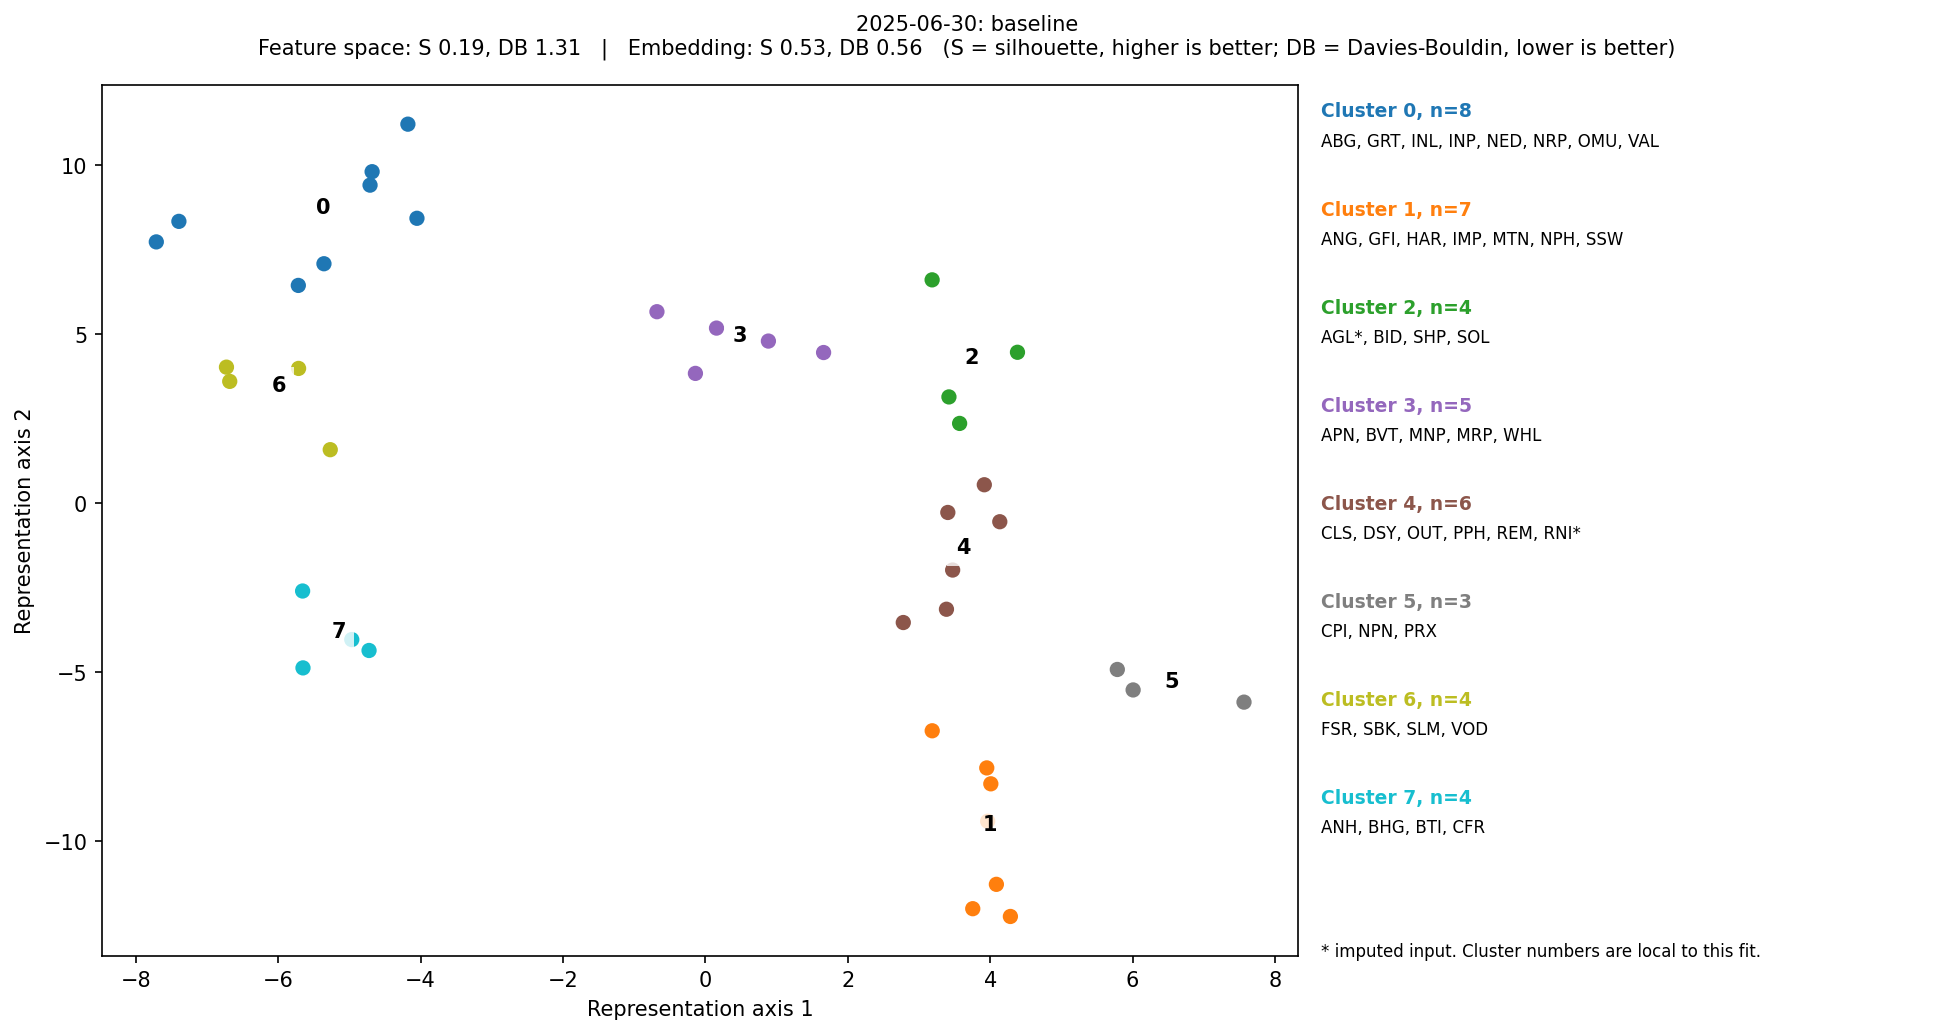

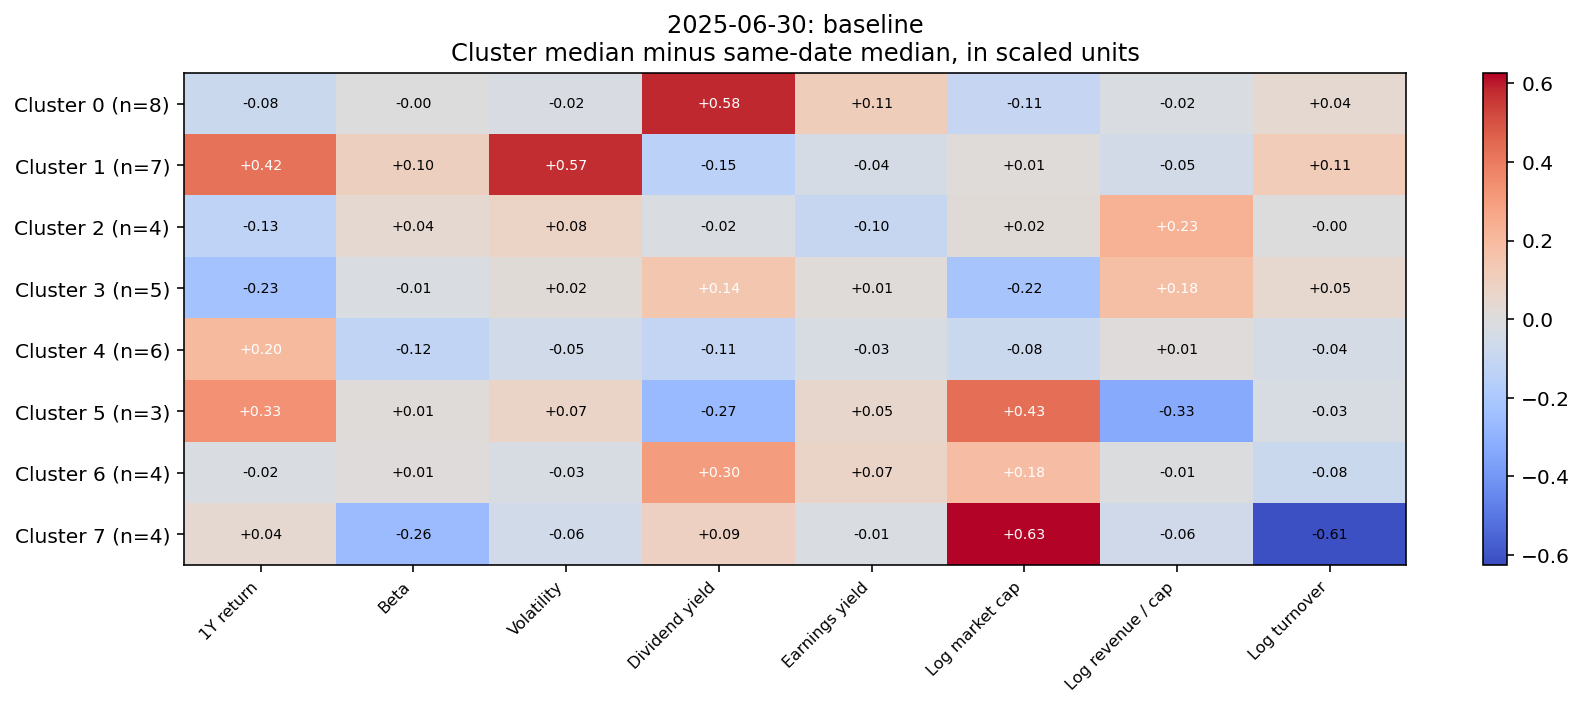

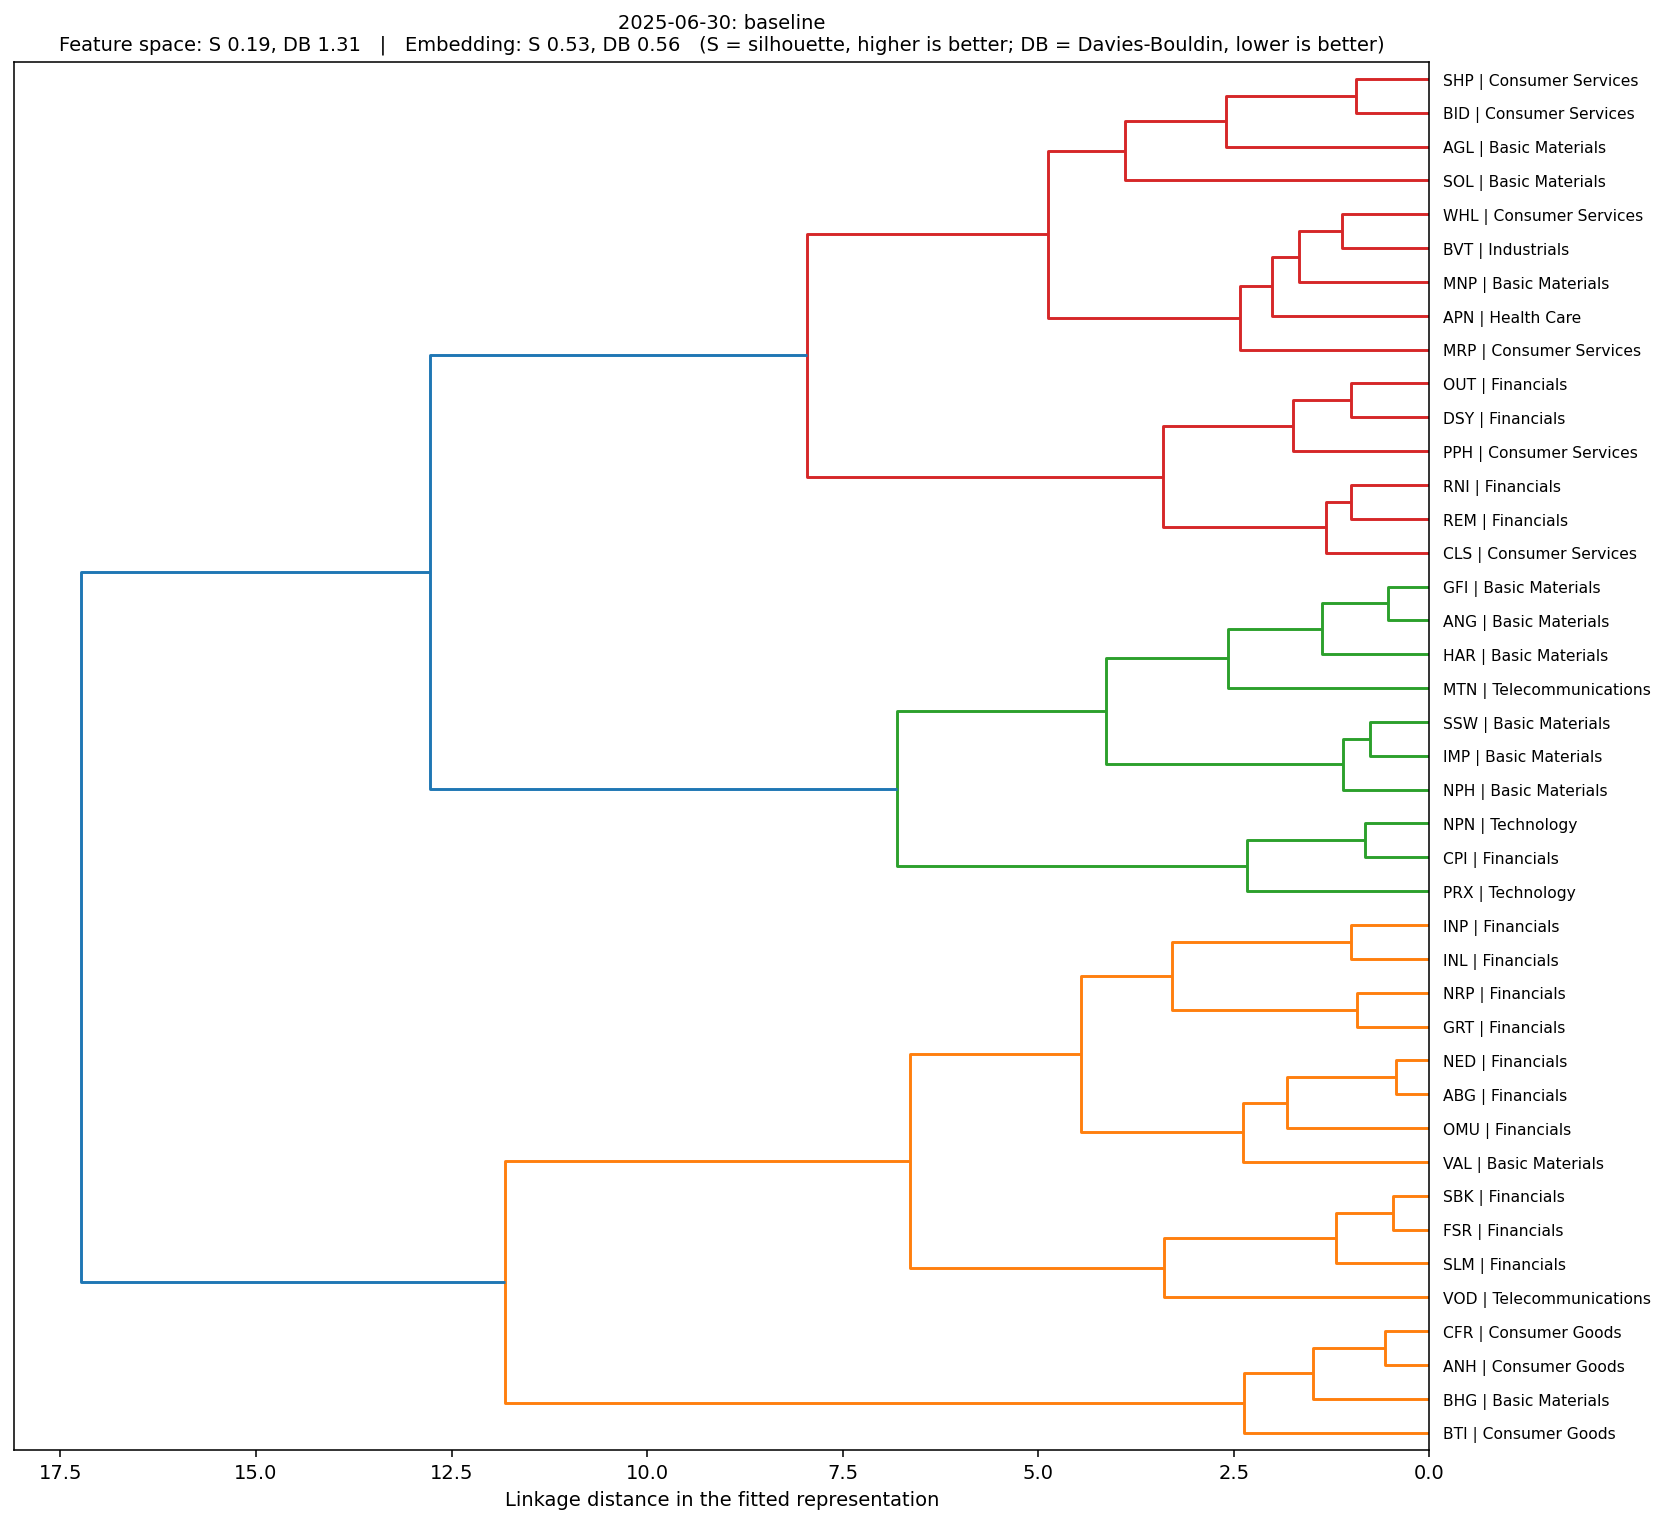

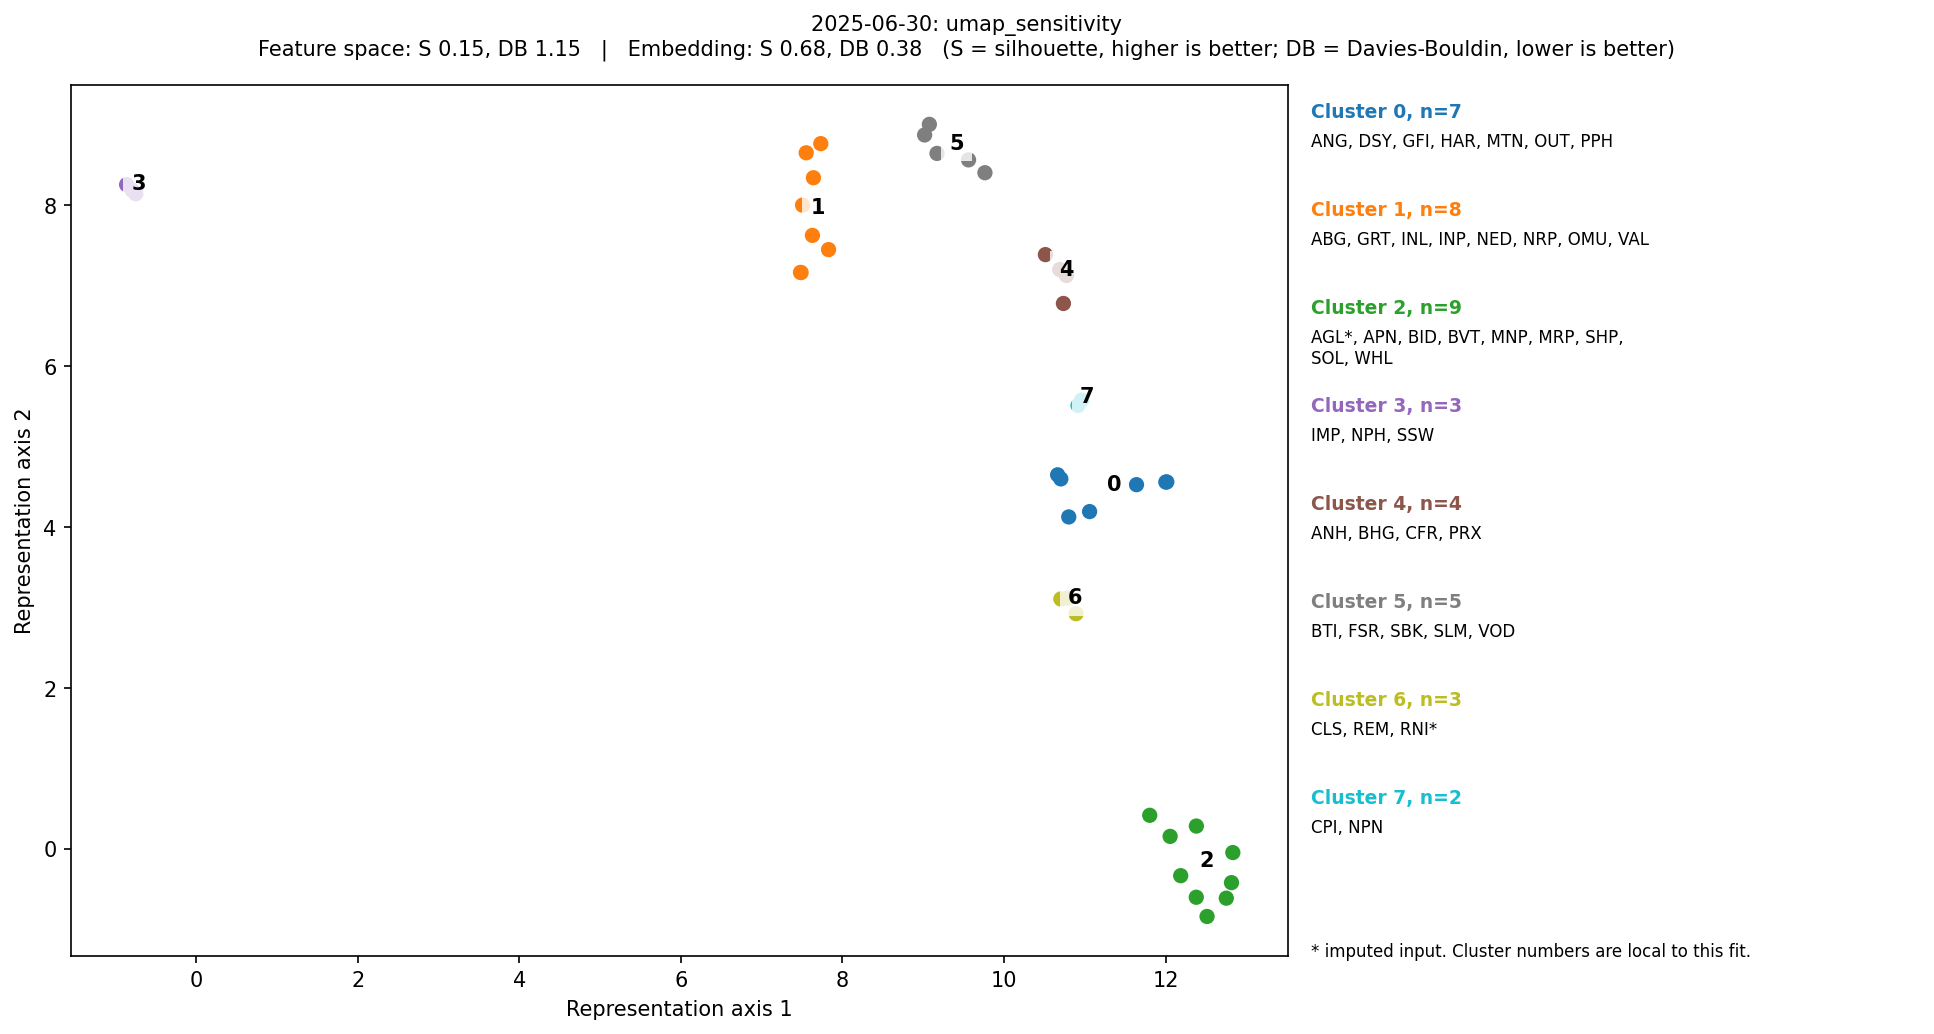

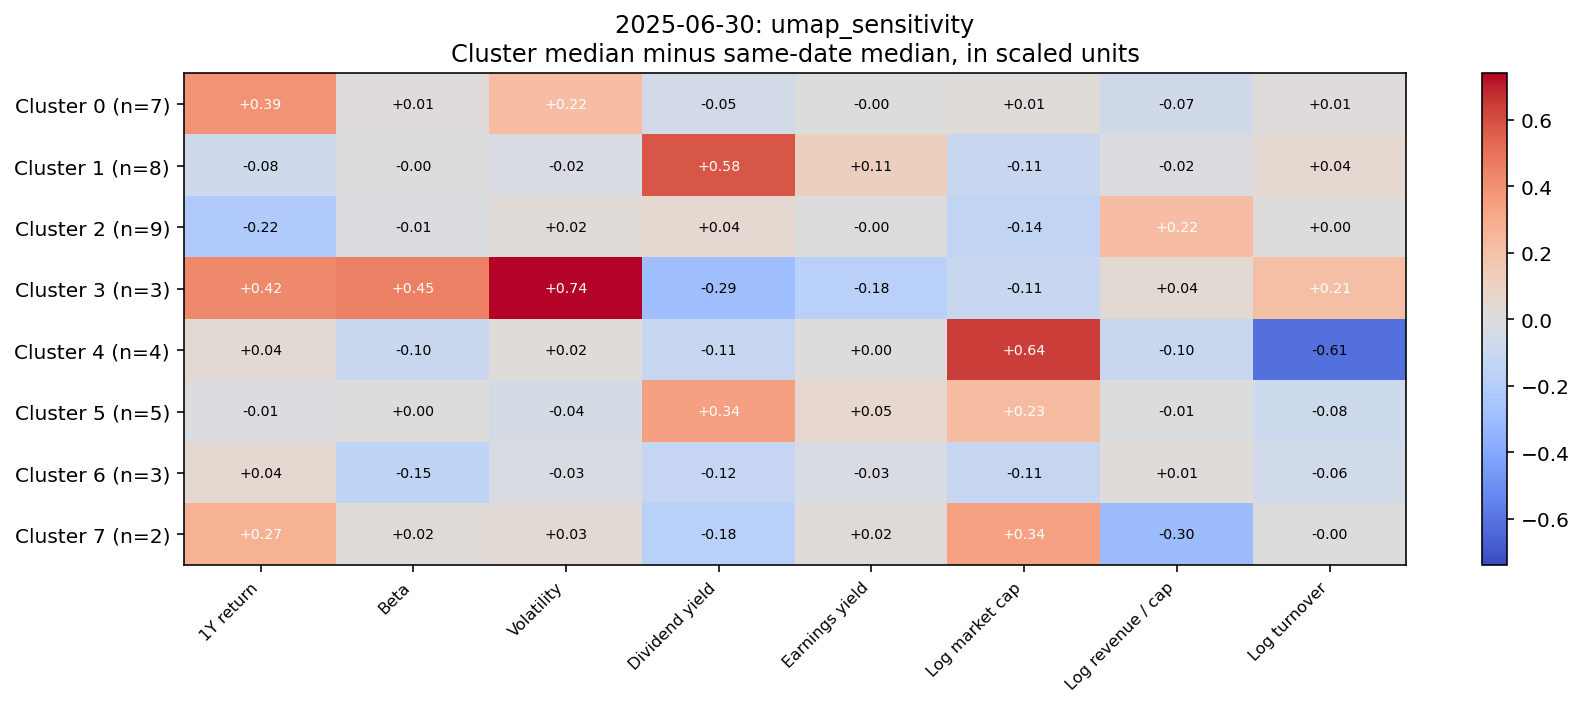

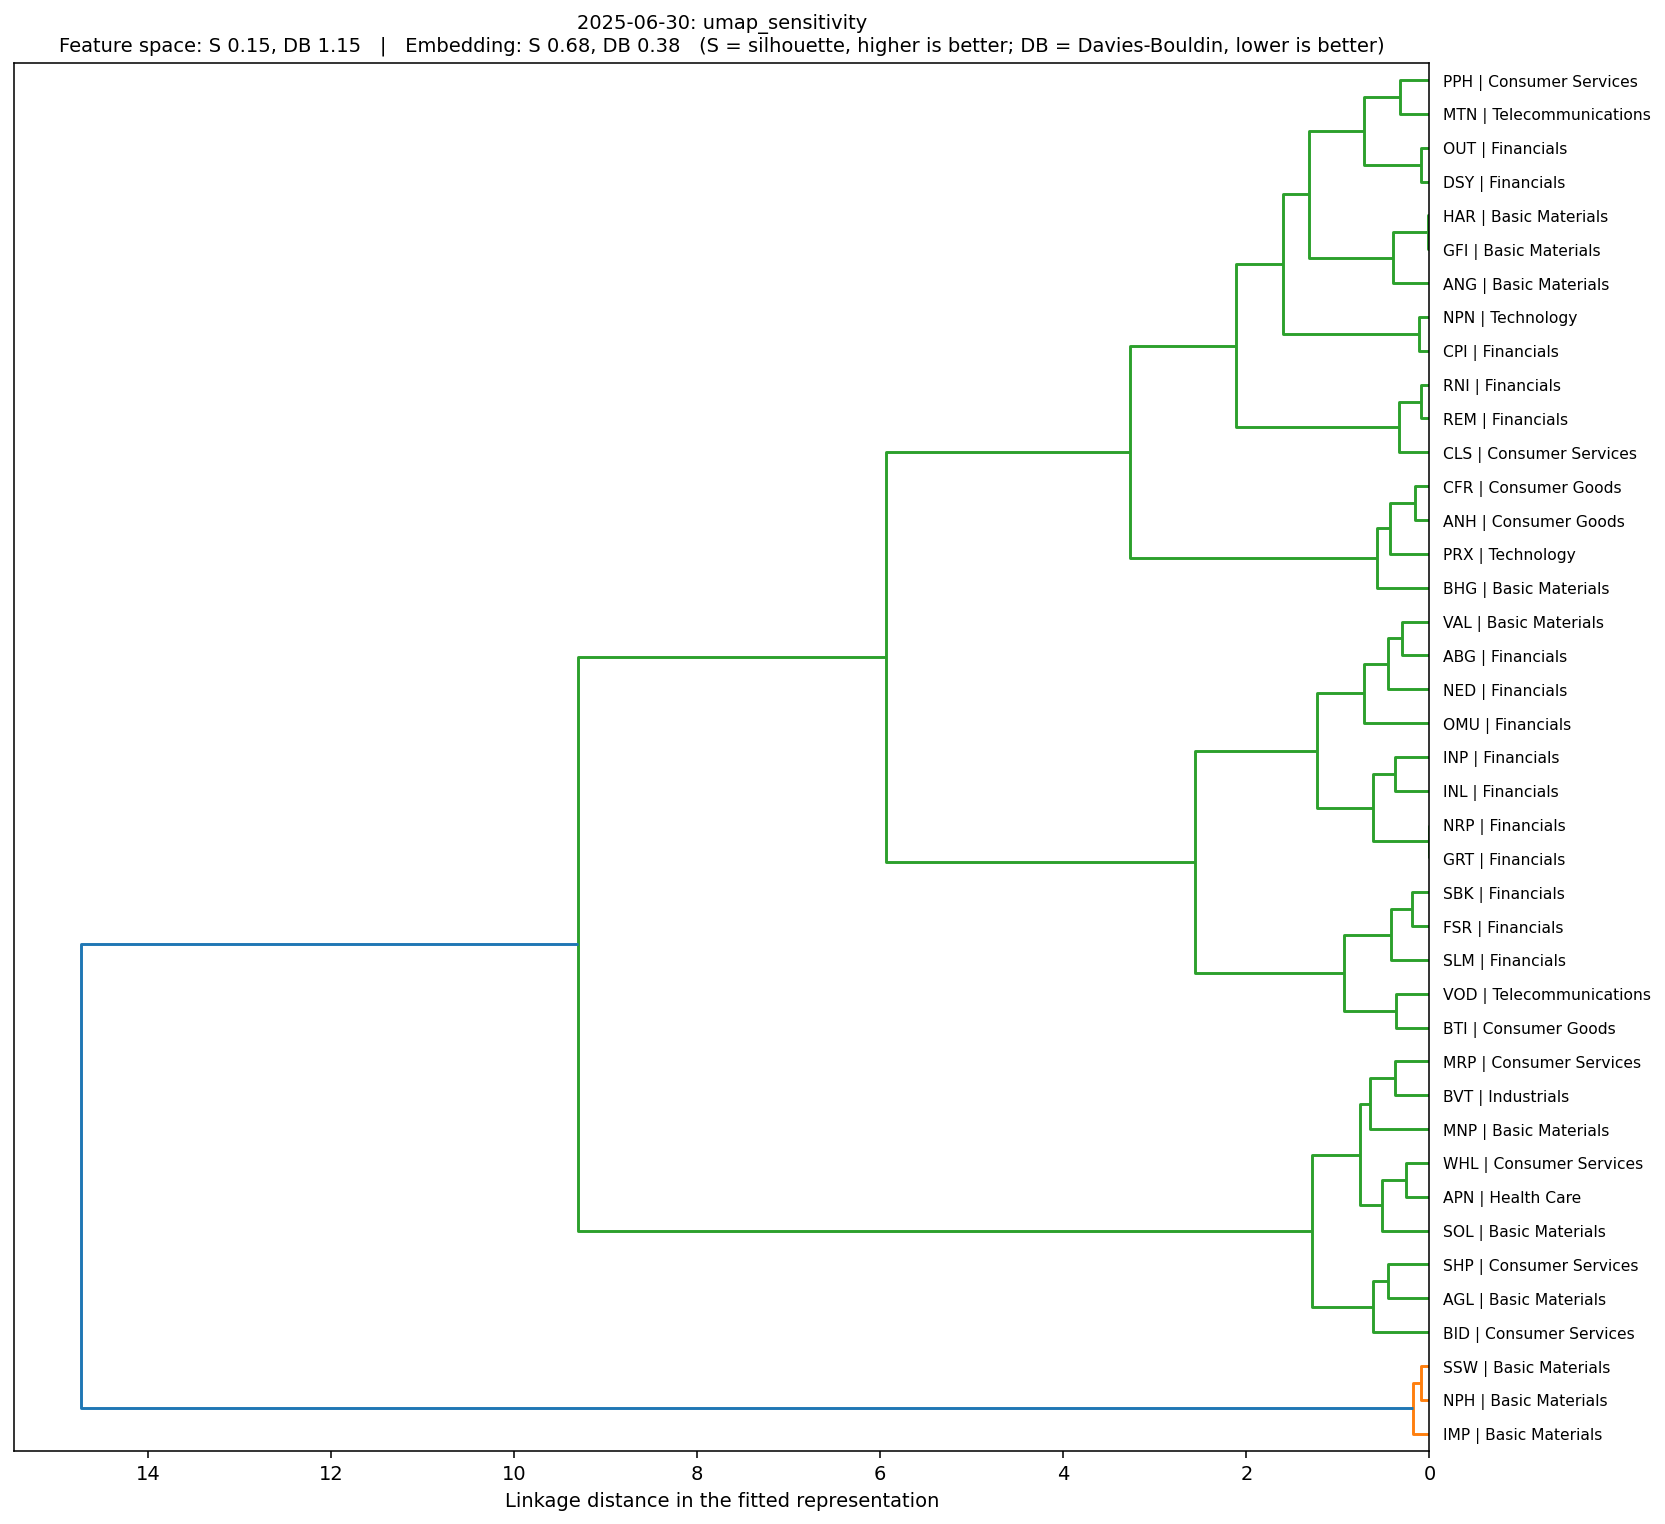

In [7]:
VIEW_DATE = DATES[0]
for name in study.model_folders:
    print(name, VIEW_DATE)
    study.show(f"models/{name}/{VIEW_DATE}/cluster_map.png")
    study.show(f"models/{name}/{VIEW_DATE}/feature_profile.png")
    study.show(f"models/{name}/{VIEW_DATE}/dendrogram.png")

### Seed and cluster-count sensitivity

Mean pairwise ARI between seeds is the only noise reference this notebook computes. It measures how much a partition moves when nothing but the random seed changes. k=8 is the reference specification (the original paper matched eight sector labels), not evidence of eight natural groups: check where the curves actually peak.

pairs  mean_ari  min_ari
study_model      decision_date                          
baseline         2025-06-30        10     0.658    0.464
                 2025-12-31        10     0.925    0.833
                 2026-06-30        10     0.894    0.779
umap_sensitivity 2025-06-30        10     0.846    0.710
                 2025-12-31        10     0.892    0.811
                 2026-06-30        10     0.738    0.597

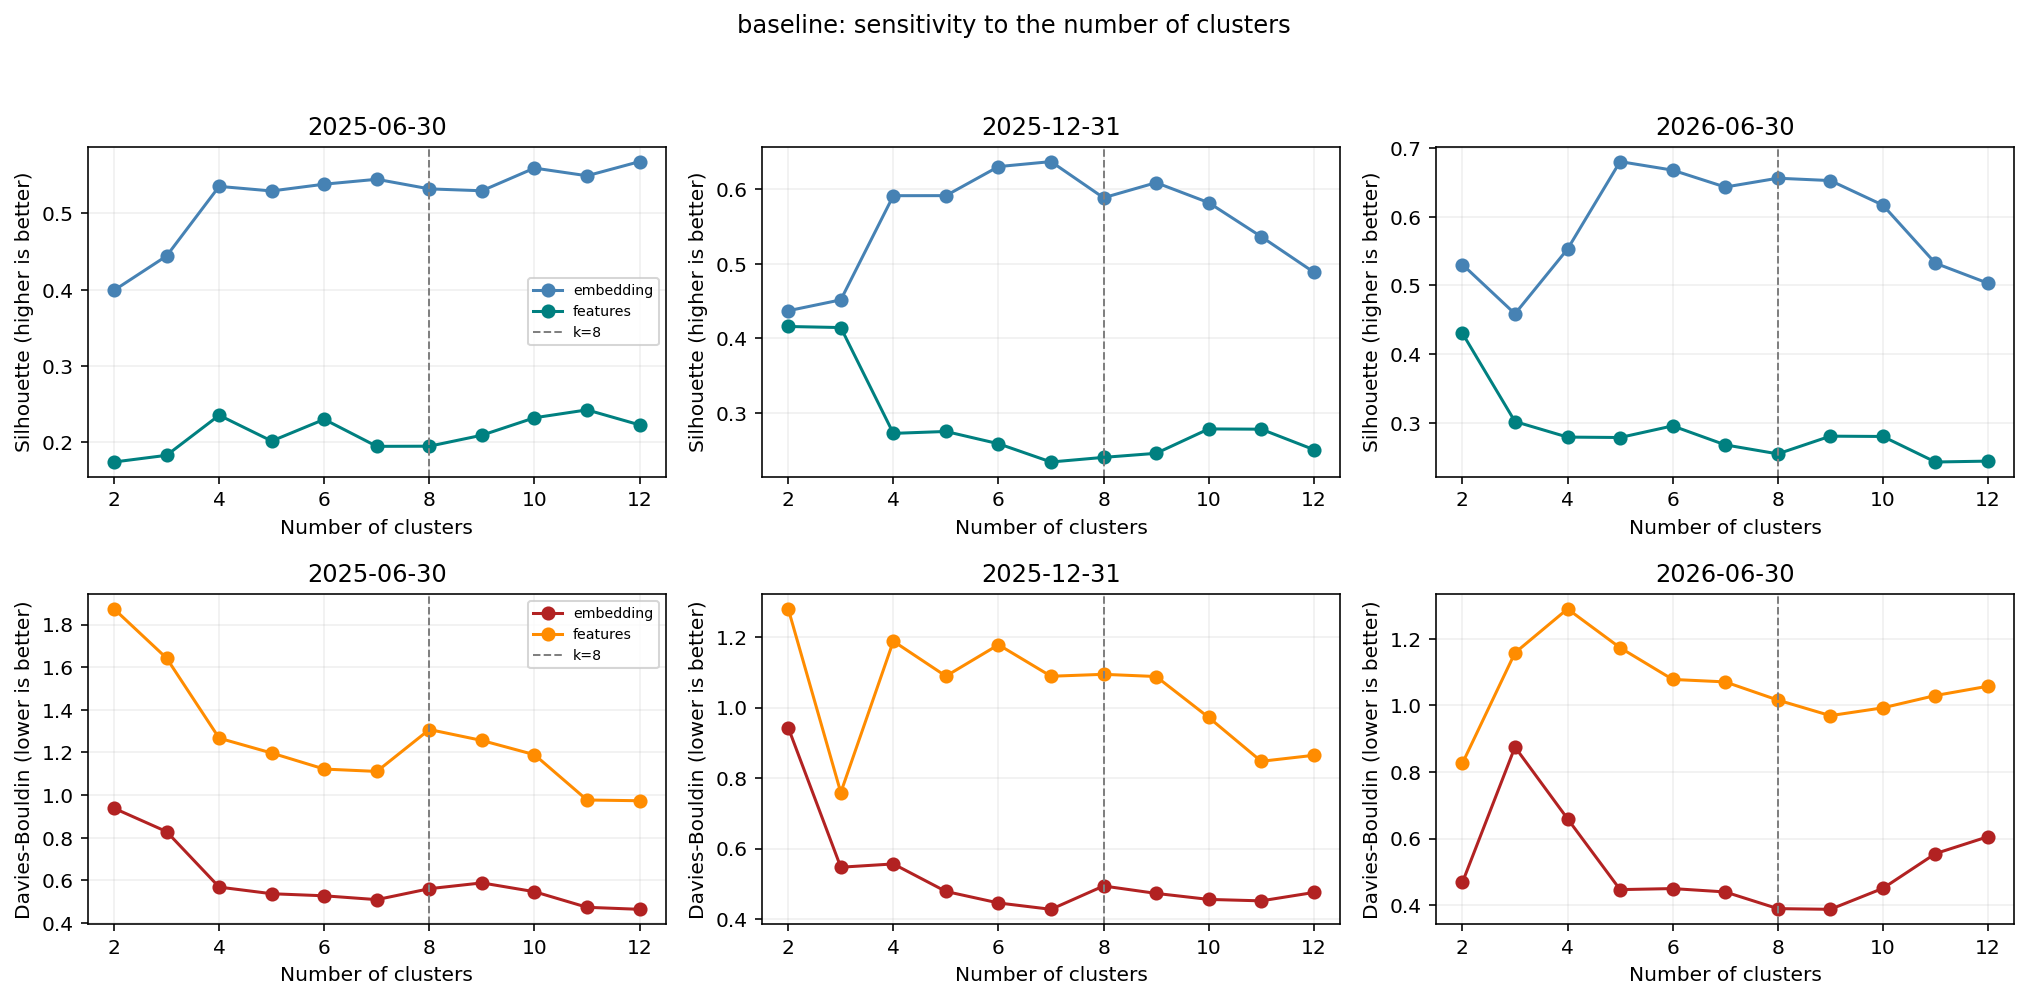

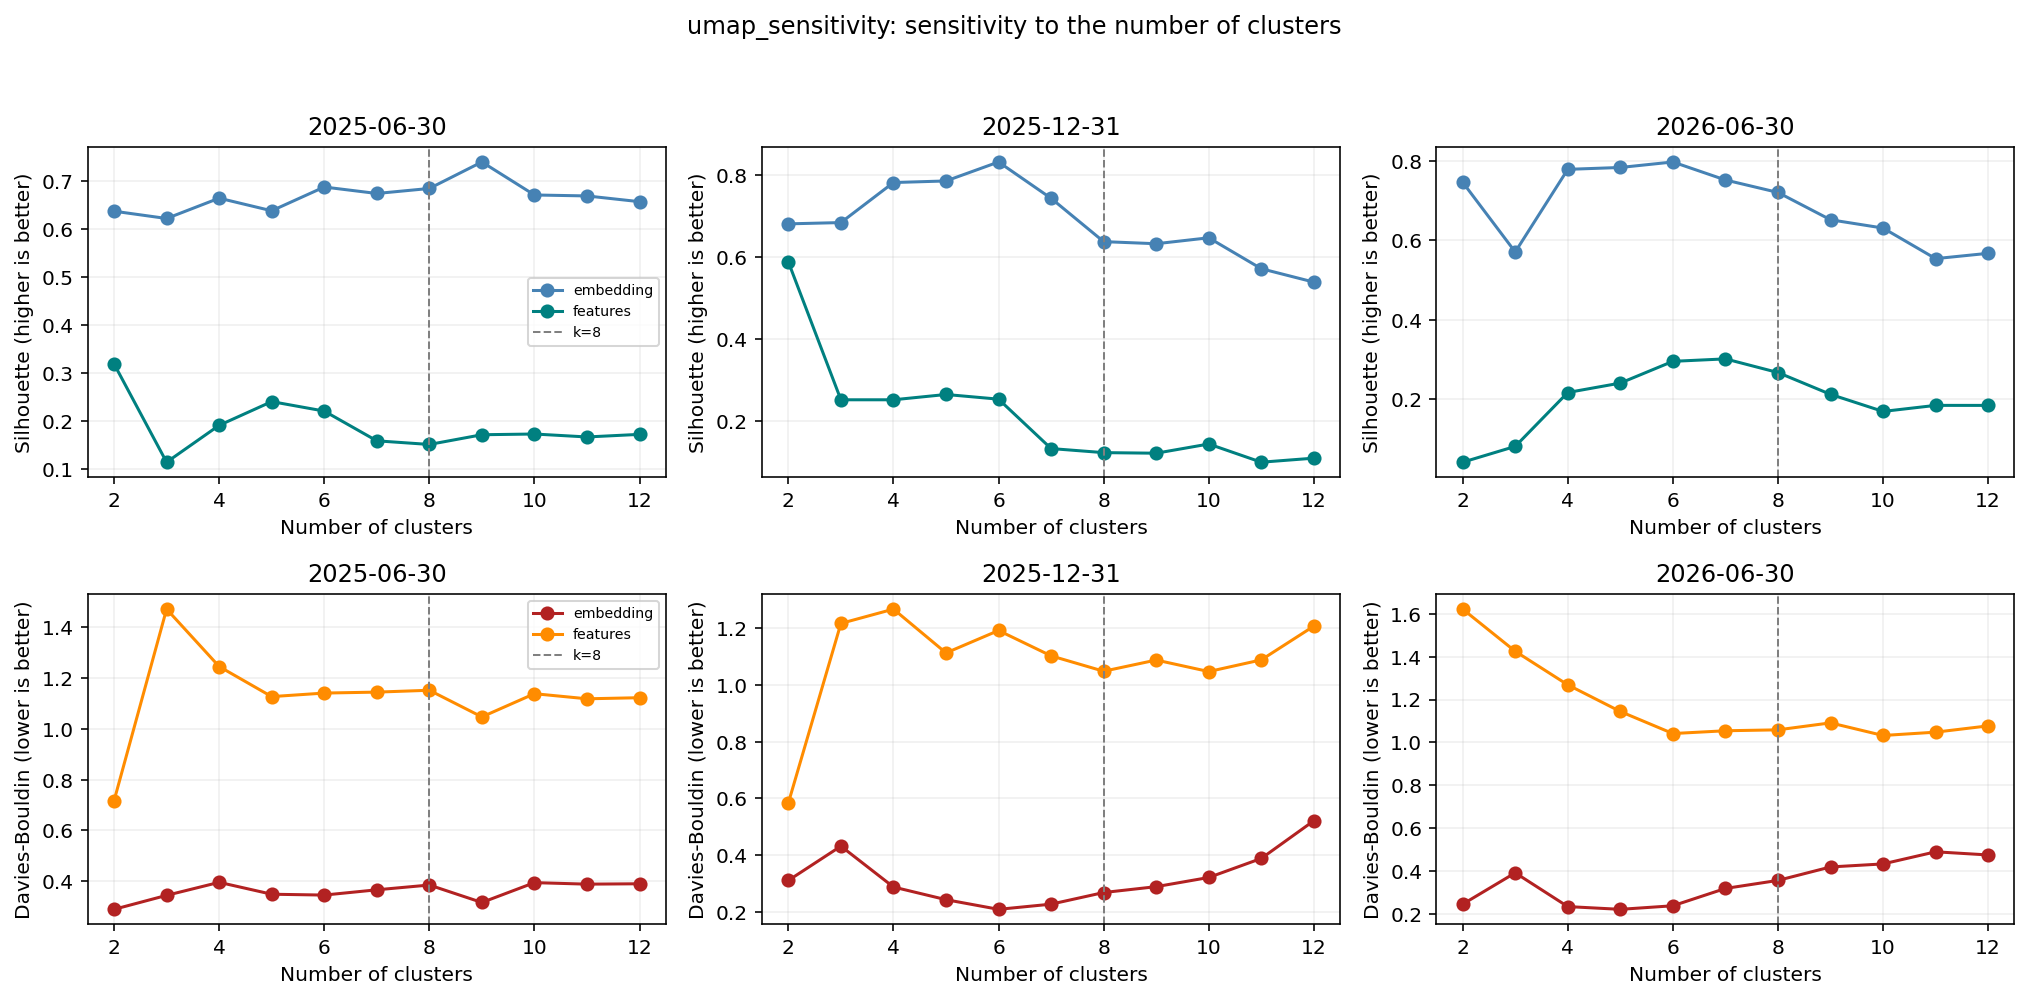

In [8]:
display(study.seed_agreement.groupby(["study_model", "decision_date"])
        .agg(pairs=("ari", "size"), mean_ari=("ari", "mean"), min_ari=("ari", "min")).round(3))
for name in study.model_folders:
    study.show(f"models/{name}/cluster_count_sensitivity.png")

## 5. Explain cluster membership

A gradient-boosted classifier learns each partition from the features, and SHAP explains that classifier. It describes the surrogate, not the clustering and not a cause. Trust it only as far as the **out-of-fold** fidelity allows; in-sample fidelity is always near 1. The table at the end compares SHAP rankings with the plain median deviations from section 4.

,study_model,decision_date,in_sample_accuracy,oof_accuracy,oof_status,minimum_cluster_size
0,baseline,2025-06-30,1.0,0.683,estimated,3
1,baseline,2025-12-31,1.0,0.512,estimated,2
2,baseline,2026-06-30,1.0,0.707,estimated,2
3,umap_sensitivity,2025-06-30,1.0,0.439,estimated,2
4,umap_sensitivity,2025-12-31,1.0,NaN,not estimable: singleton cluster,1
5,umap_sensitivity,2026-06-30,1.0,0.707,estimated,2


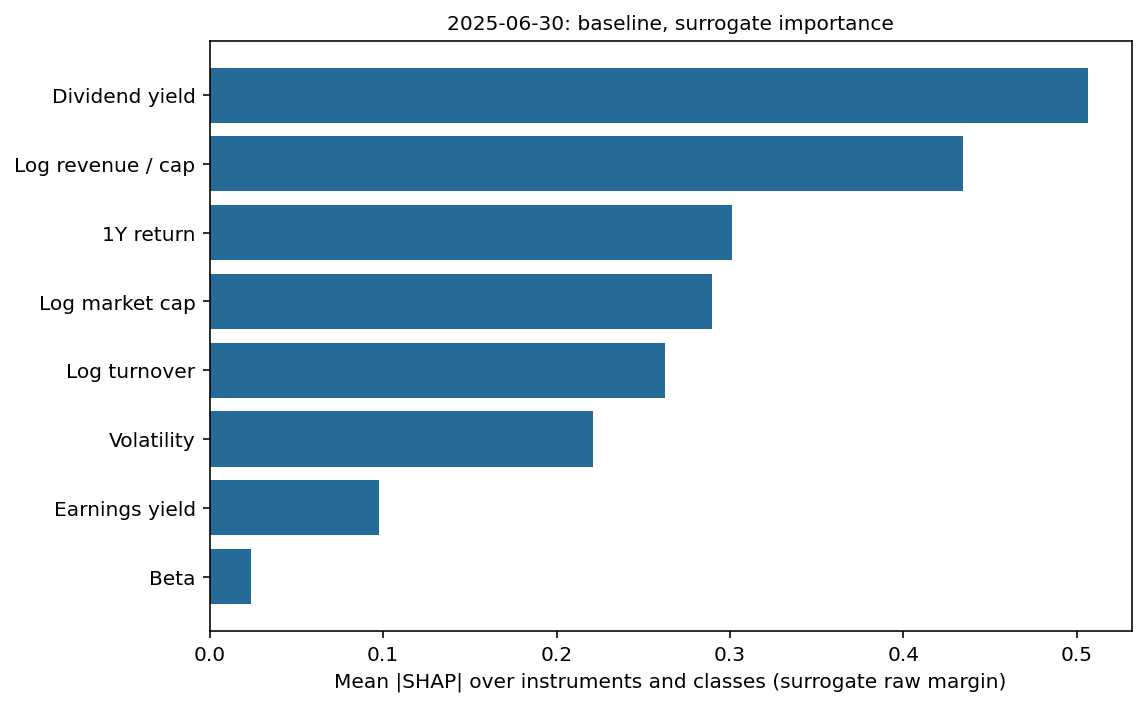

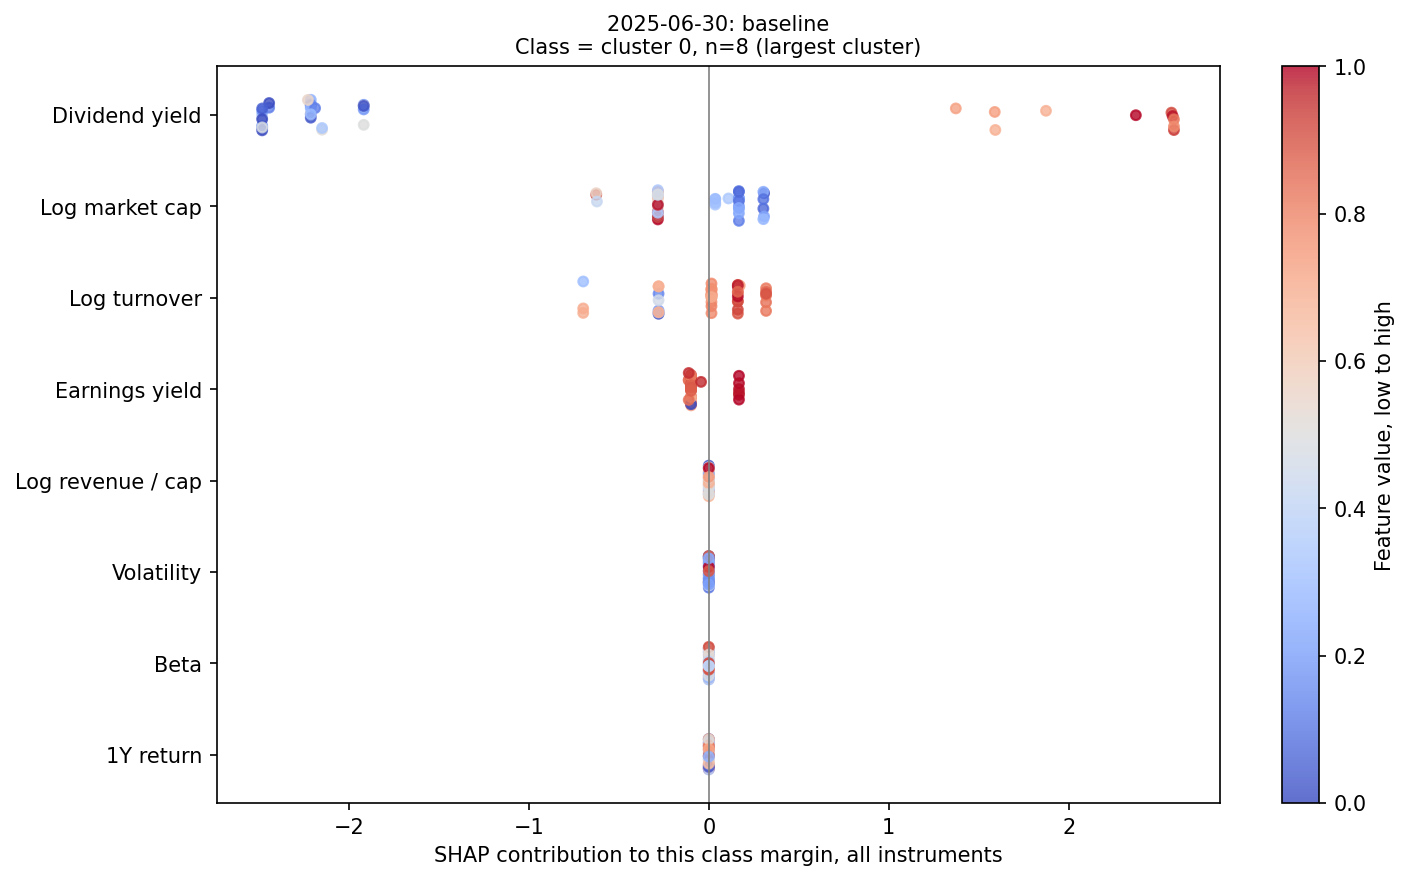

,cluster,n,rank_correlation
0,0,8,0.723
1,1,7,0.667
2,2,4,0.335
3,3,5,0.810
4,4,6,0.500
5,5,3,0.592
6,6,4,0.833
7,7,4,0.764


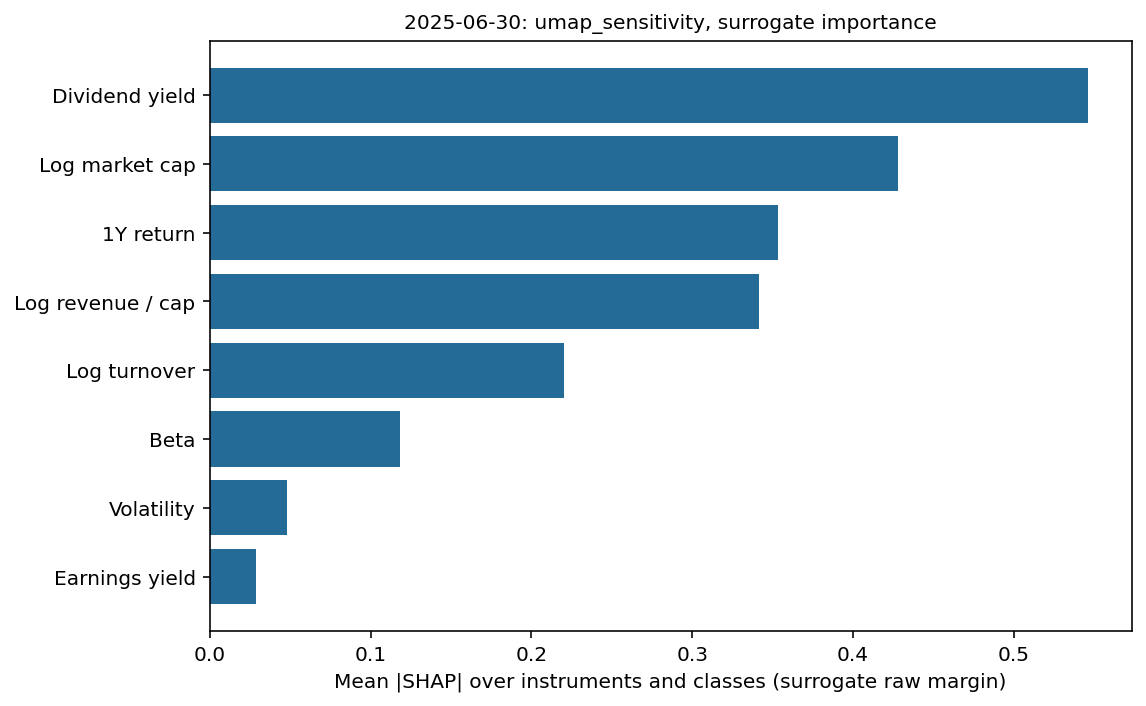

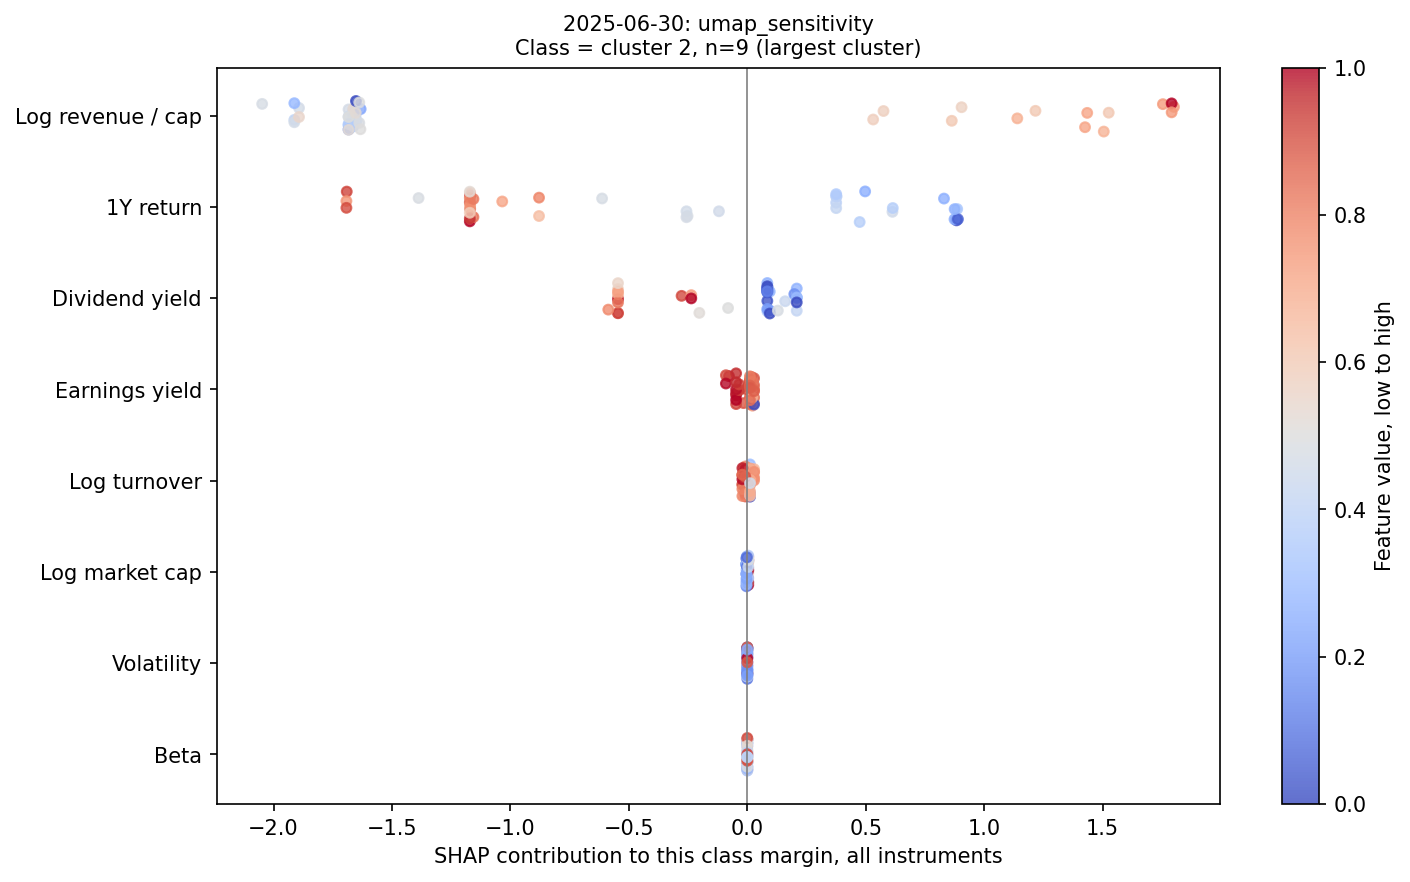

,cluster,n,rank_correlation
0,0,7,0.548
1,1,8,0.748
2,2,9,0.539
3,3,3,0.220
4,4,4,0.109
5,5,5,0.814
6,6,3,0.595
7,7,2,0.412


In [9]:
fidelity = study.explain_clusters()
display(fidelity.round(3))
for name in study.model_folders:
    print(name, VIEW_DATE)
    study.show(f"models/{name}/{VIEW_DATE}/shap_global.png")
    study.show(f"models/{name}/{VIEW_DATE}/shap_distribution.png")
    display(study.table(f"models/{name}/{VIEW_DATE}/profile_vs_shap_ranks.csv").round(3))

## 6. Cluster membership across dates

Cluster numbers are aligned date to date by a Hungarian match on Jaccard overlap among instruments present at both dates. Index entries and exits are separate events and never count as a shift.

`changed` counts continuing instruments whose aligned cluster differs. **A changed label is not yet a changed firm**: compare the date-to-date ARI here with the seed-to-seed ARI above. If they are similar, the movement is within fitting noise.

In [10]:
temporal = study.compare_dates()
display(temporal.round(3))
display(study.longitudinal)

,before,after,continuing,entries,exits,ari,nmi,changed,study_model
0,2025-06-30,2025-12-31,40,1,1,0.556,0.759,9,baseline
1,2025-12-31,2026-06-30,40,1,1,0.660,0.783,9,baseline
2,2025-06-30,2025-12-31,40,1,1,0.377,0.646,15,umap_sensitivity
3,2025-12-31,2026-06-30,40,1,1,0.590,0.751,11,umap_sensitivity


,study_model,stable,shifted,membership gap
0,baseline,22,17,4
1,umap_sensitivity,19,20,4


### Coloured cluster flows

One strand per instrument observed at all three dates. Colour is the aligned cluster; a colour change is a shift, and shifted instruments are bold. Vertical position is layout only.

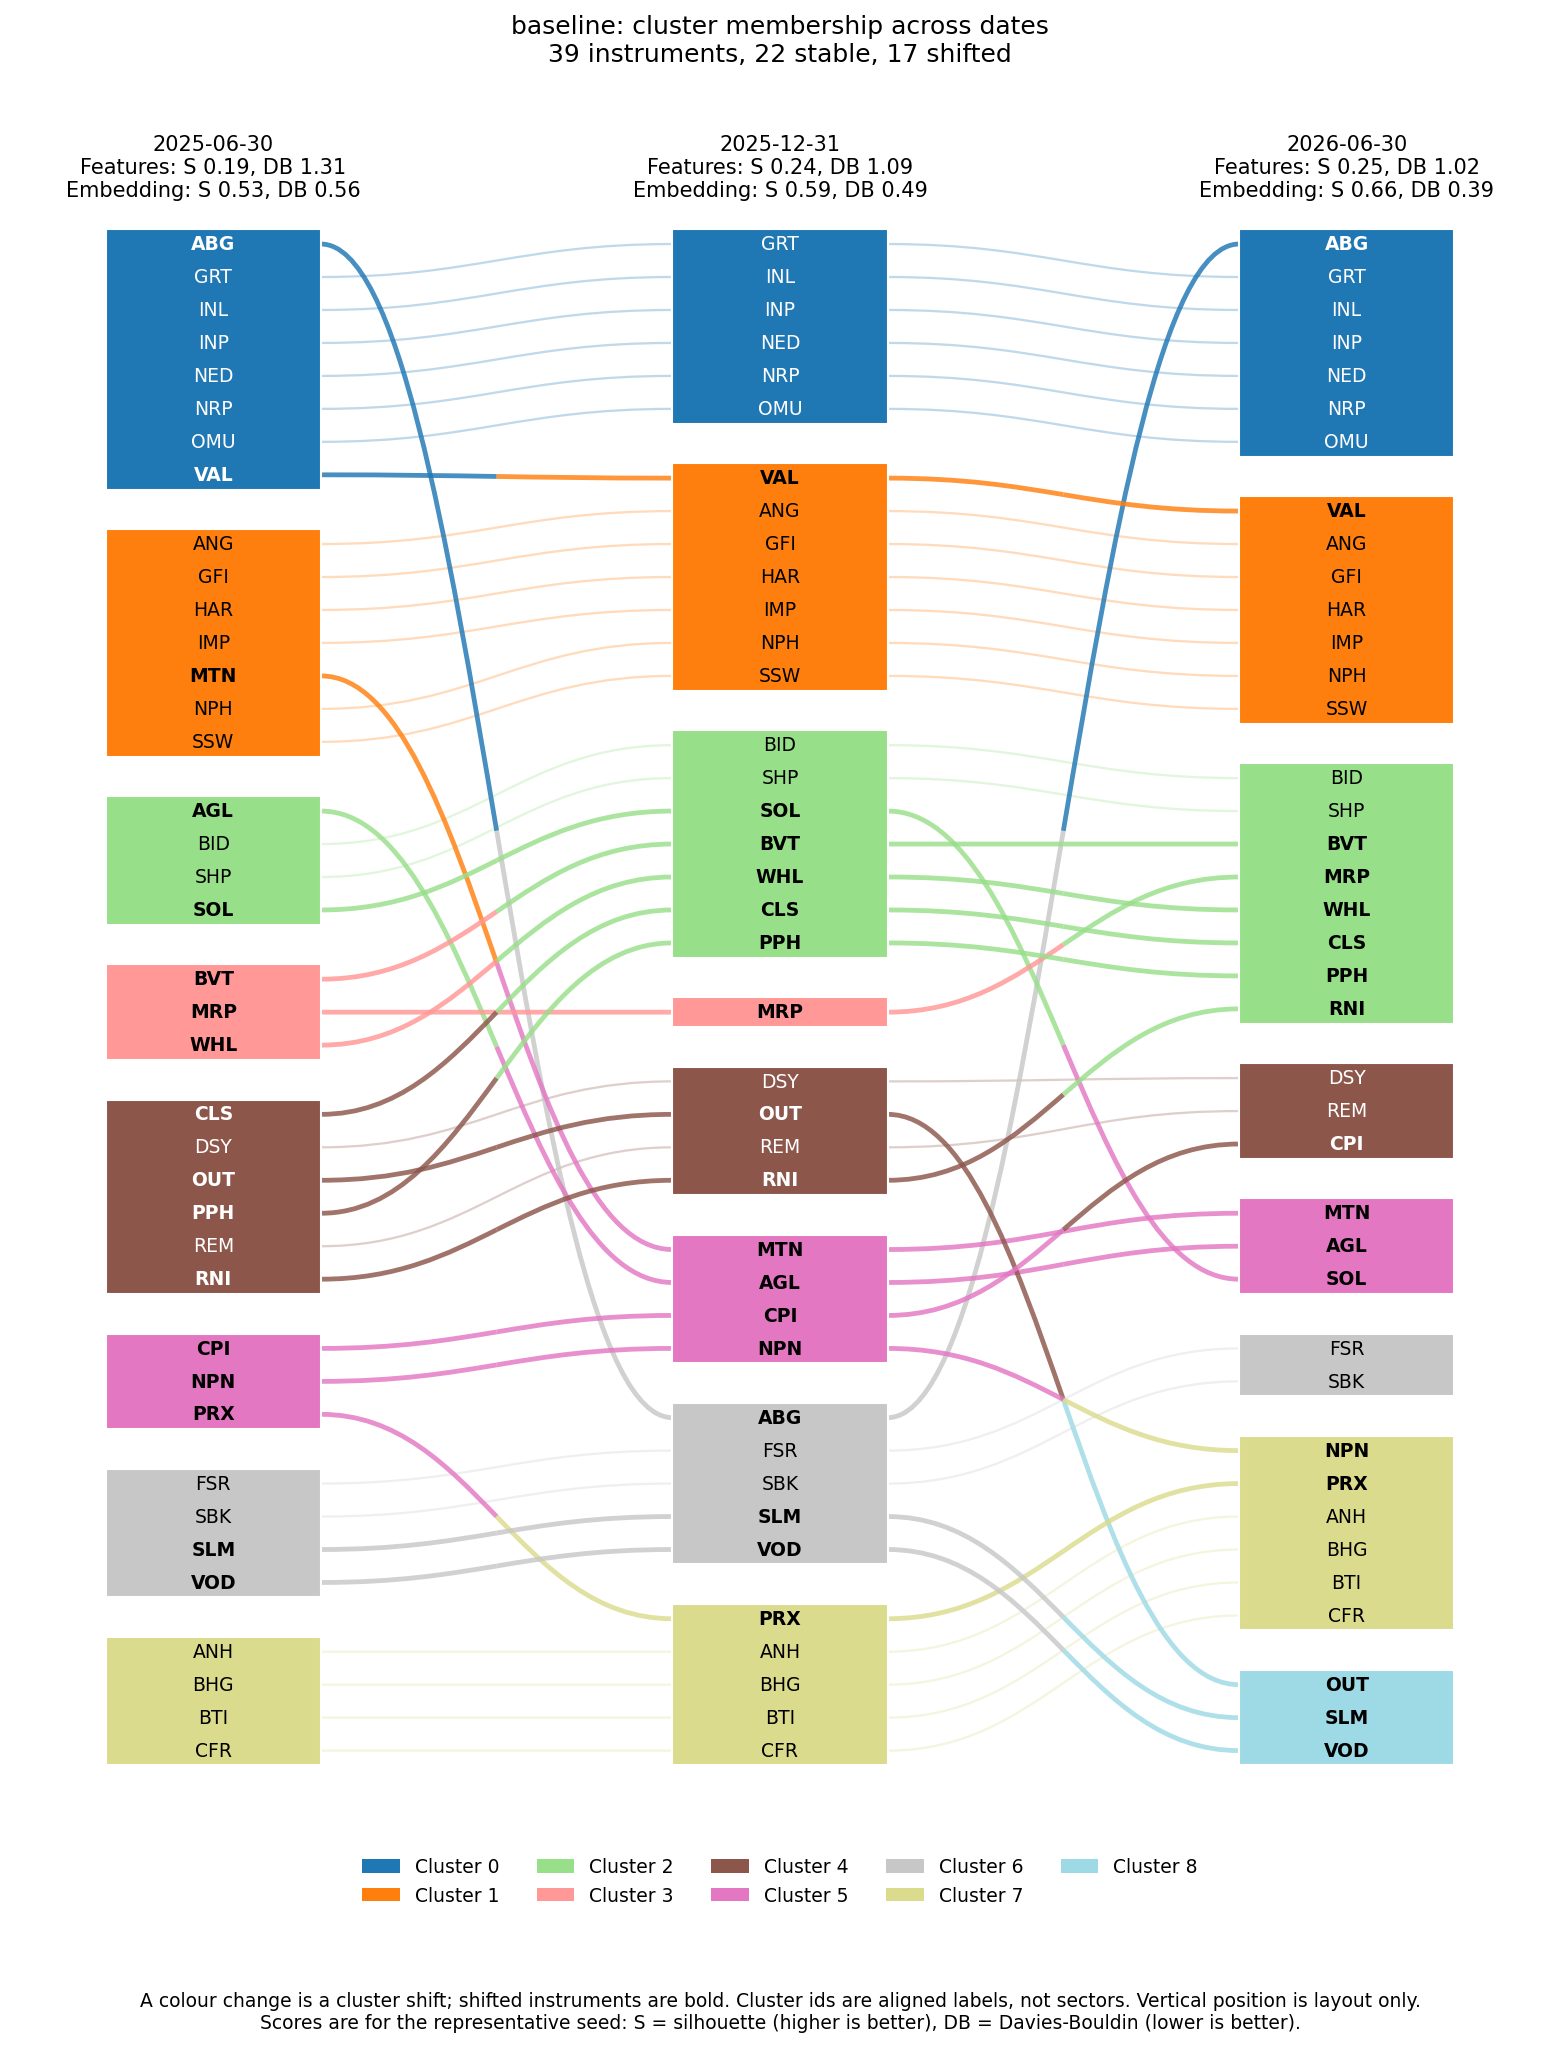

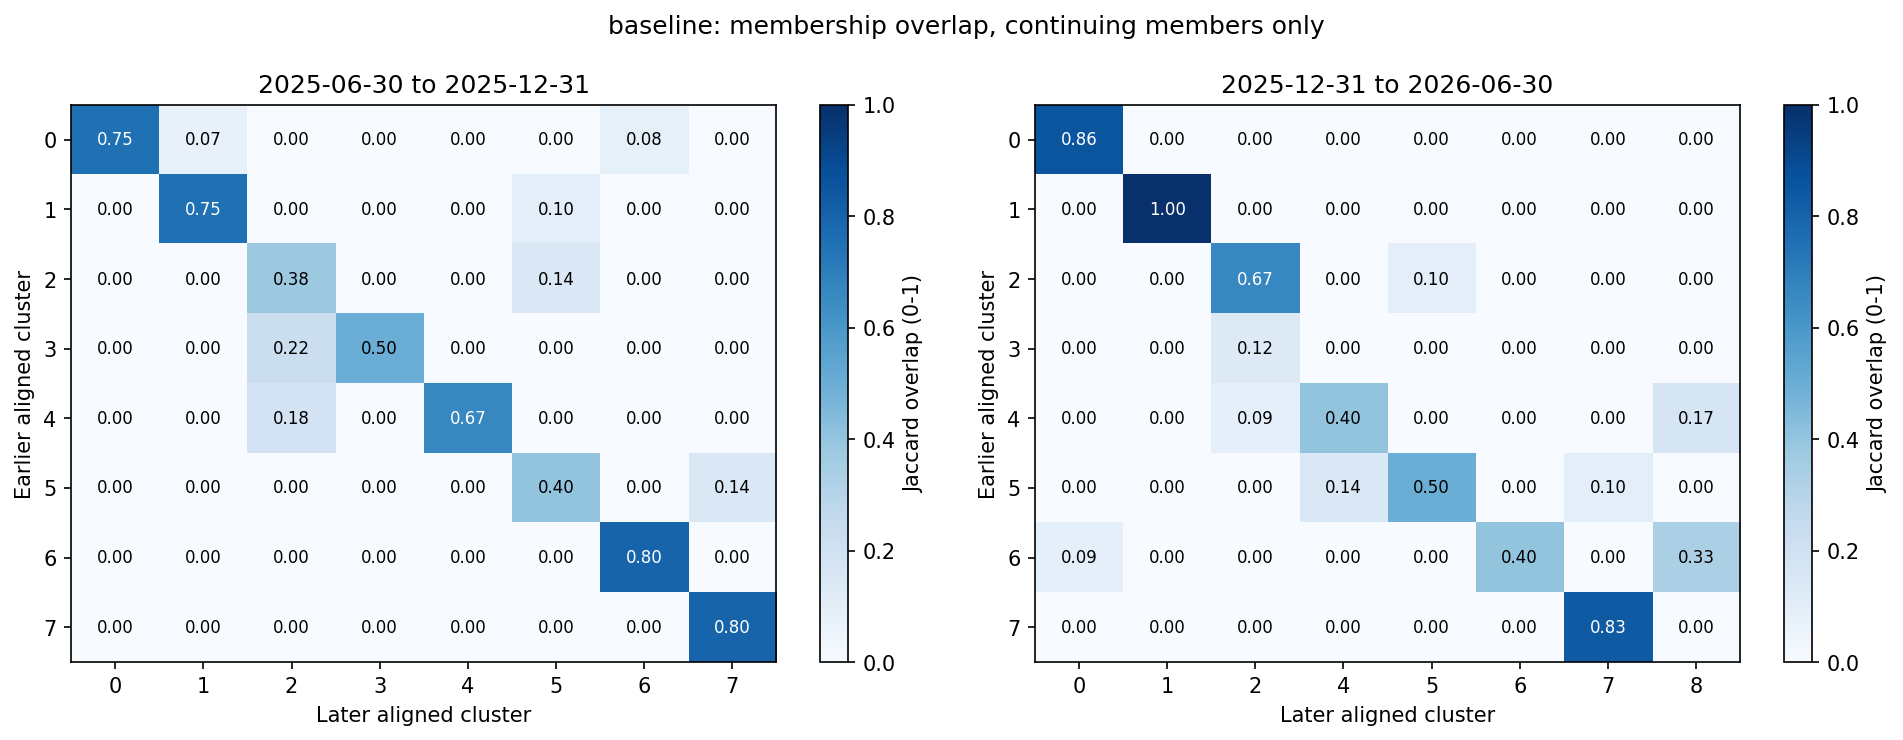

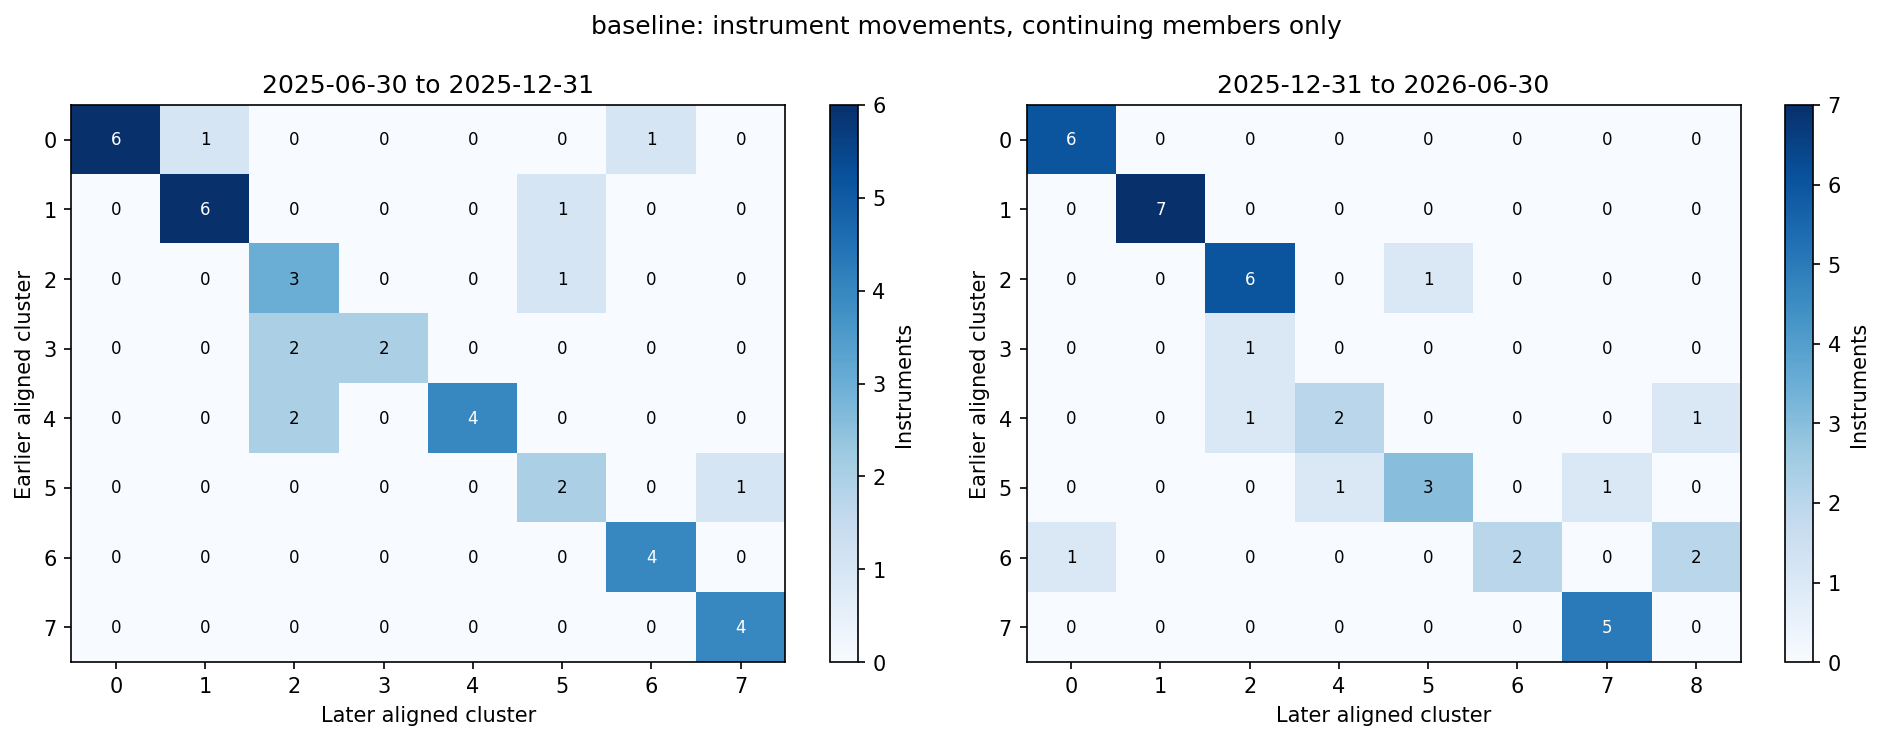

,before,after,ticker,membership_event,cluster_before,cluster_after,cluster_changed
4,2025-06-30,2025-12-31,APN,exit,3.0,NaN,NaN
15,2025-06-30,2025-12-31,GLN,entry,NaN,5.0,NaN
62,2025-12-31,2026-06-30,MNP,exit,3.0,NaN,NaN
71,2025-12-31,2026-06-30,PAN,entry,NaN,1.0,NaN


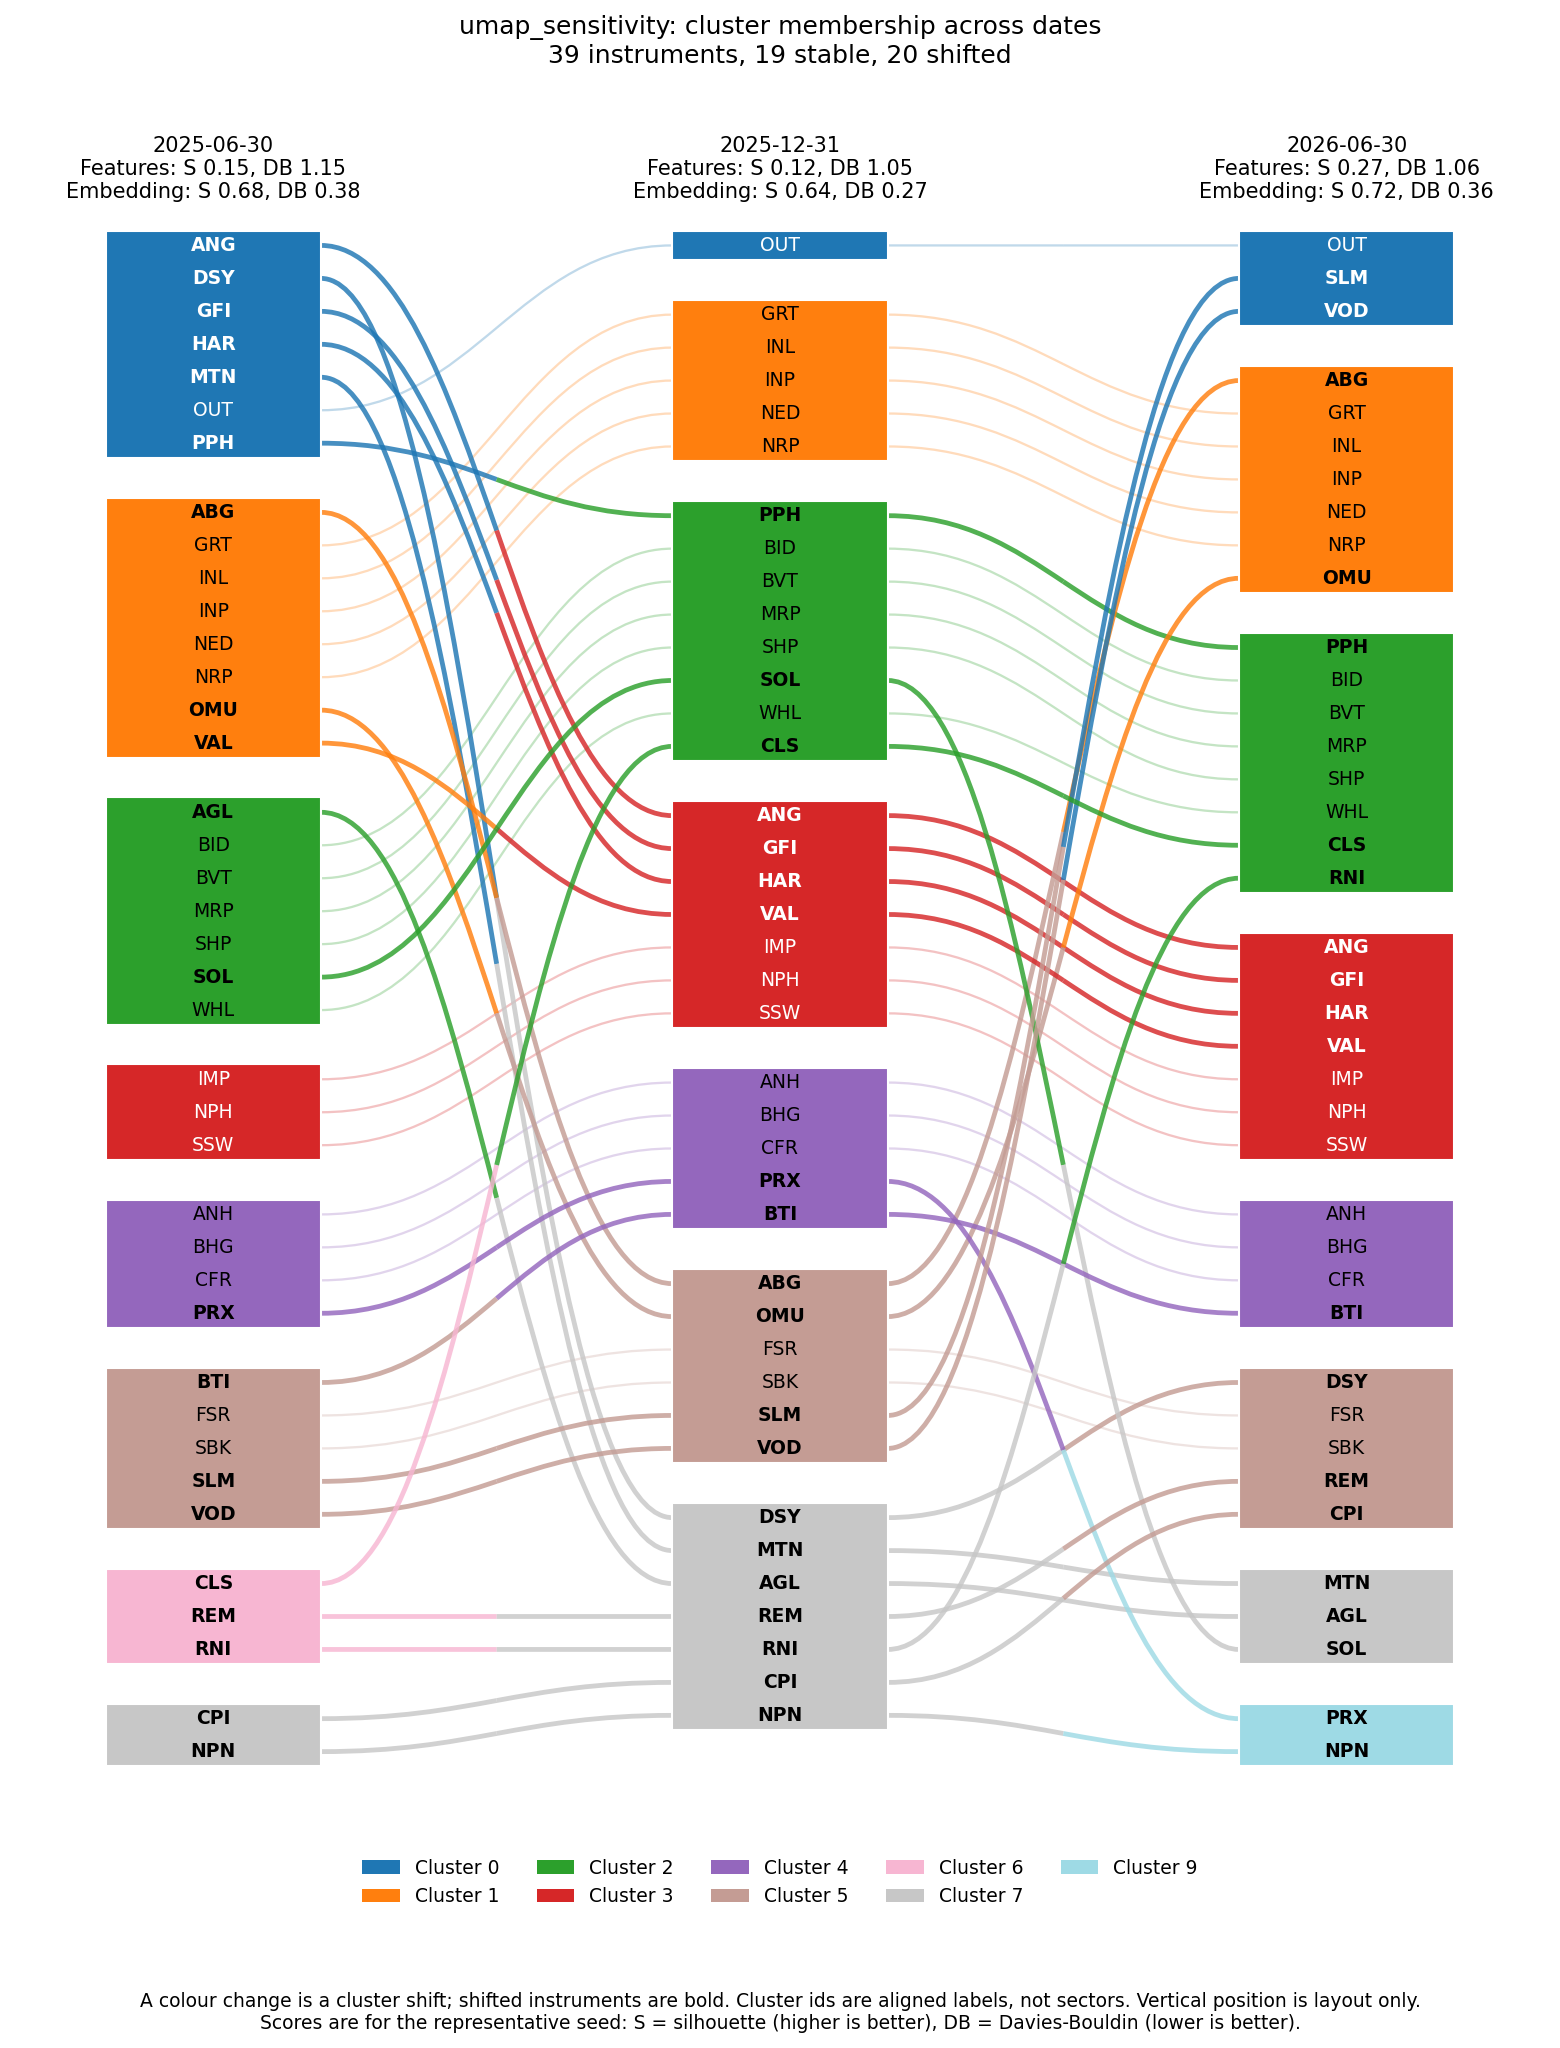

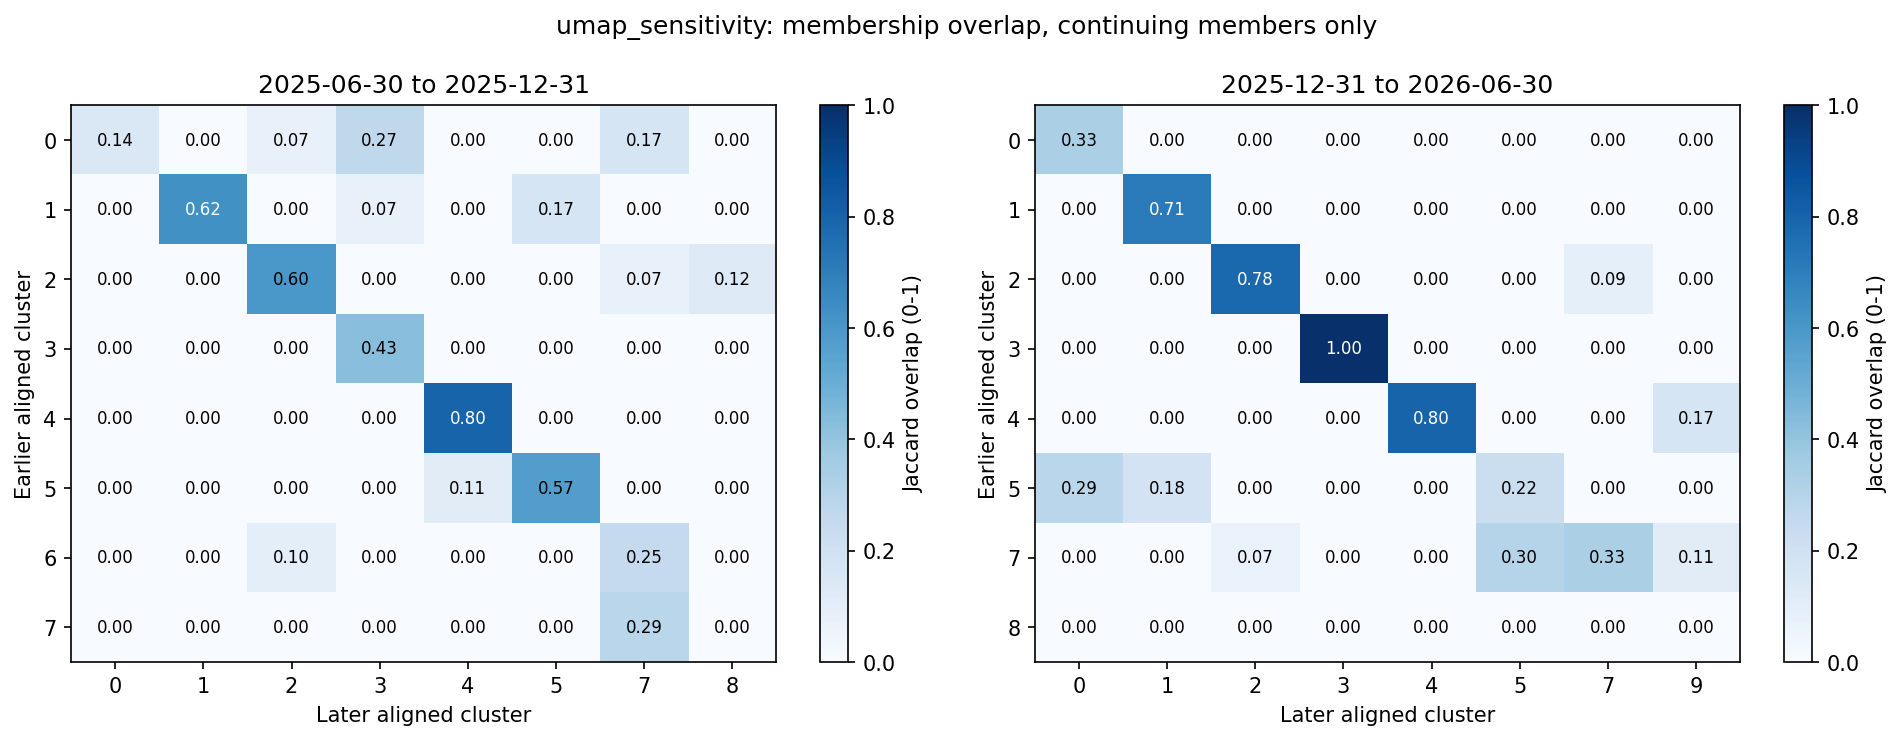

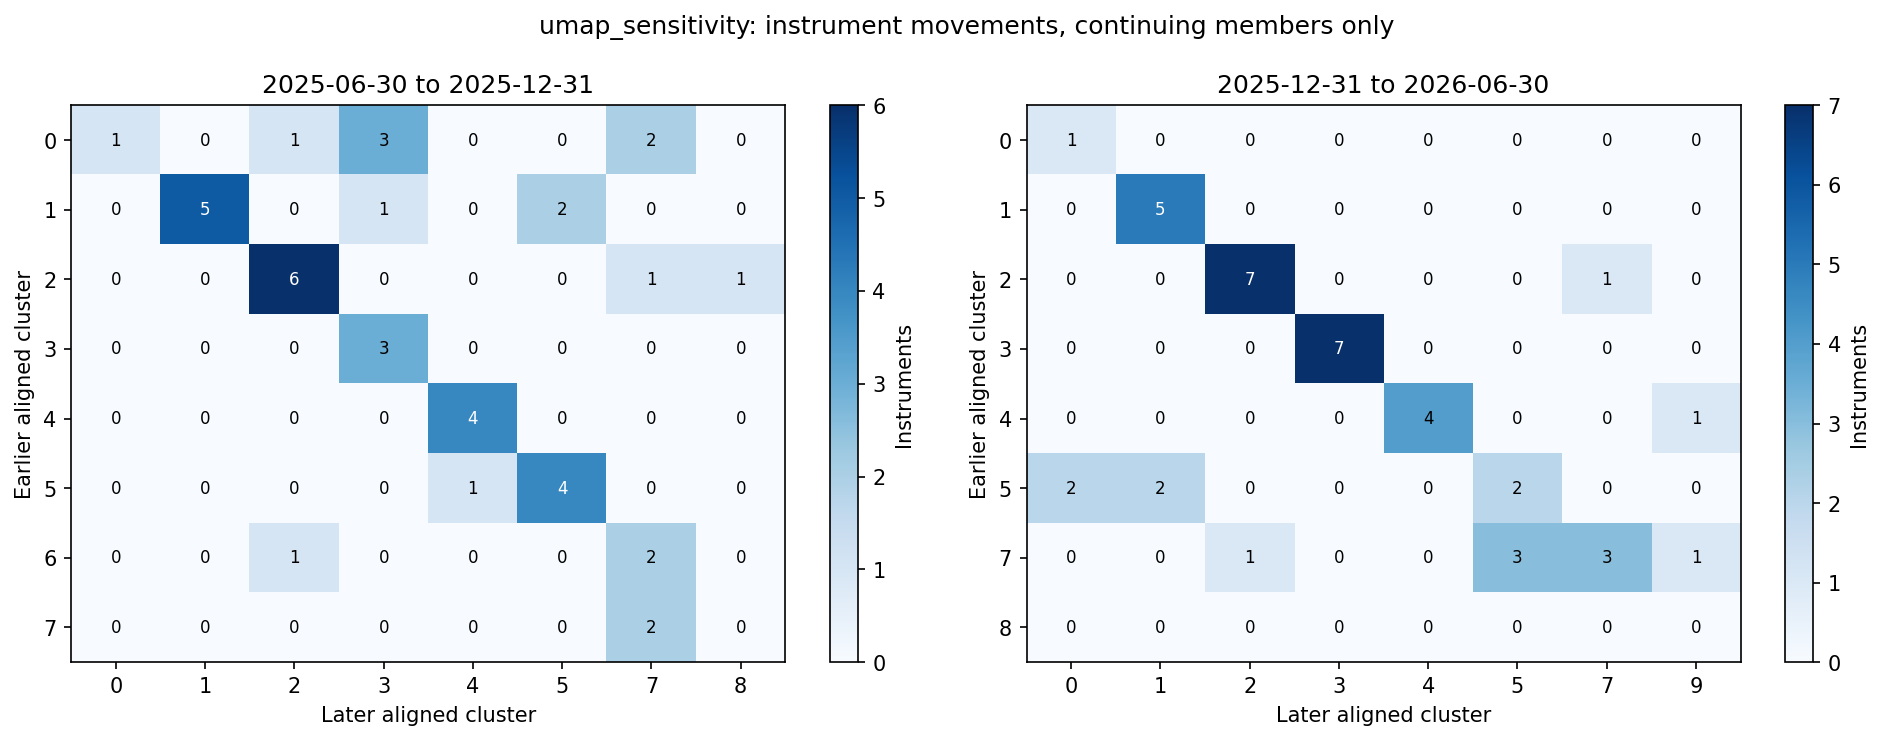

,before,after,ticker,membership_event,cluster_before,cluster_after,cluster_changed
4,2025-06-30,2025-12-31,APN,exit,2.0,NaN,NaN
15,2025-06-30,2025-12-31,GLN,entry,NaN,7.0,NaN
62,2025-12-31,2026-06-30,MNP,exit,8.0,NaN,NaN
71,2025-12-31,2026-06-30,PAN,entry,NaN,3.0,NaN


In [11]:
SHOW_HISTORY_TABLES = False   # set True for the underlying aligned cluster ids
for name in study.model_folders:
    folder = f"longitudinal/{name}"
    study.show(f"{folder}/cluster_flows.png")
    study.show(f"{folder}/jaccard.png")
    study.show(f"{folder}/movement_counts.png")
    events = study.table(f"{folder}/membership_events.csv")
    display(events.query("membership_event != 'continuing'"))
    if SHOW_HISTORY_TABLES:
        display(study.table(f"{folder}/cluster_histories.csv").query("stability_status == 'shifted'"))

### What defines the groups, and what changed?

Profiles show cluster feature deviations alongside within-date surrogate SHAP. Move tables distinguish a firm leaving its peers from a group being redrawn; these are descriptive labels, not causal findings. Read seed support and out-of-fold fidelity alongside each explanation.

The default shows one move per adjacent date pair for each model. Set `MOVE_TICKER` to inspect a particular instrument. All move rows and figures are saved and exported.


,study_model,decision_date,cluster,n,members,defining_features,shap_top_features,surrogate_oof_accuracy
0,baseline,2025-06-30,0,8,"ABG, GRT, INL, INP, NED, NRP, OMU, VAL",high Dividend yield (+0.58); high Earnings yie...,"Dividend yield, Log turnover, Log market cap",0.682927
1,baseline,2025-06-30,1,7,"ANG, GFI, HAR, IMP, MTN, NPH, SSW",high Volatility (+0.57); high 1Y return (+0.42...,"Volatility, 1Y return, Log revenue / cap",0.682927
2,baseline,2025-06-30,2,4,"AGL, BID, SHP, SOL",high Log revenue / cap (+0.23); low 1Y return ...,"Log revenue / cap, Log market cap, Dividend yield",0.682927
3,baseline,2025-06-30,3,5,"APN, BVT, MNP, MRP, WHL",low 1Y return (-0.23); low Log market cap (-0....,"1Y return, Log revenue / cap, Dividend yield",0.682927
4,baseline,2025-06-30,4,6,"CLS, DSY, OUT, PPH, REM, RNI",high 1Y return (+0.20); low Beta (-0.12); low ...,"Log market cap, Dividend yield, 1Y return",0.682927
5,baseline,2025-06-30,5,3,"CPI, NPN, PRX",high Log market cap (+0.43); high 1Y return (+...,"Log revenue / cap, Log market cap, 1Y return",0.682927
6,baseline,2025-06-30,6,4,"FSR, SBK, SLM, VOD",high Dividend yield (+0.30); high Log market c...,"Dividend yield, Log market cap, Earnings yield",0.682927
7,baseline,2025-06-30,7,4,"ANH, BHG, BTI, CFR",high Log market cap (+0.63); low Log turnover ...,"Log turnover, Log market cap, Dividend yield",0.682927
8,baseline,2025-12-31,0,6,"GRT, INL, INP, NED, NRP, OMU",high Dividend yield (+0.47); low Log market ca...,"Dividend yield, Earnings yield, Log market cap",0.512195
9,baseline,2025-12-31,1,7,"ANG, GFI, HAR, IMP, NPH, SSW, VAL",high 1Y return (+1.45); high Volatility (+0.62...,"1Y return, Log turnover, Volatility",0.512195


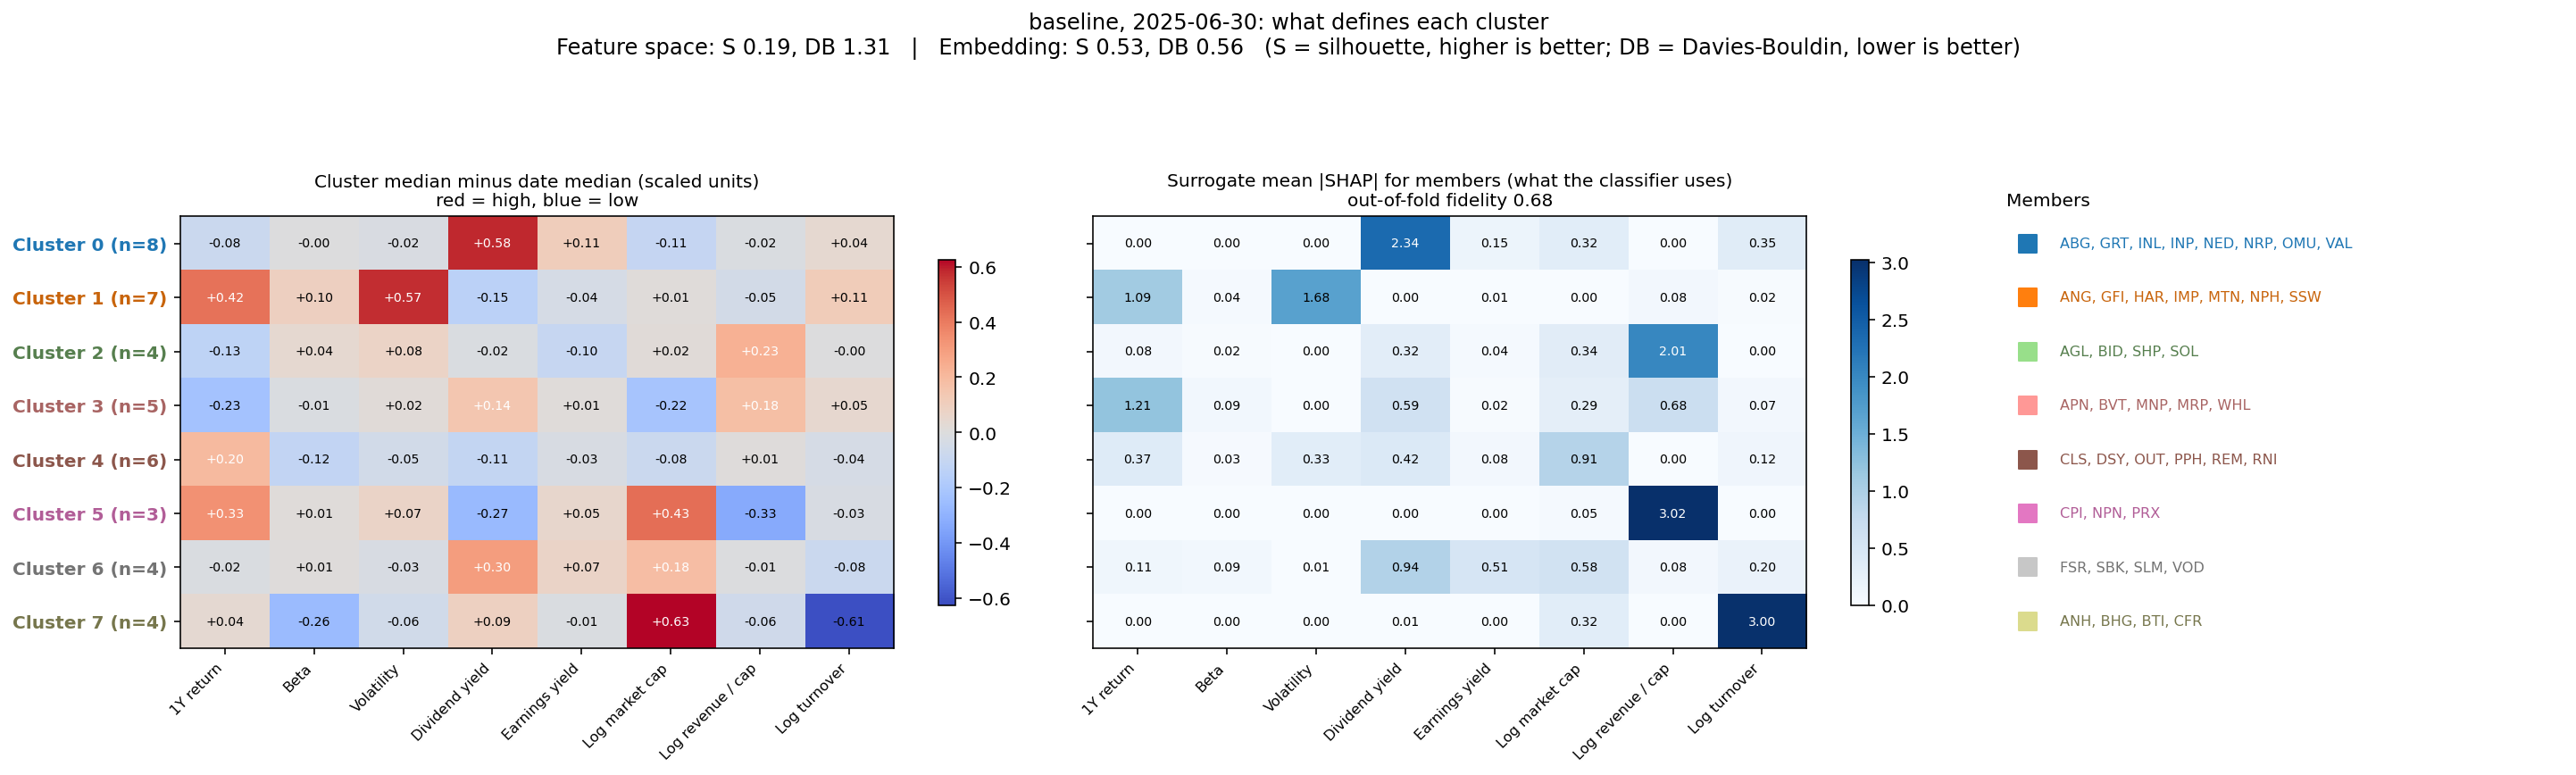

,study_model,ticker,company,sector_label,before,after,from_cluster,to_cluster,move_type,peer_retention,...,peers_kept,new_peers,largest_changes,fits_destination_on,destination_defining_features,shap_toward_destination,support_new_peers,support_old_peers,surrogate_oof_accuracy_after,data_caveat
0,baseline,ABG,ABSA GROUP LTD,Financials,2025-06-30,2025-12-31,0,6,instrument moved,0.000000,...,NaN,"FSR, SBK, SLM, VOD",Dividend yield -0.20; 1Y return +0.12; Beta -0.10,1Y return; Log market cap; Volatility,high Dividend yield (+0.24); high Log market c...,Dividend yield +0.97; Log market cap +0.70; Ea...,0.950000,0.000000,0.512195,NaN
1,baseline,AGL,ANGLO AMERICAN PLC,Basic Materials,2025-06-30,2025-12-31,2,5,instrument moved,0.000000,...,NaN,"CPI, GLN, MTN, NPN",1Y return +0.27; Dividend yield -0.19; Beta -0.12,Log market cap; Volatility; Log revenue / cap,high Log market cap (+0.34); low Dividend yiel...,Earnings yield +1.15; Log market cap +0.95; Di...,1.000000,0.000000,0.512195,volume_imputed
2,baseline,BVT,BIDVEST GROUP LTD,Industrials,2025-06-30,2025-12-31,3,2,instrument moved,0.333333,...,WHL,"BID, CLS, PPH, SHP, SOL, WHL",Beta -0.07; 1Y return +0.06; Earnings yield -0.01,Volatility; 1Y return; Log market cap,high Log revenue / cap (+0.27); low 1Y return ...,Log revenue / cap +2.10; Volatility +0.58; Log...,1.000000,0.533333,0.512195,NaN
3,baseline,CLS,CLICKS GROUP LTD,Consumer Services,2025-06-30,2025-12-31,4,2,instrument moved,0.200000,...,PPH,"BID, BVT, PPH, SHP, SOL, WHL",1Y return -0.14; Dividend yield +0.10; Log rev...,1Y return; Log turnover; Log market cap,high Log revenue / cap (+0.27); low 1Y return ...,Log revenue / cap +0.88; Volatility +0.63; Log...,1.000000,0.200000,0.512195,NaN
4,baseline,MTN,MTN GROUP LTD,Telecommunications,2025-06-30,2025-12-31,1,5,instrument moved,0.000000,...,NaN,"AGL, CPI, GLN, NPN",1Y return +0.15; Beta -0.11; Dividend yield -0.05,1Y return; Beta; Volatility,high Log market cap (+0.34); low Dividend yiel...,Earnings yield +1.24; Log market cap +0.82; Vo...,1.000000,0.000000,0.512195,NaN
5,baseline,PPH,PEPKOR HOLDINGS LTD,Consumer Services,2025-06-30,2025-12-31,4,2,instrument moved,0.200000,...,CLS,"BID, BVT, CLS, SHP, SOL, WHL",1Y return -0.44; Log turnover +0.10; Earnings ...,1Y return; Log turnover; Beta,high Log revenue / cap (+0.27); low 1Y return ...,Log revenue / cap +1.48; Volatility +0.58; 1Y ...,1.000000,0.200000,0.512195,NaN
6,baseline,PRX,PROSUS,Technology,2025-06-30,2025-12-31,5,7,instrument moved,0.000000,...,NaN,"ANH, BHG, BTI, CFR",1Y return -0.13; Beta -0.08; Volatility -0.02,Log market cap; Log turnover,low Log turnover (-0.62); high Log market cap ...,Log market cap +3.21; Log revenue / cap +0.03;...,1.000000,0.000000,0.512195,NaN
7,baseline,VAL,VALTERRA PLATINUM LTD,Basic Materials,2025-06-30,2025-12-31,0,1,instrument moved,0.000000,...,NaN,"ANG, GFI, HAR, IMP, NPH, SSW",1Y return +0.94; Dividend yield -0.50; Log mar...,1Y return; Volatility; Beta,high 1Y return (+1.45); high Volatility (+0.62...,1Y return +2.94; Log turnover +0.03; Volatilit...,1.000000,0.000000,0.512195,NaN
8,baseline,WHL,WOOLWORTHS HLDS LTD,Consumer Services,2025-06-30,2025-12-31,3,2,instrument moved,0.333333,...,BVT,"BID, BVT, CLS, PPH, SHP, SOL",Dividend yield -0.11; Log turnover +0.05; 1Y r...,Dividend yield; 1Y return; Log turnover,high Log revenue / cap (+0.27); low 1Y return ...,Log revenue / cap +2.20; Volatility +0.58; Log...,1.000000,0.533333,0.512195,NaN
9,baseline,ABG,ABSA GROUP LTD,Financials,2025-12-31,2026-06-30,6,0,instrument moved,0.000000,...,NaN,"GRT, INL, INP, NED, NRP, OMU",Beta -0.14; Dividend yield +0.07; 1Y return +0.03,Dividend yield; Log turnover; Earnings yield,high Dividend yield (+0.36); low Log market ca...,Dividend yield +2.76; Log turnover +0.01; Beta...,1.000000,0.000000,0.707317,NaN


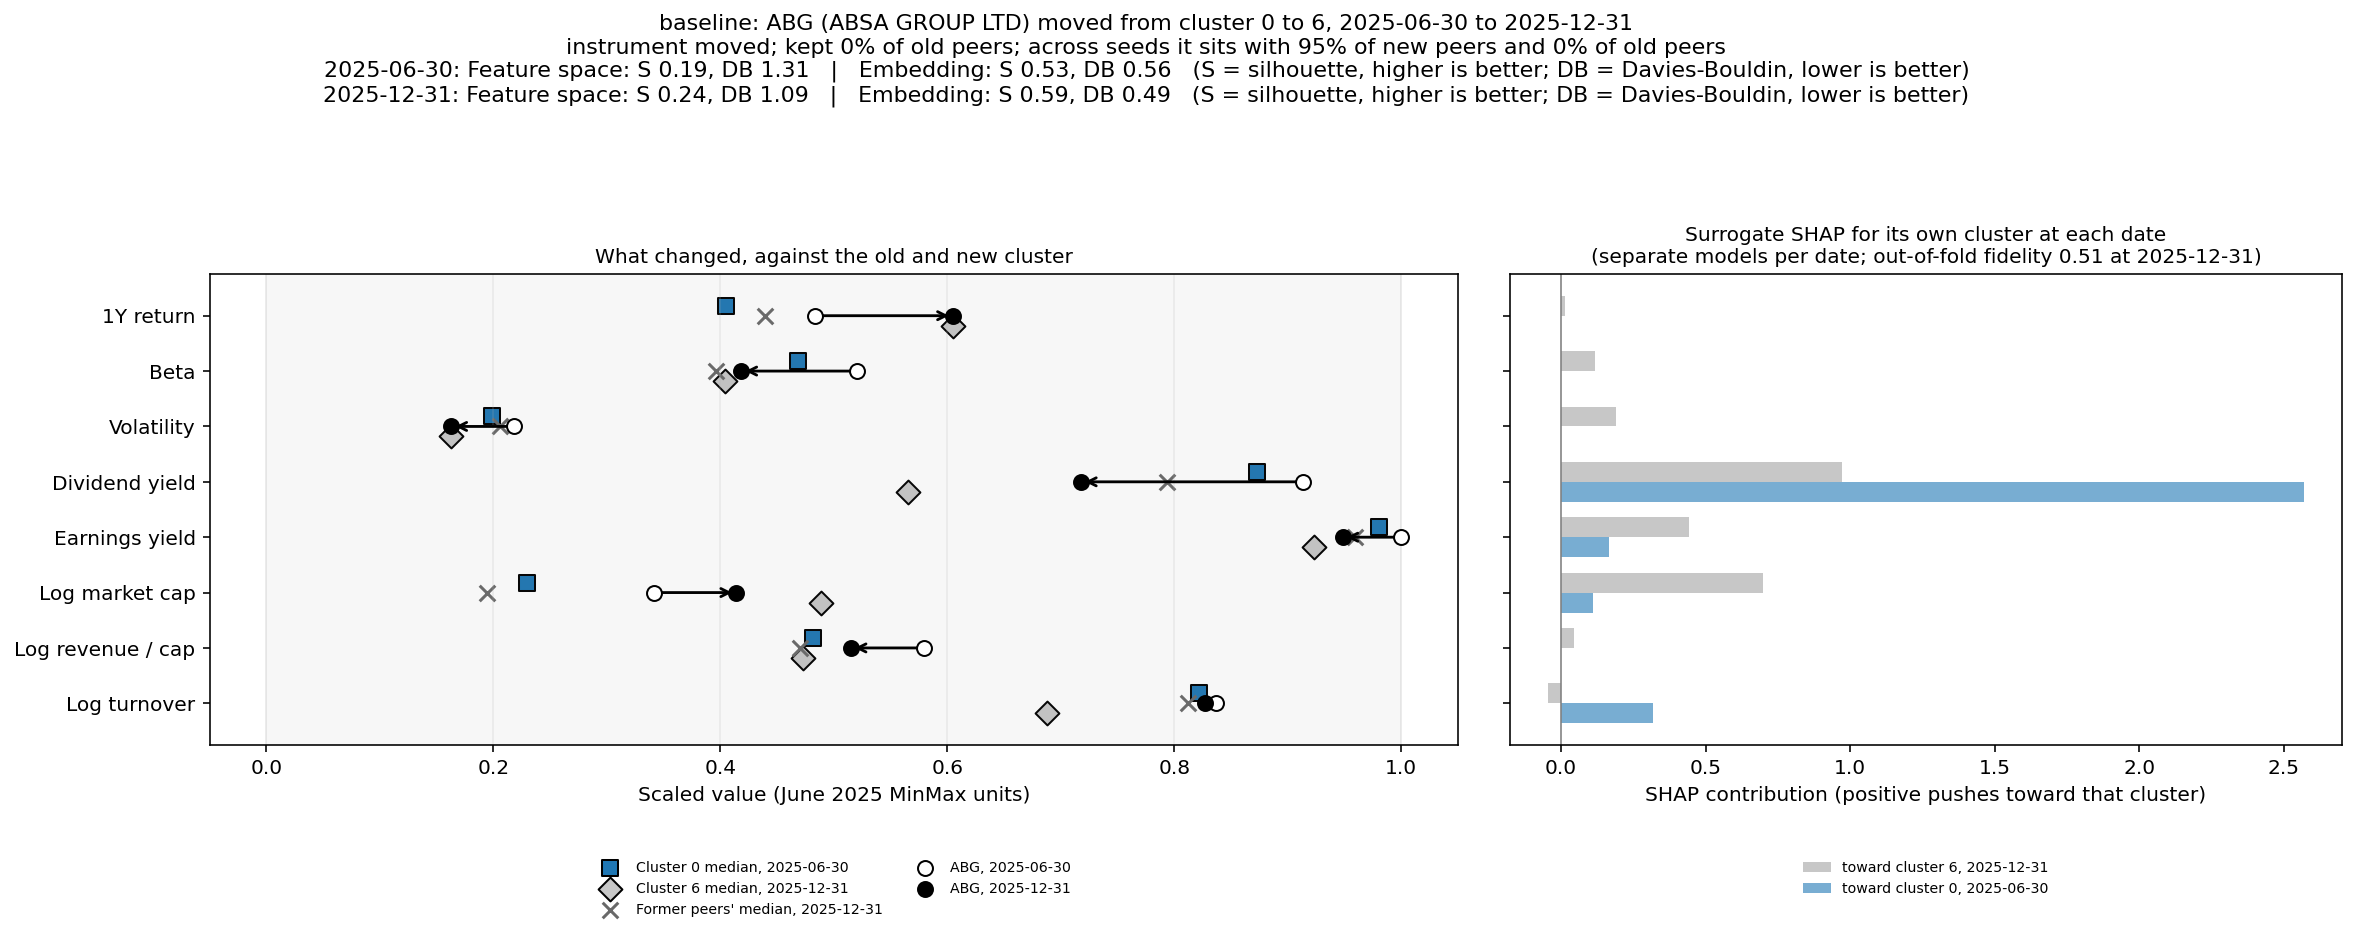

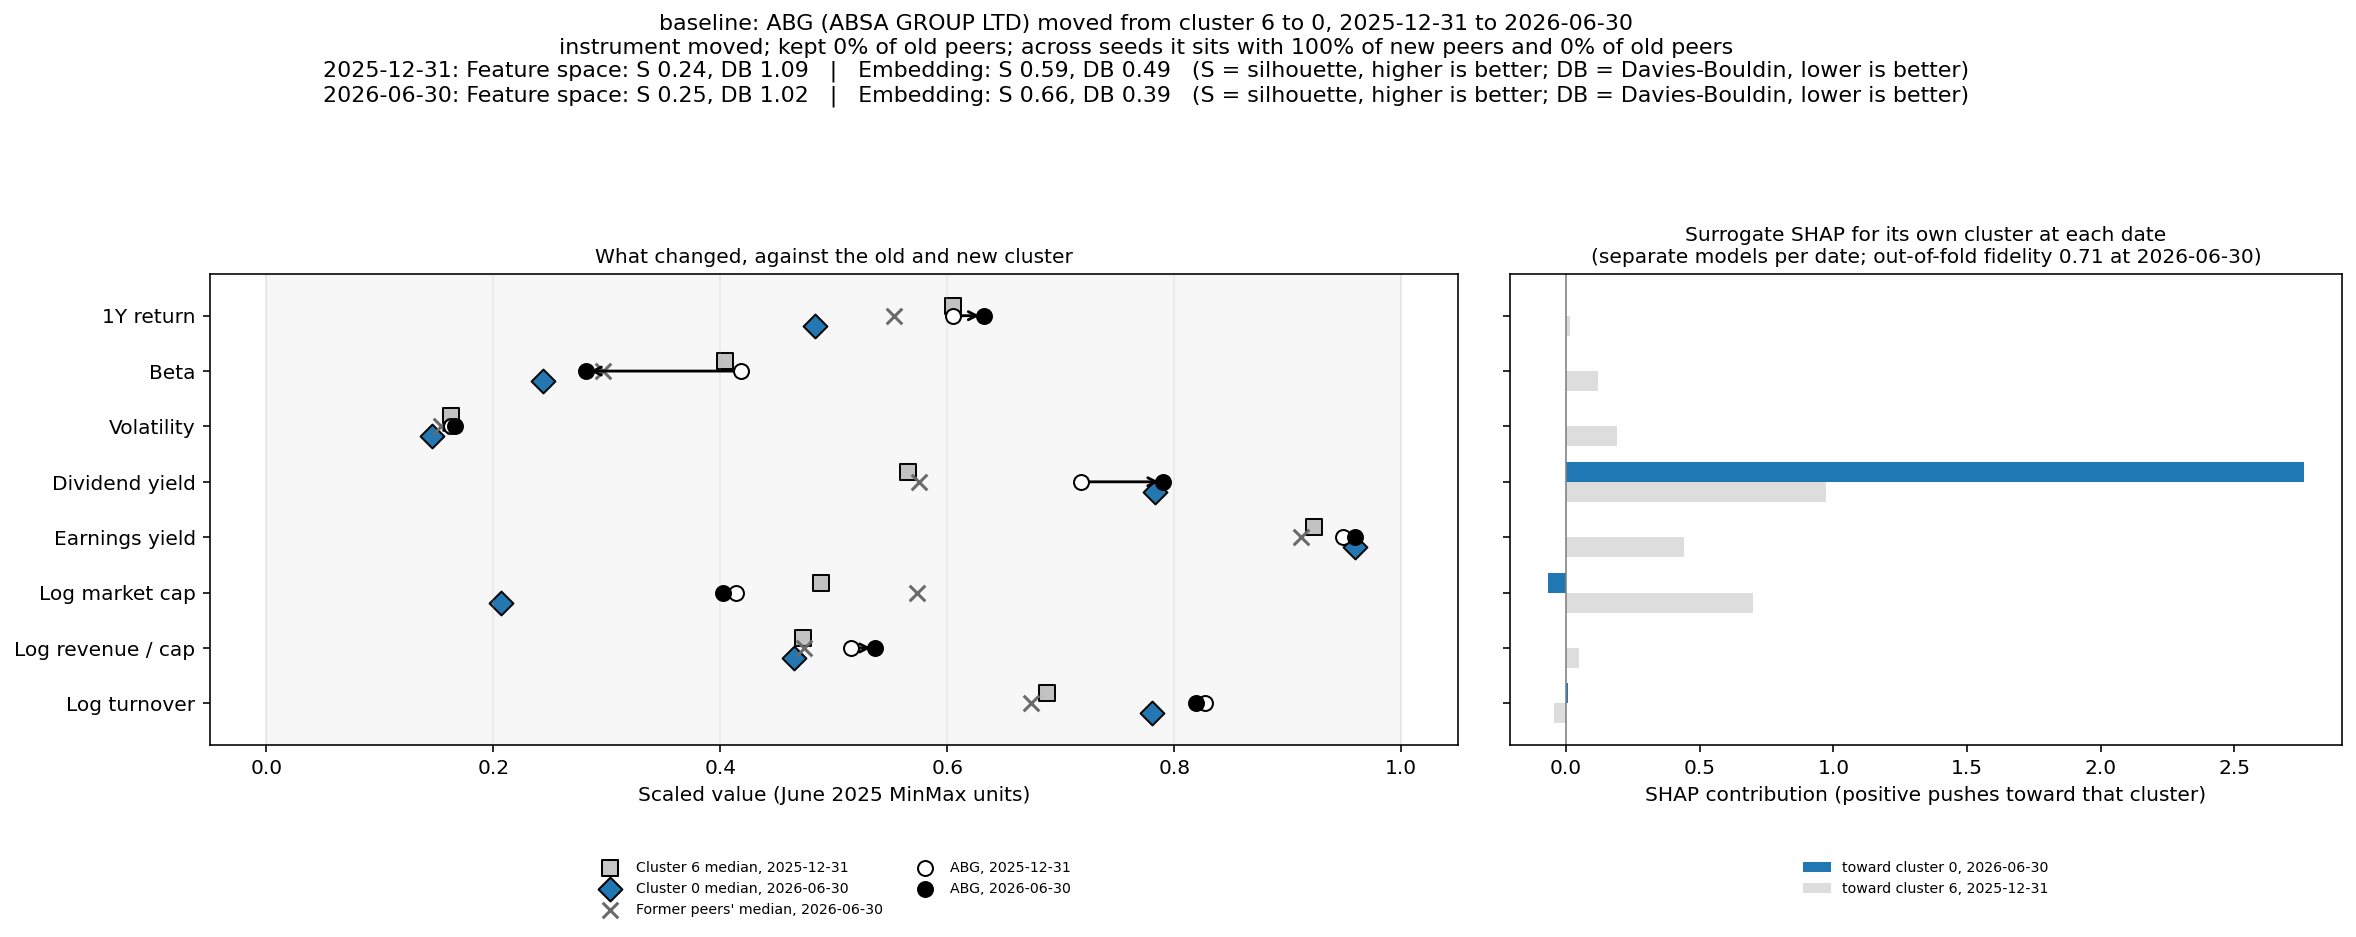

,study_model,decision_date,cluster,n,members,defining_features,shap_top_features,surrogate_oof_accuracy
0,umap_sensitivity,2025-06-30,0,7,"ANG, DSY, GFI, HAR, MTN, OUT, PPH",high 1Y return (+0.39); high Volatility (+0.22...,"1Y return, Dividend yield, Log market cap",0.439024
1,umap_sensitivity,2025-06-30,1,8,"ABG, GRT, INL, INP, NED, NRP, OMU, VAL",high Dividend yield (+0.58); high Earnings yie...,"Dividend yield, Log turnover, Earnings yield",0.439024
2,umap_sensitivity,2025-06-30,2,9,"AGL, APN, BID, BVT, MNP, MRP, SHP, SOL, WHL",low 1Y return (-0.22); high Log revenue / cap ...,"Log revenue / cap, 1Y return, Dividend yield",0.439024
3,umap_sensitivity,2025-06-30,3,3,"IMP, NPH, SSW",high Volatility (+0.74); high Beta (+0.45); hi...,"Log turnover, Beta, Volatility",0.439024
4,umap_sensitivity,2025-06-30,4,4,"ANH, BHG, CFR, PRX",high Log market cap (+0.64); low Log turnover ...,"Log market cap, Earnings yield, 1Y return",0.439024
5,umap_sensitivity,2025-06-30,5,5,"BTI, FSR, SBK, SLM, VOD",high Dividend yield (+0.34); high Log market c...,"Dividend yield, Log market cap, Log turnover",0.439024
6,umap_sensitivity,2025-06-30,6,3,"CLS, REM, RNI",low Beta (-0.15); low Dividend yield (-0.12); ...,"Dividend yield, Log market cap, Volatility",0.439024
7,umap_sensitivity,2025-06-30,7,2,"CPI, NPN",high Log market cap (+0.34); low Log revenue /...,"Log revenue / cap, 1Y return, Volatility",0.439024
8,umap_sensitivity,2025-12-31,0,1,OUT,low Beta (-0.12); low Log market cap (-0.10); ...,"Volatility, Log turnover, 1Y return",NaN
9,umap_sensitivity,2025-12-31,1,5,"GRT, INL, INP, NED, NRP",high Dividend yield (+0.47); low Log market ca...,"Dividend yield, Log turnover, Beta",NaN


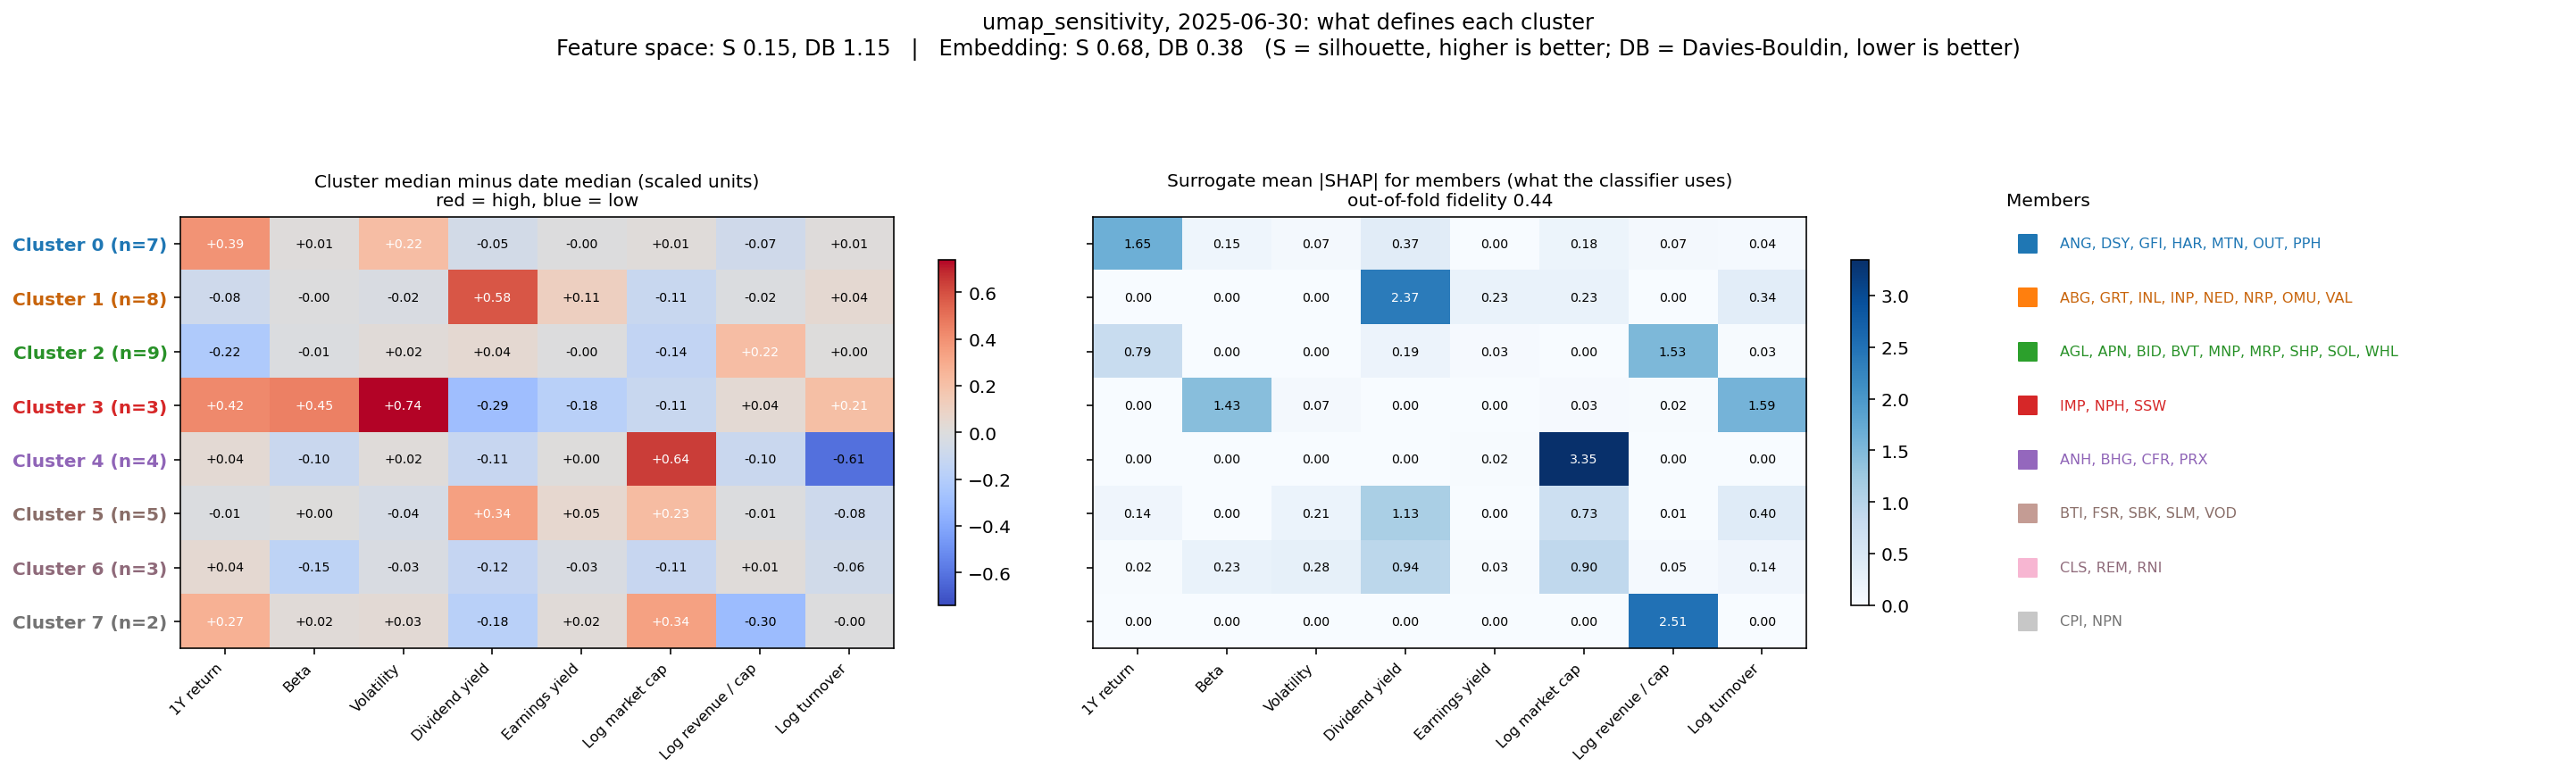

,study_model,ticker,company,sector_label,before,after,from_cluster,to_cluster,move_type,peer_retention,...,peers_kept,new_peers,largest_changes,fits_destination_on,destination_defining_features,shap_toward_destination,support_new_peers,support_old_peers,surrogate_oof_accuracy_after,data_caveat
0,umap_sensitivity,ABG,ABSA GROUP LTD,Financials,2025-06-30,2025-12-31,1,5,instrument moved,0.142857,...,OMU,"FSR, OMU, SBK, SLM, VOD",Dividend yield -0.20; 1Y return +0.12; Beta -0.10,Log market cap; 1Y return; Log revenue / cap,high Dividend yield (+0.26); high Log market c...,Dividend yield +0.98; Earnings yield +0.88; 1Y...,0.680000,0.142857,NaN,NaN
1,umap_sensitivity,AGL,ANGLO AMERICAN PLC,Basic Materials,2025-06-30,2025-12-31,2,7,instrument moved,0.000000,...,NaN,"CPI, DSY, GLN, MTN, NPN, REM, RNI",1Y return +0.27; Dividend yield -0.19; Beta -0.12,Log market cap; 1Y return; Dividend yield,high Log market cap (+0.19); low Dividend yiel...,Dividend yield +1.06; Earnings yield +0.31; Be...,0.628571,0.000000,NaN,volume_imputed
2,umap_sensitivity,ANG,ANGLOGOLD ASHANTI PLC,Basic Materials,2025-06-30,2025-12-31,0,3,instrument moved,0.333333,...,"GFI, HAR","GFI, HAR, IMP, NPH, SSW, VAL",1Y return +1.34; Beta +0.20; Log revenue / cap...,1Y return; Volatility; Log market cap,high 1Y return (+1.45); high Volatility (+0.62...,1Y return +2.93; Beta +0.00; Log market cap +0.00,1.000000,0.333333,NaN,NaN
3,umap_sensitivity,BTI,BRIT AMERICA TOBACO,Consumer Goods,2025-06-30,2025-12-31,5,4,instrument moved,0.000000,...,NaN,"ANH, BHG, CFR, PRX",1Y return -0.09; Dividend yield -0.07; Log rev...,Log market cap; Log turnover; Beta,low Log turnover (-0.62); high Log market cap ...,Log market cap +3.24; Beta +0.05; Log revenue ...,1.000000,0.000000,NaN,NaN
4,umap_sensitivity,CLS,CLICKS GROUP LTD,Consumer Services,2025-06-30,2025-12-31,6,2,instrument moved,0.000000,...,NaN,"BID, BVT, MRP, PPH, SHP, SOL, WHL",1Y return -0.14; Dividend yield +0.10; Log rev...,1Y return; Log turnover; Log market cap,high Log revenue / cap (+0.26); low 1Y return ...,Log revenue / cap +1.29; 1Y return +0.43; Log ...,1.000000,0.000000,NaN,NaN
5,umap_sensitivity,DSY,DISCOVERY LTD,Financials,2025-06-30,2025-12-31,0,7,instrument moved,0.166667,...,MTN,"AGL, CPI, GLN, MTN, NPN, REM, RNI",1Y return -0.34; Volatility +0.06; Beta -0.05,1Y return; Volatility; Beta,high Log market cap (+0.19); low Dividend yiel...,Dividend yield +1.44; Beta +0.43; Log turnover...,0.428571,0.100000,NaN,NaN
6,umap_sensitivity,GFI,GOLD FIELDS LIMITED,Basic Materials,2025-06-30,2025-12-31,0,3,instrument moved,0.333333,...,"ANG, HAR","ANG, HAR, IMP, NPH, SSW, VAL",1Y return +1.14; Beta +0.18; Log revenue / cap...,1Y return; Volatility; Beta,high 1Y return (+1.45); high Volatility (+0.62...,1Y return +2.93; Volatility +0.04; Dividend yi...,1.000000,0.333333,NaN,NaN
7,umap_sensitivity,HAR,HARMONY GOLD MINING,Basic Materials,2025-06-30,2025-12-31,0,3,instrument moved,0.333333,...,"ANG, GFI","ANG, GFI, IMP, NPH, SSW, VAL",1Y return +0.63; Beta +0.16; Volatility +0.08,Volatility; Beta; Dividend yield,high 1Y return (+1.45); high Volatility (+0.62...,1Y return +2.89; Volatility +0.04; Dividend yi...,1.000000,0.333333,NaN,NaN
8,umap_sensitivity,MNP,MONDI PLC,Basic Materials,2025-06-30,2025-12-31,2,8,instrument moved,0.000000,...,NaN,NaN,Dividend yield +0.23; Volatility +0.12; Log ma...,Dividend yield; 1Y return; Beta,high Dividend yield (+0.43); low 1Y return (-0...,Dividend yield +0.82; 1Y return +0.54; Log rev...,NaN,0.685714,NaN,NaN
9,umap_sensitivity,MTN,MTN GROUP LTD,Telecommunications,2025-06-30,2025-12-31,0,7,instrument moved,0.166667,...,DSY,"AGL, CPI, DSY, GLN, NPN, REM, RNI",1Y return +0.15; Beta -0.11; Dividend yield -0.05,Beta; Log revenue / cap; Log market cap,high Log market cap (+0.19); low Dividend yiel...,Earnings yield +0.60; Beta +0.43; Dividend yie...,0.600000,0.066667,NaN,NaN


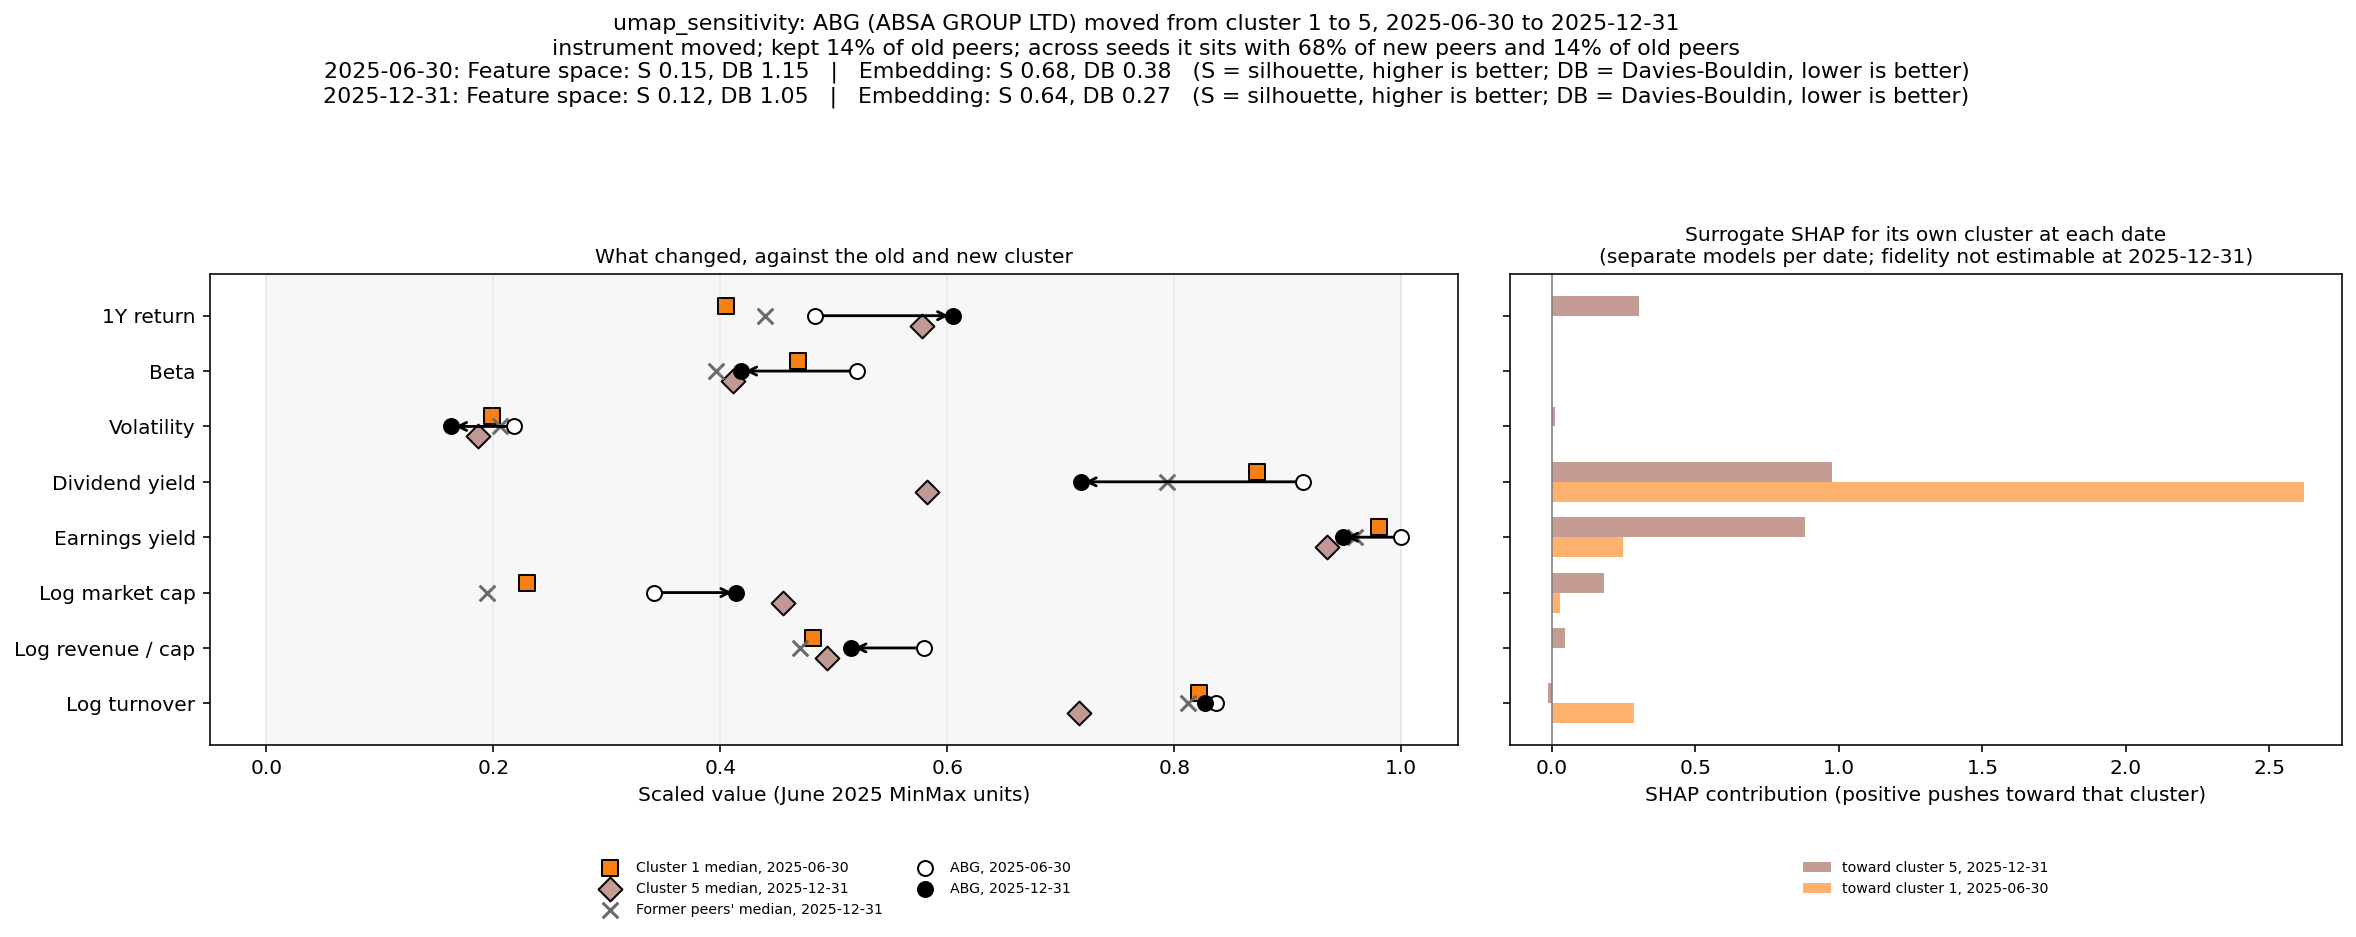

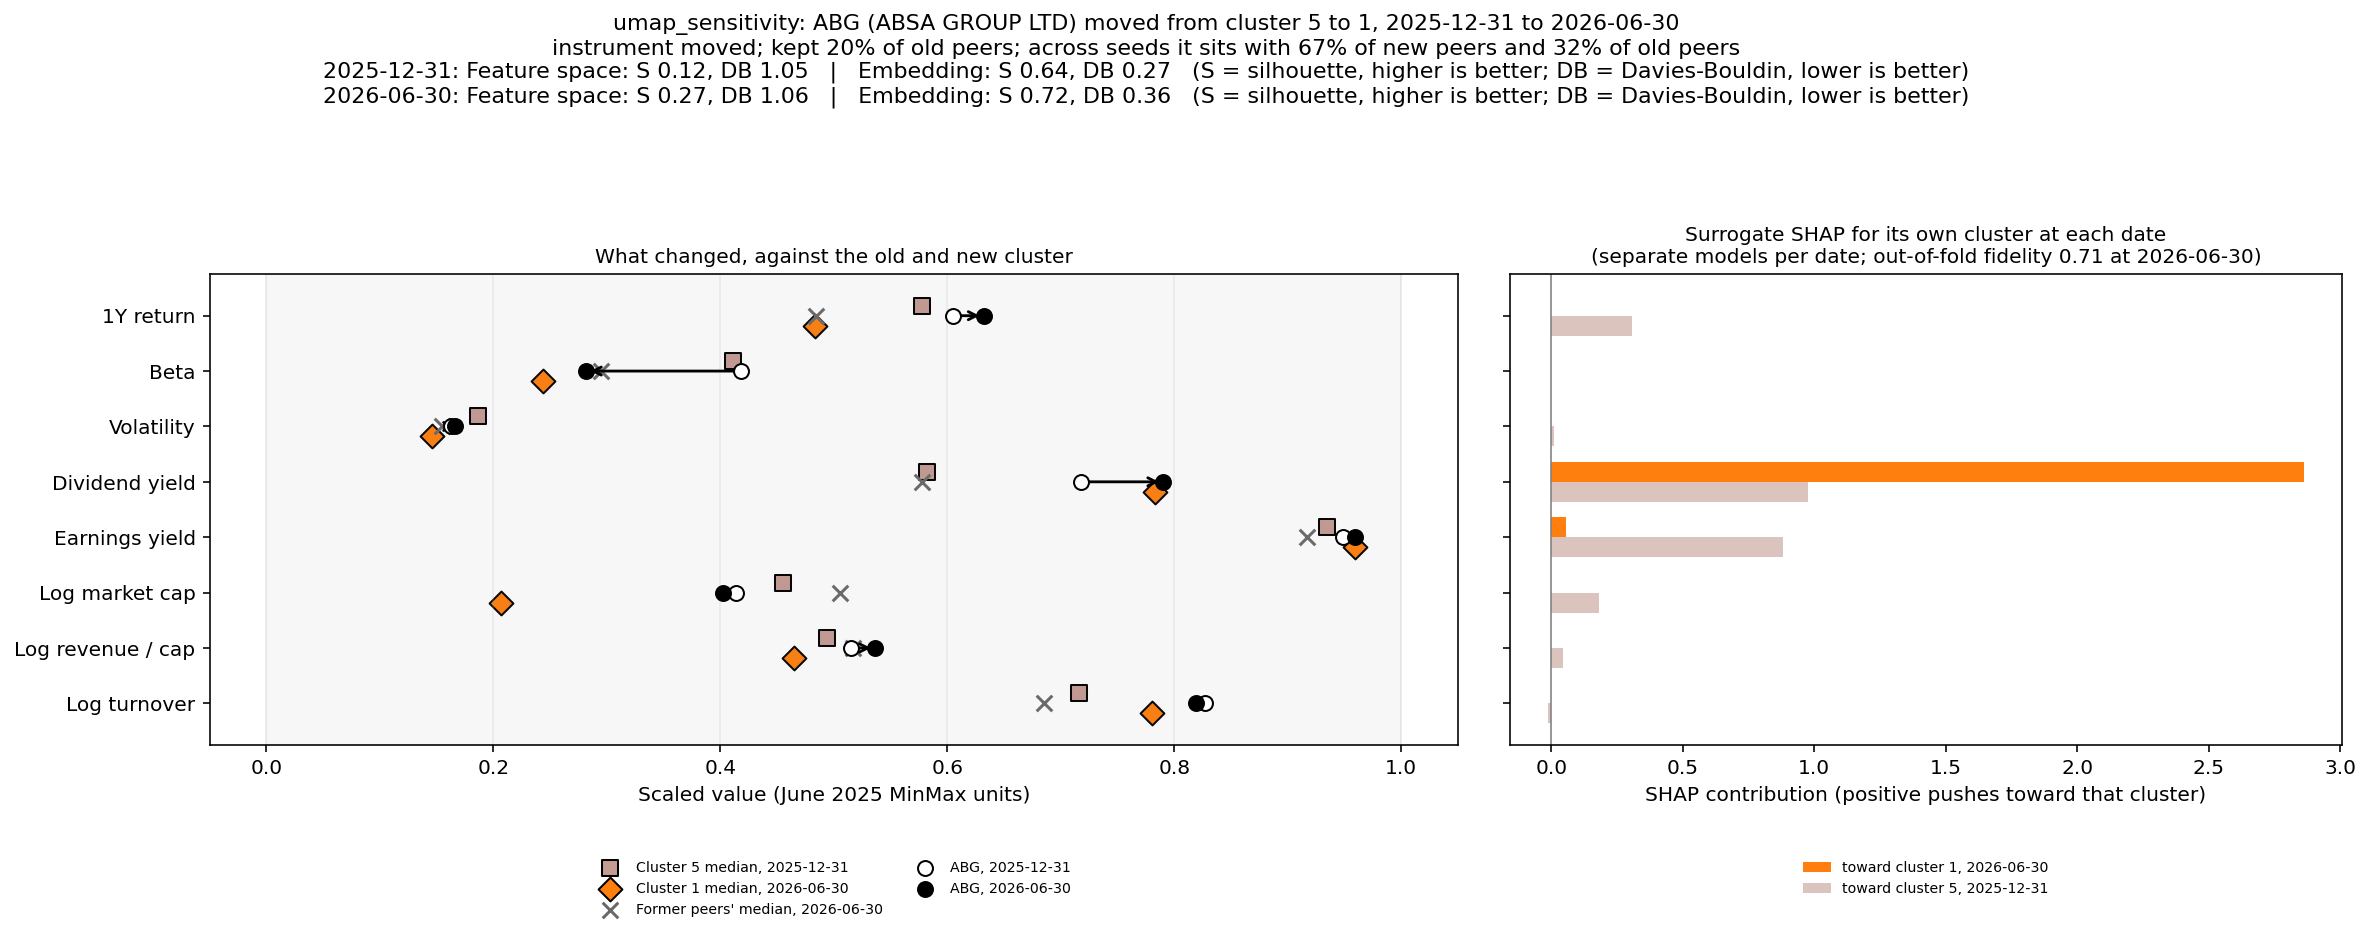

In [12]:
MOVE_TICKER = None   # for example "NPN"; None shows one move per date pair
for name in study.model_folders:
    folder = f"longitudinal/{name}/moves"
    print(name, "cluster definitions")
    profiles = study.table(f"{folder}/cluster_summary.csv")
    display(profiles)
    study.show(f"{folder}/cluster_profiles_{VIEW_DATE}.png")
    moves = study.table(f"{folder}/moves.csv")
    print(name, "all observed aligned-label moves")
    display(moves)
    selected = (moves[moves.ticker == MOVE_TICKER] if MOVE_TICKER else
                moves.groupby(["before", "after"], sort=False).head(1))
    for move in selected.itertuples():
        study.show(f"{folder}/move_{move.before}_{move.after}_{move.ticker}.png")


### Distance screen and sector context

The screen is the squared Mahalanobis distance of each instrument from the same-date mean, in the scaled feature space, against the exact Beta reference for an individual same-sample distance under normality. Equity cross-sections are not normal, so more than 5% will exceed it: read it as a ranking of unusual profiles, not a test. It does not depend on the clustering model.

In [13]:
screens = study.screens
display(screens.groupby("decision_date").agg(flagged=("flag", "sum"), reference=("reference", "first")).round(2))
display(screens[screens.flag == 1].sort_values(["decision_date", "squared_distance"], ascending=[True, False]).round(2))
display(study.table("longitudinal/baseline/sector_context.csv").query("sector_status != 'compared'"))

,flagged,reference
decision_date,,
2025-06-30,5.0,14.03
2025-12-31,5.0,14.03
2026-06-30,4.0,14.03


,decision_date,ticker,squared_distance,reference,flag,status,fundamentals_imputed,volume_imputed,volume_basis_mixed
36,2025-06-30,SOL,32.93,14.03,1.0,descriptive screen,False,False,False
5,2025-06-30,BHG,17.48,14.03,1.0,descriptive screen,False,False,False
4,2025-06-30,APN,17.31,14.03,1.0,descriptive screen,False,False,False
7,2025-06-30,BTI,16.93,14.03,1.0,descriptive screen,False,False,False
38,2025-06-30,VAL,14.47,14.03,1.0,descriptive screen,False,False,False
77,2025-12-31,SOL,24.33,14.03,1.0,descriptive screen,False,False,False
47,2025-12-31,BTI,16.49,14.03,1.0,descriptive screen,False,False,False
45,2025-12-31,BHG,15.45,14.03,1.0,descriptive screen,False,False,False
78,2025-12-31,SSW,14.51,14.03,1.0,descriptive screen,False,False,False
42,2025-12-31,AGL,14.37,14.03,1.0,descriptive screen,False,True,False


,ticker,cluster,sector_label,cluster_size,other_member_majority,sector_divergence,sector_status,decision_date
21,MRP,3,Consumer Services,5,Basic Materials; Consumer Services; Health Car...,NaN,tied majority,2025-06-30
25,NPN,5,Technology,3,Financials; Technology,NaN,tied majority,2025-06-30
30,PRX,5,Technology,3,Financials; Technology,NaN,tied majority,2025-06-30
40,WHL,3,Consumer Services,5,Basic Materials; Consumer Services; Health Car...,NaN,tied majority,2025-06-30
42,AGL,2,Basic Materials,5,Basic Materials; Financials; Technology; Telec...,NaN,tied majority,2025-12-31
55,GLN,2,Basic Materials,5,Basic Materials; Financials; Technology; Telec...,NaN,tied majority,2025-12-31
85,ANH,0,Consumer Goods,6,Consumer Goods; Technology,NaN,tied majority,2026-06-30
88,BTI,0,Consumer Goods,6,Consumer Goods; Technology,NaN,tied majority,2026-06-30
90,CFR,0,Consumer Goods,6,Consumer Goods; Technology,NaN,tied majority,2026-06-30
109,OUT,7,Financials,3,Financials; Telecommunications,NaN,tied majority,2026-06-30


## 7. Finish the run

The run is marked completed only after every expected output exists. `summary.md` in the run folder collects the main tables.

In [14]:
from IPython.display import Markdown
run_folder = study.finish()
display(Markdown((run_folder / "summary.md").read_text(encoding="utf-8")))

# Three-cross-section study

Run `20261114T135303-1af915a99076`. Feature set **invariant8** (pilot-informed candidate): No feature changes under a share subdivision: five scale-free measures, log market cap, log revenue-to-cap and log share turnover.

123 instrument-date rows over 3 dates; scaling fitted on 2025-06-30 only; k=8; seeds 42-46. Each date is clustered independently. These are overlapping cross-sections of mostly the same firms, not independent samples, and nothing here is a return prediction.

## Feature validity (`feature_audit/`)

Largest single-feature share of scaled variance. A share far above the even share means one feature drives the geometry at that date.

| feature_set | decision_date | top_feature_label | top_variance_share | even_share | max_scaled_value |
| --- | --- | --- | --- | --- | --- |
| original10 | 2025-06-30 | Dividend yield | 0.159 | 0.100 | 1.000 |
| original10 | 2025-12-31 | 1Y return | 0.327 | 0.100 | 3.631 |
| original10 | 2026-06-30 | Revenue | 0.347 | 0.100 | 3.852 |
| logsize10 | 2025-06-30 | Dividend yield | 0.159 | 0.100 | 1.000 |
| logsize10 | 2025-12-31 | 1Y return | 0.467 | 0.100 | 2.847 |
| logsize10 | 2026-06-30 | Volatility | 0.182 | 0.100 | 1.311 |
| invariant8 | 2025-06-30 | Dividend yield | 0.198 | 0.125 | 1.000 |
| invariant8 | 2025-12-31 | 1Y return | 0.525 | 0.125 | 2.847 |
| invariant8 | 2026-06-30 | Volatility | 0.221 | 0.125 | 1.244 |
| market5 | 2025-06-30 | Dividend yield | 0.304 | 0.200 | 1.000 |
| market5 | 2025-12-31 | 1Y return | 0.676 | 0.200 | 2.847 |
| market5 | 2026-06-30 | Volatility | 0.335 | 0.200 | 1.244 |

Instruments observed at all dates, by whether their aligned cluster ever changed:

| feature_set | recipe | stable | shifted | membership gap |
| --- | --- | --- | --- | --- |
| original10 | tsne_hierarchical | 21 | 18 | 4 |
| original10 | ward_features | 26 | 13 | 4 |
| logsize10 | tsne_hierarchical | 20 | 19 | 4 |
| logsize10 | ward_features | 23 | 16 | 4 |
| invariant8 | tsne_hierarchical | 22 | 17 | 4 |
| invariant8 | ward_features | 20 | 19 | 4 |
| market5 | tsne_hierarchical | 17 | 22 | 4 |
| market5 | ward_features | 6 | 33 | 4 |

Silhouette and Davies-Bouldin are computed in each feature set's own space and cannot be compared across feature sets. See `feature_audit/quality.csv`, `cross_set_agreement.csv` and `share_basis.csv`.

## Primary models (`models/`)

| study_model | decision_date | smallest_cluster | largest_cluster | singleton_clusters | silhouette_features | davies_bouldin_features | silhouette_embedding | davies_bouldin_embedding | mean_seed_ari | in_sample_accuracy | oof_accuracy |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| baseline | 2025-06-30 | 3 | 8 | 0 | 0.195 | 1.307 | 0.532 | 0.561 | 0.658 | 1.000 | 0.683 |
| baseline | 2025-12-31 | 2 | 7 | 0 | 0.240 | 1.094 | 0.589 | 0.494 | 0.925 | 1.000 | 0.512 |
| baseline | 2026-06-30 | 2 | 8 | 0 | 0.255 | 1.016 | 0.656 | 0.390 | 0.894 | 1.000 | 0.707 |
| umap_sensitivity | 2025-06-30 | 2 | 9 | 0 | 0.151 | 1.153 | 0.685 | 0.385 | 0.846 | 1.000 | 0.439 |
| umap_sensitivity | 2025-12-31 | 1 | 8 | 2 | 0.124 | 1.049 | 0.638 | 0.268 | 0.892 | 1.000 | n/a |
| umap_sensitivity | 2026-06-30 | 2 | 8 | 0 | 0.267 | 1.059 | 0.721 | 0.355 | 0.738 | 1.000 | 0.707 |

Surrogate fidelity is agreement with the cluster labels, not predictive validity. Out-of-fold fidelity is not estimable when a cluster has one member.

## Across dates (`longitudinal/`)

| study_model | before | after | continuing | entries | exits | ari | changed |
| --- | --- | --- | --- | --- | --- | --- | --- |
| baseline | 2025-06-30 | 2025-12-31 | 40 | 1 | 1 | 0.556 | 9 |
| baseline | 2025-12-31 | 2026-06-30 | 40 | 1 | 1 | 0.660 | 9 |
| umap_sensitivity | 2025-06-30 | 2025-12-31 | 40 | 1 | 1 | 0.377 | 15 |
| umap_sensitivity | 2025-12-31 | 2026-06-30 | 40 | 1 | 1 | 0.590 | 11 |

A changed label is not yet evidence of a changed firm: compare `changed` with the seed agreement above, which is the only noise reference this run computes.

Feature-space distance screen (descriptive, alpha=0.05): APN 2025-06-30, BHG 2025-06-30, BTI 2025-06-30, SOL 2025-06-30, VAL 2025-06-30, AGL 2025-12-31, BHG 2025-12-31, BTI 2025-12-31, SOL 2025-12-31, SSW 2025-12-31, GLN 2026-06-30, PAN 2026-06-30, SOL 2026-06-30, SSW 2026-06-30.

## Known data limits

- Historical share counts, market capitalisation and sector labels are reconstructed, not verified point-in-time.
- Reinet fundamentals and two Anglo American volume observations are imputed with June 2025 medians.
- Investec line share counts split the combined count by fractions disclosed in June 2024 and June 2026; December 2025 uses their midpoint.
- Volume is JSE trading only, so turnover understates liquidity for companies whose main listing is abroad.


## What this does and does not establish

- The clusters are descriptive groupings of reconstructed, partly unverified inputs. Share counts, market capitalisation and sector labels are not verified point-in-time.
- No external validation is done here. The planned test is whether clusters formed at one date explain return co-movement over the following six months better than sector labels; that needs daily prices, which are not in this repository.
- The noise reference is seed agreement only. A perturbation-based noise floor (resampling instruments) is still to be added.